In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import scipy.stats
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d
from matplotlib.patches import Polygon
import matplotlib.colors as mcolors
from scipy.optimize import fsolve
from scipy import interpolate
import math
#from matplotlib import labellines
# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

In [2]:
from math import atan2,degrees
import numpy as np

#Label line with line2D label data
def labelLine(line,x,label=None,align=True,**kwargs):

    ax = line.axes
    xdata = line.get_xdata()
    ydata = line.get_ydata()

    if (x < xdata[0]) or (x > xdata[-1]):
        print('x label location is outside data range!')
        return

    #Find corresponding y co-ordinate and angle of the line
    ip = 1
    for i in range(len(xdata)):
        if x < xdata[i]:
            ip = i
            break

    y = ydata[ip-1] + (ydata[ip]-ydata[ip-1])*(x-xdata[ip-1])/(xdata[ip]-xdata[ip-1])

    if not label:
        label = line.get_label()

    if align:
        #Compute the slope
        dx = xdata[ip] - xdata[ip-1]
        dy = ydata[ip] - ydata[ip-1]
        ang = degrees(atan2(dy,dx))

        #Transform to screen co-ordinates
        pt = np.array([x,y]).reshape((1,2))
        trans_angle = ax.transData.transform_angles(np.array((ang,)),pt)[0]

    else:
        trans_angle = 0

    #Set a bunch of keyword arguments
    if 'color' not in kwargs:
        kwargs['color'] = line.get_color()

    if ('horizontalalignment' not in kwargs) and ('ha' not in kwargs):
        kwargs['ha'] = 'center'

    if ('verticalalignment' not in kwargs) and ('va' not in kwargs):
        kwargs['va'] = 'center'

    if 'backgroundcolor' not in kwargs:
        kwargs['backgroundcolor'] = ax.get_facecolor()

    if 'clip_on' not in kwargs:
        kwargs['clip_on'] = True

    if 'zorder' not in kwargs:
        kwargs['zorder'] = 2.5

    ax.text(x,y,label,rotation=trans_angle,**kwargs)

def labelLines(lines,align=True,xvals=None,**kwargs):

    ax = lines[0].axes
    labLines = []
    labels = []

    #Take only the lines which have labels other than the default ones
    for line in lines:
        label = line.get_label()
        if "_line" not in label:
            labLines.append(line)
            labels.append(label)

    if xvals is None:
        xmin,xmax = ax.get_xlim()
        xvals = np.linspace(xmin,xmax,len(labLines)+2)[1:-1]

    for line,x,label in zip(labLines,xvals,labels):
        labelLine(line,x,label,align,**kwargs)

In [3]:
#plt.rcParams['figure.facecolor'] = 'w'
plt.rcParams['figure.edgecolor'] = 'w'

In [4]:
mcolors.CSS4_COLORS

{'aliceblue': '#F0F8FF',
 'antiquewhite': '#FAEBD7',
 'aqua': '#00FFFF',
 'aquamarine': '#7FFFD4',
 'azure': '#F0FFFF',
 'beige': '#F5F5DC',
 'bisque': '#FFE4C4',
 'black': '#000000',
 'blanchedalmond': '#FFEBCD',
 'blue': '#0000FF',
 'blueviolet': '#8A2BE2',
 'brown': '#A52A2A',
 'burlywood': '#DEB887',
 'cadetblue': '#5F9EA0',
 'chartreuse': '#7FFF00',
 'chocolate': '#D2691E',
 'coral': '#FF7F50',
 'cornflowerblue': '#6495ED',
 'cornsilk': '#FFF8DC',
 'crimson': '#DC143C',
 'cyan': '#00FFFF',
 'darkblue': '#00008B',
 'darkcyan': '#008B8B',
 'darkgoldenrod': '#B8860B',
 'darkgray': '#A9A9A9',
 'darkgreen': '#006400',
 'darkgrey': '#A9A9A9',
 'darkkhaki': '#BDB76B',
 'darkmagenta': '#8B008B',
 'darkolivegreen': '#556B2F',
 'darkorange': '#FF8C00',
 'darkorchid': '#9932CC',
 'darkred': '#8B0000',
 'darksalmon': '#E9967A',
 'darkseagreen': '#8FBC8F',
 'darkslateblue': '#483D8B',
 'darkslategray': '#2F4F4F',
 'darkslategrey': '#2F4F4F',
 'darkturquoise': '#00CED1',
 'darkviolet': '#9400D3

In [5]:
M0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundMStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip
M1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneMStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C0StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundamentalCStarData.csv',delimiter=',',skip_header=0))) # Has header, so skip
C1StarData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FirstOvertoneCStarData.csv',delimiter=',',skip_header=0))) # No header, so don't skip

print(np.shape(M0StarData))
print(np.shape(M1StarData))
print(np.shape(C0StarData))
print(np.shape(C1StarData))




MdotIndex=5 # Column of imported files that has Mdot data
MdotErrorIndex=6 # Absolute error in Mdot
MdotDustIndex=2 # Column of imported files that has Mdot_dust Data
LIndex=8 # Column of imported files that has LBol data
LErrorIndex=9 # Absolute error in L
PIndex=13 # Column of imported files that has Period data
JIndex=14 # Column of imported files that has J-band magnitude
HIndex=15 # Column of imported files that has J-band magnitude
KIndex=16 # Column of imported files that has J-band magnitude
ThreePointSixIndex=17 # Column of imported files that has 3.6 band magnitude
FourPointFiveIndex=18 # Column of imported files that has 3.6 band magnitude
FivePointEightIndex=19 # Column of imported files that has 3.6 band magnitude
EightPointZeroIndex=20 # Column of imported files that has 8.0 band magnitude
MIndex=22 # Column of imported files that has Mass data
RIndex=23 # Column of imported files that has Radius data
TeffObsvIndex=12 # Column of imported files that has Observed Teff Data
TeffCalcIndex=24 # Column of imported files that has Calculated Teff Data
tauIndex=27 # Column of imported files that has Optical Depth data
AmpIndex=28 # Column of imported files that has pulsation amplitude data

(29, 1979)
(29, 2162)
(29, 1994)
(29, 781)


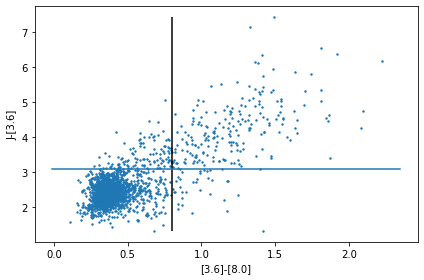

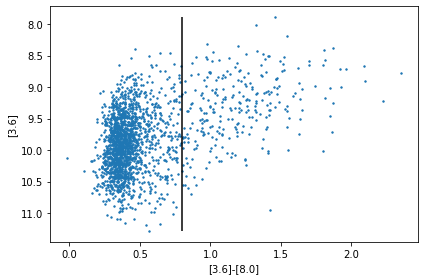

Non-sortable star found at index  226 . Assumed to not be extreme.
Non-sortable star found at index  242 . Assumed to not be extreme.
Non-sortable star found at index  249 . Assumed to not be extreme.
Non-sortable star found at index  747 . Assumed to not be extreme.
Non-sortable star found at index  916 . Assumed to not be extreme.
Non-sortable star found at index  1034 . Assumed to not be extreme.
Non-sortable star found at index  1188 . Assumed to not be extreme.
Non-sortable star found at index  1330 . Assumed to not be extreme.
Non-sortable star found at index  1338 . Assumed to not be extreme.
Non-sortable star found at index  1384 . Assumed to not be extreme.
Non-sortable star found at index  1596 . Assumed to not be extreme.


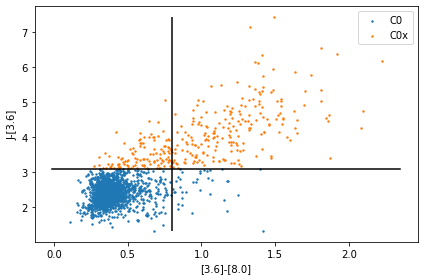

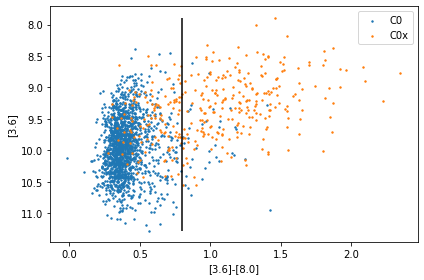

In [6]:
def sort_xC0(stellar_data): # Function to separate 'extreme' AGB stars from the carbon star population
    '''
    “As in Blum et al. (2006) and Srinivasan et al. (2009), we identify x-AGB stars as those brighter than the 3.6 μm TRGB and 
    with J −[3.6] > 3.1 mag. Some of the most heavily dust-enshrouded x-AGB stars are totally undetected in the near-IR. 
    Therefore, if there is no near-IR detection, but [3.6] − [8] > 0.8 and the star is brighter than the 3.6 μm TRGB, then it is
    also included in the initial list of x-AGB stars.” 
    - Boyer et. al, 2011 https://iopscience.iop.org/article/10.1088/0004-6256/142/4/103/pdf
    '''
    mag_J = stellar_data[JIndex]
    mag_36 = stellar_data[ThreePointSixIndex]
    mag_8 = stellar_data[EightPointZeroIndex]
    cut_line_1 = np.asarray([3.1,3.1])
    line_coords_1 = np.asarray([np.nanmin(mag_36 - mag_8),np.nanmax(mag_36 - mag_8)])
    # Plot 1: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_J - mag_36,s=2)
    plot.plot(line_coords_1, cut_line_1)
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Plot 2: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36 - mag_8, mag_36,s=2)
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.show()
    plot.close()
    
    # Now, the acutal sorting function
    normal_indices = []
    extreme_indices = []
    for i in range(0,np.shape(stellar_data)[1]): # Iterate over every entry in stellar_data
        if np.isnan(mag_J[i]) == False and np.isnan(mag_36[i]) == False: # If there is an entry for J and [3.6]
            if mag_J[i]-mag_36[i] > 3.1: # Stars bluer than this should be classified as extreme
                extreme_indices.append(i)
            else: # Otherwise they are not
                normal_indices.append(i)
        elif np.isnan(mag_36[i]) == False and np.isnan(mag_8[i]) == False: # If there is an entry for [3.6] and [8.0]
            if mag_36[i]-mag_8[i]>0.8:
                extreme_indices.append(i)
            else:
                normal_indices.append(i)
        else:
            normal_indices.append(i)
            print('Non-sortable star found at index ',i,'. Assumed to not be extreme.')
    
    norm_array = []
    extr_array = []
    for i in range(0, len(normal_indices)):
        norm_array.append(np.transpose(stellar_data)[normal_indices[i]])
    np_norm_array = np.asarray(norm_array)
    for i in range(0, len(extreme_indices)):
        extr_array.append(np.transpose(stellar_data)[extreme_indices[i]])
    np_extr_array = np.asarray(extr_array)
    
    mag_J_n = np.transpose(np_norm_array)[JIndex]
    mag_36_n = np.transpose(np_norm_array)[ThreePointSixIndex]
    mag_8_n = np.transpose(np_norm_array)[EightPointZeroIndex]
    mag_J_x = np.transpose(np_extr_array)[JIndex]
    mag_36_x = np.transpose(np_extr_array)[ThreePointSixIndex]
    mag_8_x = np.transpose(np_extr_array)[EightPointZeroIndex]
    
    # Plot 3: CCD of J-[3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_J_n - mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_J_x - mag_36_x,s=2,label='C0x')
    plot.plot(line_coords_1, cut_line_1,color='black')
    plot.vlines(0.8,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36))
    #plot.vlines(0.7,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_J - mag_36),np.nanmax(mag_J - mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('J-[3.6]')
    plot.legend()
    #plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_main.pdf',format='pdf')
    plot.show()
    plot.close()
    
    # Plot 4: CMD of [3.6] vs [3.6]-[8.0], with cutline 1
    plot.scatter(mag_36_n - mag_8_n, mag_36_n,s=2,label='C0')
    plot.scatter(mag_36_x - mag_8_x, mag_36_x,s=2,label='C0x')
    plot.vlines(0.8,np.nanmin(mag_36),np.nanmax(mag_36))
    #plot.vlines(0.7,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    #plot.vlines(0.6,np.nanmin(mag_36),np.nanmax(mag_36),linestyles='--')
    plot.xlabel('[3.6]-[8.0]')
    plot.ylabel('[3.6]')
    plot.legend()
    plt.gca().invert_yaxis()
    #plt.gca().invert_xaxis()
    plot.tight_layout()
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.png',format='png')
    plot.savefig('Single_Parameter_Fits/carbon_star_split_secondary.pdf',format='pdf')
    plot.show()
    plot.close()
    
    return np.transpose(np_norm_array), np.transpose(np_extr_array)


C0StarData_n,C0StarData_x  = sort_xC0(C0StarData)

In [7]:
def period_error_estimate (star_data, PIndex):
    PData = star_data[PIndex]
    PData_over = (1/PData+0.00003)**-1
    PData_under = (1/PData-0.00003)**-1
    max_over, min_over, median_over = np.nanmax(PData_over),np.nanmin(PData_over),np.nanmedian(PData_over)
    max_under, min_under, median_under = np.nanmax(PData_under),np.nanmin(PData_under),np.nanmedian(PData_under)
    print('Over Nominal Max/Min/Median:', max_over, ', ', min_over, ', ', median_over)
    print('Under Nominal Max/Min/Median, Relative:', 1-max_over/np.nanmax(PData), ', ', 1-min_over/np.nanmin(PData), ', ', 1-median_over/np.nanmedian(PData))
    print('Over Nominal Max/Min/Median:', max_under, ', ', min_under, ', ', median_under)
    print('Under Nominal Max/Min/Median, Relative:', 1-max_under/np.nanmax(PData), ', ', 1-min_under/np.nanmin(PData), ', ', 1-median_under/np.nanmedian(PData))

In [8]:
def mdot_stats (star_data, MdotIndex):
    MdotData = star_data[MdotIndex]
    print('Max.:', np.nanmax(MdotData),', log10()=,',np.log10(np.nanmax(MdotData)))
    print('Min.:', np.nanmin(MdotData),', log10()=,',np.log10(np.nanmin(MdotData)))
    print('Mean:', np.nanmean(MdotData),', log10()=,',np.log10(np.nanmean(MdotData)))
    print('Median:', np.nanmedian(MdotData),', log10()=,',np.log10(np.nanmedian(MdotData)))
    print('Std. Dev.', np.nanstd(np.log10(MdotData)))

In [9]:
print(np.nanmin(M0StarData[PIndex]), np.nanmax(M0StarData[PIndex]))
period_error_estimate (M0StarData, PIndex)

80.645 335.008
Over Nominal Max/Min/Median: 331.67459076095065 ,  80.4503624156896 ,  161.1342885818707
Under Nominal Max/Min/Median, Relative: 0.009950237722828548 ,  0.002413510872470659 ,  0.00483402865745608
Over Nominal Max/Min/Median: 338.40909259880016 ,  80.84058166124213 ,  162.70735259229056
Under Nominal Max/Min/Median, Relative: -0.010152272777963933 ,  -0.002425217449837369 ,  -0.00488122057776863


In [10]:
print(np.nanmin(M1StarData[PIndex]), np.nanmax(M1StarData[PIndex]))
period_error_estimate (M1StarData, PIndex)

32.141 330.907
Over Nominal Max/Min/Median: 327.65430688811716 ,  32.110038537540945 ,  90.79352063282965
Under Nominal Max/Min/Median, Relative: 0.009829629206643653 ,  0.000963301156126195 ,  0.0027238058157031952
Over Nominal Max/Min/Median: 334.2249209777798 ,  32.1720212280287 ,  91.29083766201647
Under Nominal Max/Min/Median, Relative: -0.010026747629333421 ,  -0.0009651606368408228 ,  -0.002738725328739866


In [11]:
print(np.nanmin(C0StarData[PIndex]), np.nanmax(C0StarData[PIndex]))
period_error_estimate (C0StarData, PIndex)

147.842 817.661
Over Nominal Max/Min/Median: 798.0841319183454 ,  147.18917772759193 ,  325.4148360103729
Under Nominal Max/Min/Median, Relative: 0.023942523957550255 ,  0.004415675331827851 ,  0.00976244508031121
Over Nominal Max/Min/Median: 838.2224543063168 ,  148.50063894388225 ,  331.89505041457164
Under Nominal Max/Min/Median, Relative: -0.025146673629189653 ,  -0.004455019168316365 ,  -0.009956851512437304


In [12]:
print(np.nanmin(C1StarData[PIndex]), np.nanmax(C1StarData[PIndex]))
period_error_estimate (C1StarData, PIndex)

93.589 570.451
Over Nominal Max/Min/Median: 560.8528282973485 ,  93.32696866987465 ,  166.19621238524516
Under Nominal Max/Min/Median, Relative: 0.016825584848920383 ,  0.0027998090600963588 ,  0.00498588637155728
Over Nominal Max/Min/Median: 580.3834088793592 ,  93.85250686795796 ,  167.87017562694376
Under Nominal Max/Min/Median, Relative: -0.017411502266380774 ,  -0.0028155752060388117 ,  -0.005036105268808155


In [13]:
all_data = np.hstack([M0StarData, M1StarData, C0StarData, C1StarData])
print(np.nanmin(all_data[PIndex]), np.nanmax(all_data[PIndex]))
period_error_estimate (all_data, PIndex)

32.141 817.661
Over Nominal Max/Min/Median: 798.0841319183454 ,  32.110038537540945 ,  162.9995178393151
Under Nominal Max/Min/Median, Relative: 0.023942523957550255 ,  0.000963301156126195 ,  0.004889986054284923
Over Nominal Max/Min/Median: 838.2224543063168 ,  32.1720212280287 ,  164.6093931136189
Under Nominal Max/Min/Median, Relative: -0.025146673629189653 ,  -0.0009651606368408228 ,  -0.004938282322818788


In [14]:
mdot_stats(M0StarData, MdotIndex)

Max.: 3.5290208811625103e-06 , log10()=, -5.45234577191863
Min.: 7.058041762324992e-09 , log10()=, -8.15131577625465
Mean: 2.47482263338151e-07 , log10()=, -6.606455920812798
Median: 1.8350908582045064e-07 , log10()=, -6.73634242828383
Std. Dev. 0.39124997212431056


In [15]:
mdot_stats(M1StarData, MdotIndex)

Max.: 5.364111739367005e-06 , log10()=, -5.270502183973858
Min.: 5.222950904120495e-09 , log10()=, -8.282084056523674
Mean: 2.1846617595426466e-07 , log10()=, -6.660615793171907
Median: 1.3127957677924558e-07 , log10()=, -6.8818028320367315
Std. Dev. 0.4433553510690238


In [16]:
mdot_stats(C0StarData, MdotIndex)

Max.: 2.160218438459158e-05 , log10()=, -4.665502331339397
Min.: 2.117014069689976e-08 , log10()=, -7.674276255646902
Mean: 6.358547722280381e-07 , log10()=, -6.196642064889543
Median: 2.3762402823050756e-07 , log10()=, -6.6241096461811715
Std. Dev. 0.4290939184455402


In [17]:
mdot_stats(C0StarData_n, MdotIndex)

Max.: 3.67237134538057e-06 , log10()=, -5.435053409961123
Min.: 2.117014069689976e-08 , log10()=, -7.674276255646902
Mean: 2.713260495648908e-07 , log10()=, -6.566508508342382
Median: 2.3762402823050756e-07 , log10()=, -6.6241096461811715
Std. Dev. 0.25417937418092873


In [18]:
mdot_stats(C0StarData_x, MdotIndex)

Max.: 2.160218438459158e-05 , log10()=, -4.665502331339397
Min.: 3.2403276576887377e-07 , log10()=, -6.4894110722837155
Mean: 2.4029104278356117e-06 , log10()=, -5.61926241788597
Median: 1.8145834883056944e-06 , log10()=, -5.741223045277515
Std. Dev. 0.3416841234660528


In [19]:
mdot_stats(C1StarData, MdotIndex)

Max.: 4.104415033072399e-05 , log10()=, -4.386748730386568
Min.: 1.8145834883056943e-08 , log10()=, -7.741223045277515
Mean: 3.4074859689689446e-07 , log10()=, -6.467565923787319
Median: 2.3762402823050756e-07 , log10()=, -6.6241096461811715
Std. Dev. 0.2921415348629796


In [20]:
def van_Loon_psi_for_non_solar (spec_type, solar_ratio, input_z):
    # Take spectral type (M or C), the solar ratio (dust-to-gas ratio for sun-like metallicity), intial metallicity z (divided by solar) for target, to find
    # dust-to-gas ratio for target metallicity
    if spec_type == 'M':
        # First, use the solar ratio to determine the constant in formula. Zsun ~ 0.0124
        constant = np.log10(solar_ratio) - 0.7*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (0.7 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (0.7 + 0.6)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(0.7*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((0.7- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((0.7+ 0.6)*np.log10(input_z)+constant_upper)
    elif spec_type == 'C':
        constant = np.log10(solar_ratio) - 1*np.log10(0.0124/0.0124)
        constant_lower = np.log10(solar_ratio) - (1 - 0.3)*np.log10(0.0124/0.0124)
        constant_upper = np.log10(solar_ratio) - (1 + 0.3)*np.log10(0.0124/0.0124)
        dtg_ratio = 10**(1*np.log10(input_z)+constant)
        dtg_ratio_lower = 10**((1- 0.3)*np.log10(input_z)+constant_lower)
        dtg_ratio_upper = 10**((1+ 0.3)*np.log10(input_z)+constant_upper)
    else:
        print('Error. Invalid Spectral Type.')
    return np.asarray([dtg_ratio_lower, dtg_ratio, dtg_ratio_upper])

ratios_M = (van_Loon_psi_for_non_solar('M',1/500,0.001/0.0124))**-1
ratios_C = (van_Loon_psi_for_non_solar('C',1/200,0.001/0.0124))**-1

In [21]:
print(ratios_M)
print(ratios_C)

[ 1368.79584555  2913.16567369 13195.26738459]
[1165.26626948 2480.         5278.10695384]


In [22]:
print(ratios_M[2]/ratios_M[1])
print(ratios_C[2]/ratios_C[1])

4.529528651168327
2.128268932998912


In [23]:
print(ratios_M[0]/ratios_M[1])
print(ratios_C[0]/ratios_C[1])

0.46986543124083197
0.4698654312408325


In [24]:
def correct_mdot (star_data,multiplier):
    new_mdot_data = multiplier*star_data[MdotDustIndex]
    new_mdot_error_data = multiplier*star_data[MdotDustIndex+1]
    new_star_data_array = []
    for i in range(0, len(star_data)):
        new_star_data_array.append(star_data[i])
    new_star_data_array = np.asarray(new_star_data_array)
    print(star_data[MdotIndex])
    new_star_data_array[MdotIndex] = new_mdot_data
    print(new_star_data_array[MdotIndex])
    new_star_data_array[MdotErrorIndex] = new_mdot_error_data
    return new_star_data_array

M0StarData = correct_mdot (M0StarData, int(ratios_M[1]))
M1StarData = correct_mdot (M1StarData, int(ratios_M[1]))
C0StarData = correct_mdot (C0StarData, int(ratios_C[1]))
C1StarData = correct_mdot (C1StarData, int(ratios_C[1]))

[2.82321670e-07 1.17163493e-07 3.24669921e-07 ... 2.82321670e-07
 2.54089503e-07 5.92875508e-08]
[5.82600e-07 2.41779e-07 6.69990e-07 ... 5.82600e-07 5.24340e-07
 1.22346e-07]
[4.23482506e-07 5.22295090e-08 1.03047410e-07 ... 3.52902088e-08
 2.25857336e-07 3.95250339e-08]
[8.73900e-07 1.07781e-07 2.12649e-07 ... 7.28250e-08 4.66080e-07
 8.15640e-08]
[1.81458349e-07 1.81458349e-07 3.67237135e-06 ... 6.26463347e-06
 8.20883007e-07 9.07291744e-08]
[2.0832e-07 2.0832e-07 4.2160e-06 ... 7.1920e-06 9.4240e-07 1.0416e-07]
[8.20883007e-08 5.40054610e-08 2.37624028e-07 2.05220752e-06
 3.45634950e-08 2.05220752e-06 8.42485191e-08 1.03690485e-06
 3.67237135e-08 1.44734635e-07 9.28893929e-08 1.18812014e-06
 5.40054610e-08 1.14491577e-07 1.81458349e-07 3.67237135e-08
 3.67237135e-08 4.53645872e-08 8.42485191e-08 2.80828397e-07
 7.34474269e-08 1.29613106e-07 2.37624028e-07 5.40054610e-07
 9.07291744e-08 1.03690485e-06 1.14491577e-07 1.36093762e-07
 7.34474269e-08 6.48065532e-08 2.37624028e-07 3.8883

In [25]:
data_set = C1StarData
minimum = np.nanmin(np.log10(data_set[MdotIndex]))
median = np.nanmedian(np.log10(data_set[MdotIndex]))
maximum = np.nanmax(np.log10(data_set[MdotIndex]))
standard_dev = np.nanstd(np.log10(data_set[MdotIndex]))

print(minimum, median, maximum, standard_dev)


-7.681269033111902 -6.564155634015559 -4.326794718220955 0.2921415348629796


In [26]:
# First, define function for ODR
def linear_fit_1var (xdata, ydata):
    x = xdata
    y = ydata
    
    data = pandas.DataFrame({'x': x, 'y': y})
    model = ols("y ~ x", data).fit()
    # Parameters are returned in the format intercept, slope
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params
def multilinear_fit_2var (xdata, ydata):
    x0 = xdata[0]
    x1 = xdata[1]
    y = ydata
    
    data = pandas.DataFrame({'x0': x0, 'x1': x1, 'y': y})
    model = ols("y ~ x0 + x1", data).fit()
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse, model.normalized_cov_params
def f10(B, x):
    '''Multi-Linear function y = B[0]*x0 + B[1]*x[1] + B[2]'''
    # B is a vector of the parameters.
    # x is an array of the current x values.
    # x is in the same format as the x passed to Data or RealData.
    #
    # Return an array in the same format as y passed to Data or RealData.
    return B[0]*x + B[1]
def do_odr_fit (data_to_fit):
    linear = Model(f10)
    logMdotData = np.log10(data_to_fit[5])
    logPData = np.log10(data_to_fit[13])
    logLData = np.log10(data_to_fit[8])
    mydata = Data(logPData,logMdotData)
    myodr = ODR(mydata,linear,beta0=[1,1,1])
    myrun = myodr.run()
    myrun.pprint()
    return myrun.beta # Return the information we need to create the fitting function and plot it

def chi_sq_fit_2d (data_x, data_y, print_model_results = 0):
    # First, let's look at all of the Fundamental mode data at once.
    # Convert the data into a Pandas DataFrame to use the formulas framework
    # in statsmodels

    # First we need to flatten the data: it's 2D layout is not relevent.
    x = data_x
    y = data_y

    data = pandas.DataFrame({'x': data_x, 'y': data_y})

    # Fit the model
    model = ols("y ~ x ", data).fit()

    # Print the summary
    if print_model_results != 0:
        print(model.summary())

        print("\nRetrieving manually the parameter estimates:")
        print(model._results.params)

        print("\nRetrieving manually the R^2 value:")
        print(model._results.rsquared)
        # Peform analysis of variance on fitted linear model
        anova_results = anova_lm(model)
        print('\nANOVA results')
        print(anova_results)
        
    parameters = model._results.params
    rsquared = model._results.rsquared
    return parameters, rsquared


def multilinear_fit_2var_WLS (xdata, ydata, xdata_error, ydata_error):
    std_error_x0 = np.nanstd(xdata_error)
    std_error_y = np.nanstd(ydata_error)
    x0 = xdata[0] # logL
    x1 = xdata[1] # logP
    y = ydata # logMdot
    
    wls_model = sm.WLS(ydata, xdata, [1/std_error_x0**2, 1, 1/std_error_y**2])
    
    # Parameters are returned in the format intercept, slope 1, slope 2
    return model._results.params, model._results.rsquared, model.bse

In [33]:
# PML coefficients can be constructed from RLM and PMR relations
# logR = AR + BRlogL + CRlogM
# logP = AP + BPlogM + CPlogR
# => logP = AP + BPlogM + CP(AR + BRlogL + CRlogM) = (AP + CP*AR) + (BP+CP*CR)logM + (CP*BR)logL = A + BlogM + C logL
RLM_M = [-0.241, 0.690, -0.251]
RLM_C = [-0.323, 0.737, -0.371]
PMR_M0 = np.asarray([-2.234, -0.7802, 2.027])+np.asarray([-0.02713*np.log10(0.001/0.003)+0.14872*(0.003-0.001),0,0]) # Fundamental mode relations are adjusted by the dependences described in the original formula in Trabucchi et al 2019
PMR_M1 = [-1.554, -0.529, 1.570]
PMR_C0 = np.asarray([-2.285, -0.826, 2.043])+np.asarray([-0.02713*np.log10(0.001/0.003)+0.14872*(0.003-0.001),0,0]) # Fundamental mode relations are adjusted by the dependences described in the original formula in Trabucchi et al 2019
PMR_C1 = [-1.554, -0.529, 1.570]

print('RLM_M:',RLM_M)
print('RLM_C:',RLM_C)
print('PMR_M0:',PMR_M0)
print('PMR_M1:',PMR_M1)
print('PMR_C0:',PMR_C0)
print('PMR_C1:',PMR_C1)

def calculate_PML_coeffs (RLM_coeffs, PMR_coeffs):
    A = PMR_coeffs[0] + PMR_coeffs[2]*RLM_coeffs[0]
    B = PMR_coeffs[1] + PMR_coeffs[2]*RLM_coeffs[2]
    C = PMR_coeffs[2]*RLM_coeffs[1]
    return np.asarray([A, B, C])

PML_M0 = calculate_PML_coeffs(RLM_M,PMR_M0)
PML_M1 = calculate_PML_coeffs(RLM_M,PMR_M1)
PML_C0 = calculate_PML_coeffs(RLM_C,PMR_C0)
PML_C1 = calculate_PML_coeffs(RLM_C,PMR_C1)

RLM_M: [-0.241, 0.69, -0.251]
RLM_C: [-0.323, 0.737, -0.371]
PMR_M0: [-2.22075826 -0.7802      2.027     ]
PMR_M1: [-1.554, -0.529, 1.57]
PMR_C0: [-2.27175826 -0.826       2.043     ]
PMR_C1: [-1.554, -0.529, 1.57]


In [34]:
def pretty_print_relation(coeffs, variables):
    print(variables[0],'=',coeffs[0],'+(',coeffs[1],')',variables[1],'+(',coeffs[2],')',variables[2])

In [35]:
pretty_print_relation(PML_M0,['logP','logM','logL'])
pretty_print_relation(PML_M1,['logP','logM','logL'])
pretty_print_relation(PML_C0,['logP','logM','logL'])
pretty_print_relation(PML_C1,['logP','logM','logL'])

logP = -2.709265260359455 +( -1.288977 ) logM +( 1.39863 ) logL
logP = -1.9323700000000001 +( -0.9230700000000001 ) logM +( 1.0833 ) logL
logP = -2.9316472603594557 +( -1.5839530000000002 ) logM +( 1.5056910000000001 ) logL
logP = -2.06111 +( -1.1114700000000002 ) logM +( 1.15709 ) logL


In [36]:
def histogram_check_mdot_by_crit_mdot (star_data, spec_mode_label, bins=10,tev=2*10**6):
    log_mdot_by_mdotcrit = np.log10(star_data[MdotIndex]/(star_data[MIndex]/tev)) 
    plot.hist(log_mdot_by_mdotcrit,bins)
    plot.xlabel(r'$\log(\dot{M}/\dot{M}_{\mathrm{crit}})$')
    plot.title(spec_mode_label)
    plot.show()
    plot.close('all')
    
def histogram_check_log_index (star_data, index,spec_mode_label, xlab,bins=10, tev=2*10**6):
    hist_values = np.log10(star_data[index]) 
    plot.hist(hist_values,bins)
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')
    
def histogram_check_log_index_multi_list (star_data, index,spec_mode_label, xlab,bins=10, tev=2*10**6):
    # Type 1: Overlay
    hist_values_list = []
    for i in range(0, len(star_data)):
        hist_values_list.append(star_data[i][index])
    hist_values_array = np.asarray(hist_values_list)
    plot.hist(hist_values_array,bins,histtype='bar')
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')
    # Type 2: Stacked
    hist_values_list = []
    for i in range(0, len(star_data)):
        hist_values_list.append(star_data[i][index])
    hist_values_array = np.asarray(hist_values_list)
    plot.hist(hist_values_array,bins,histtype='barstacked')
    plot.title(spec_mode_label)
    plot.xlabel(xlab)
    plot.show()
    plot.close('all')

In [37]:
FWHM = 2*np.sqrt(2*np.log(2))

In [38]:
def calc_deathline (logA_LM, B_LM, C_LM, t_ev, logL_min, logL_max,linestyle='-',plot_dl=False):
    if C_LM > 0:
        print ('Using C_LM > 0...')
        logM_min = (logA_LM + B_LM*logL_min + np.log10(t_ev))/(C_LM+1)
        logM_max = (logA_LM + B_LM*logL_max + np.log10(t_ev))/(C_LM+1)
        if plot_dl==True:
            plot.plot([logL_min,logL_max],[logM_min,logM_max])
        coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    elif C_LM < 0:
        print ('Using C_LM < 0...')
        logM_min = -(B_LM*logL_min + logA_LM + np.log10(t_ev))/(C_LM-1)
        logM_max = -(B_LM*logL_max + logA_LM + np.log10(t_ev))/(C_LM-1)
        coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    return coords

def calc_dz_bounds (logA_LM, B_LM, C_LM, t_ev, logL_min, logL_max,factor_mdot_crit):
    logM_min = (logA_LM + B_LM*logL_min +np.log10(t_ev)-np.log10(factor_mdot_crit))/(1+C_LM)
    logM_max = (logA_LM + B_LM*logL_max +np.log10(t_ev)-np.log10(factor_mdot_crit))/(1+C_LM)
    coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    return coords

def calc_deathline_from_mass (logA_LM, B_LM, C_LM, t_ev, logM_min, logM_max,linestyle='-',plot_dl=False):
    if C_LM >0:
        logL_min = (-logA_LM + (C_LM+1)*logM_min - np.log10(t_ev))/B_LM
        logL_max = (-logA_LM + (C_LM+1)*logM_max - np.log10(t_ev))/B_LM
        if plot_dl==True:
            plot.plot([logL_min,logL_max],[logM_min,logM_max])
        coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    elif C_LM < 0:
        logL_min = ((1-C_LM)*logM_min - logA_LM - np.log10(t_ev))/B_LM
        logL_max = ((1-C_LM)*logM_max - logA_LM - np.log10(t_ev))/B_LM
        coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    return coords
def calc_dz_bounds_from_mass (logA_LM, B_LM, C_LM, t_ev, logM_min, logM_max,factor_mdot_crit):
    logL_min = (-logA_LM+(C_LM+1)*logM_min-np.log10(t_ev)-np.log10(factor_mdot_crit))/B_LM
    logL_max = (-logA_LM+(C_LM+1)*logM_max-np.log10(t_ev)-np.log10(factor_mdot_crit))/B_LM
    coords = np.asarray([[logL_min, logL_max], [logM_min,logM_max]])
    return coords
def get_coords_extended_line (x_1, x_2, y_1, y_2, x_bounds):
    slope = (y_2 - y_1)/(x_2-x_1)
    x_bounds = np.asarray(x_bounds)
    new_y_bounds = slope*(x_bounds-x_1) + y_1
    return new_y_bounds

def calc_logP_from_logL_logM (logM_data, logL_data, logA_PML, B_PML, C_PML):
    logM_data = np.asarray(logM_data)
    logL_data = np.asarray(logL_data)
    logP = logA_PML + B_PML*logM_data + C_PML*logL_data
    return logP

def calc_logL_logP_crit (logA_LM, B_LM, C_LM, M, t_ev,logA_PLM, B_PLM, C_PLM):
    # Given a formula and t_ev, we can calculate the luminosity at the deathline for a given mass
    A_LM = 10**logA_LM
    logL_crit = (logA_LM-(C_LM+1)*np.log10(M)+np.log10(t_ev))/(-B_LM)
    logP_crit = logA_PLM + B_PLM*logL_crit + C_PLM*np.log10(M)
    return logL_crit, logP_crit
'''
def calc_logL_logP_dz_bounds (logA_LM, B_LM, C_LM, M, t_ev,logA_PLM, B_PLM, C_PLM):
    logL_tenth = (-logA_LM - C_LM*np.log10(M)+np.log10(0.1*M/t_ev))/B_LM
    logP_tenth = logA_PLM + B_PLM*logL_tenth + C_PLM*np.log10(M)
    logL_ten = (-logA_LM - C_LM*np.log10(M)+np.log10(10*M/t_ev))/B_LM
    logP_ten = logA_PLM + B_PLM*logL_ten + C_PLM*np.log10(M)
    return np.asarray([logL_tenth, logL_ten]), np.asarray([logP_tenth, logP_ten])

def get_logM_from_logP_logL (logA_PLM, B_PLM, C_PLM, logPPoints, logLPoints):
    logMPoints = (-logA_PLM-B_PLM*logLPoints+logPPoints)/C_PLM
    return logMPoints
'''

'\ndef calc_logL_logP_dz_bounds (logA_LM, B_LM, C_LM, M, t_ev,logA_PLM, B_PLM, C_PLM):\n    logL_tenth = (-logA_LM - C_LM*np.log10(M)+np.log10(0.1*M/t_ev))/B_LM\n    logP_tenth = logA_PLM + B_PLM*logL_tenth + C_PLM*np.log10(M)\n    logL_ten = (-logA_LM - C_LM*np.log10(M)+np.log10(10*M/t_ev))/B_LM\n    logP_ten = logA_PLM + B_PLM*logL_ten + C_PLM*np.log10(M)\n    return np.asarray([logL_tenth, logL_ten]), np.asarray([logP_tenth, logP_ten])\n\ndef get_logM_from_logP_logL (logA_PLM, B_PLM, C_PLM, logPPoints, logLPoints):\n    logMPoints = (-logA_PLM-B_PLM*logLPoints+logPPoints)/C_PLM\n    return logMPoints\n'

In [39]:
def mdot_P_range (star_data, P_low, P_high):
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logMdotData = np.log10(star_data[MdotIndex])     
        # Take data, fit logM v logL (this line is the deathline)
    logPData = np.log10(star_data[PIndex])
    
    print('Set Properties:')
    print('Mean log Mdot:', np.nanmean(logMdotData))
    print('Std. Dev. of log Mdot:', np.nanstd(logMdotData))
    print('-----')
    
    McDonald_bin_1 = []
    McDonald_bin_2 = []
    McDonald_bin_3 = []
    for i in range(0, len(logMdotData)):
        if logPData[i] <= np.log10(P_low):
            McDonald_bin_1.append(i)
        if logPData[i] > np.log10(P_low):
            if logPData[i] < np.log10(P_high):
                McDonald_bin_2.append(i)
            elif logPData[i] > np.log10(P_high):
                McDonald_bin_3.append(i)
    
    bin_list = [McDonald_bin_1,McDonald_bin_2,McDonald_bin_3]
    for i in range(0, len(bin_list)):
        print('Bin ', i+1,':')
        print('N=',len(bin_list[i]))
        mean_log_mdot=np.log10(np.nanmean(10**logMdotData[bin_list[i]]))
        print('Mean log Mdot:', mean_log_mdot)
        std_dev_log_mdot = np.nanstd(logMdotData[bin_list[i]])
        print('Std. Dev. of log Mdot:', std_dev_log_mdot)
        plt.scatter(logPData[bin_list[i]],logMdotData[bin_list[i]],s=2)
        print('-----')
    plt.show()
    plt.close()
                

In [40]:
def numbers_below_and_above_logLlogP_line (logLData, logPData, line_logL_coords, line_logP_coords):
    total_points = len(logLData)
    logP_Test = ((line_logP_coords[1]-line_logP_coords[0])/(line_logL_coords[1]-line_logL_coords[0]))*(logLData-line_logL_coords[0]) + line_logP_coords[0]
    points_gt_line = 0
    points_lt_line = 0
    points_eq_line = 0
    for i in range(0, len(logLData)):
        if logP_Test[i] < logPData[i]:
            points_gt_line = points_gt_line + 1
        elif logP_Test[i] > logPData[i]:
            points_lt_line = points_lt_line + 1
        else:
            points_eq_line = points_eq_line + 1
    print('Points Above DL (LP):',points_gt_line)
    print('Points Below DL (LP):',points_lt_line)
    print('Fraction Above DL (LP):',points_gt_line/total_points)
    print('Fraction Below DL (LP):', points_lt_line/total_points)
    
def numbers_below_and_above_logLlogM_line (logLData, logMData, line_logL_coords, line_logM_coords):
    total_points = len(logLData)
    logM_Test = ((line_logM_coords[1]-line_logM_coords[0])/(line_logL_coords[1]-line_logL_coords[0]))*(logLData-line_logL_coords[0]) + line_logM_coords[0]
    points_gt_line = 0
    points_lt_line = 0
    points_eq_line = 0
    for i in range(0, len(logLData)):
        if logM_Test[i] < logMData[i]:
            points_gt_line = points_gt_line + 1
        elif logM_Test[i] > logMData[i]:
            points_lt_line = points_lt_line + 1
        else:
            points_eq_line = points_eq_line + 1
    print('Points Above DL (LM):',points_gt_line)
    print('Points Below DL (LM):',points_lt_line)
    print('Fraction Above DL (LM):',points_gt_line/total_points)
    print('Fraction Below DL (LM):', points_lt_line/total_points)
    
def numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, line_logL_coords, line_logP_coords):
    total_points = len(logLData)
    logP_Test = ((line_logP_coords[1]-line_logP_coords[0])/(line_logL_coords[1]-line_logL_coords[0]))*(logLData-line_logL_coords[0]) + line_logP_coords[0]
    logP_Test_DZ_ub = logP_Test +0.1
    logP_Test_DZ_lb = logP_Test -0.1
    points_gt_line = []
    points_lt_line = []
    points_eq_line = []
    for i in range(0, len(logLData)):
        if logPData[i] < logP_Test_DZ_ub[i]:
            if logPData[i] > logP_Test_DZ_lb[i]:
                if logP_Test[i] < logPData[i]:
                    points_gt_line.append(i)
                elif logP_Test[i] > logPData[i]:
                    points_lt_line.append(i)
                else:
                    points_eq_line.append(i)
    print('Points Above DL (LP):',len(points_gt_line))
    print('Points Below DL (LP):',len(points_lt_line))
    print('Fraction Above DL (LP):',len(np.asarray(points_gt_line))/total_points)
    print('Fraction Below DL (LP):', len(np.asarray(points_lt_line))/total_points)
    return points_gt_line, points_lt_line, points_eq_line
    
def numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, line_logL_coords, line_logM_coords,C_LM, print_results = True):
    total_points = len(logLData)
    logM_Test = ((line_logM_coords[1]-line_logM_coords[0])/(line_logL_coords[1]-line_logL_coords[0]))*(logLData-line_logL_coords[0]) + line_logM_coords[0]
    logM_Test_DZ_ub = logM_Test - np.log10(0.1)/(1+C_LM)
    logM_Test_DZ_lb = logM_Test - np.log10(10)/(1+C_LM)
    points_gt_line = []
    points_lt_line = []
    points_eq_line = []
    for i in range(0, len(logLData)):
        if logMData[i] < logM_Test_DZ_ub[i]:
            if logMData[i] > logM_Test_DZ_lb[i]:
                if logM_Test[i] < logMData[i]:
                    points_gt_line.append(i)
                elif logM_Test[i] > logMData[i]:
                    points_lt_line.append(i)
                else:
                    points_eq_line.append(i)
    points_in_zone = len(points_gt_line) + len(points_lt_line)
    fraction_above = len(np.asarray(points_gt_line))/points_in_zone
    fraction_below = len(np.asarray(points_lt_line))/points_in_zone
    if print_results == True:
        print('Points Above DL (LM):',len(points_gt_line))
        print('Points Below DL (LM):',len(points_lt_line))
        print('Fraction Above DL (LM):', fraction_above)
        print('Fraction Below DL (LM):', fraction_below)
    return points_gt_line, points_lt_line, points_eq_line, fraction_above, fraction_below

In [41]:
def plot_known_results_single_data_set_LP (star_data, n=1,n_LM=1, Delta_logMdot=1, log_a=1, b=1, c=1,spec_mode_label='', t_ev=1*10**6,
                                          evo_behavior_m_list = [0.7,1.0,1.2,1.4,1.7,2.0],text_x=0.03,save_figures = False, mass_list_method = 'default',
                                          manual_contour_bounds = False, contour_plot_bound_logL = [2.0,4.0], contour_plot_bound_logP = [1.8, 3.0],
                                          contour_color_bar = False, color_bar_label = '', label_contours = False,
                                          line_label_shift = 0.0, contour_levels = [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1],
                                          calculated_t_ev = False, calculated_t_ev_method = 'Force LM Percentile Splits'):
    
    v_lines_left = np.nanmean(np.log10(star_data[MdotIndex]))-Delta_logMdot/2
    v_lines_right = np.nanmean(np.log10(star_data[MdotIndex]))+Delta_logMdot/2
    n_STD = n
    logLData = np.log10(star_data[LIndex])
    logMData = np.log10(star_data[MIndex])
    logMdotData = np.log10(star_data[MdotIndex])     
    logPData = np.log10(star_data[PIndex])
    AmpData = star_data[AmpIndex]
    Mdot_per_MData = star_data[MdotIndex]/star_data[MIndex]
    logMdot_per_MData = np.log10(Mdot_per_MData)
    M_per_MDotData = star_data[MIndex]/star_data[MdotIndex]
    logM_per_MDotData = np.log10(M_per_MDotData)
    
    deathline_fit = linear_fit_1var(logLData,logPData)
    deathline_coeffs = deathline_fit[0]
    line_x_vals = np.asarray([np.nanmin(logLData),np.nanmax(logLData)])
    line_y_vals = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals
    stnd_dev_around_DL = np.nanstd(logPData-deathline_coeffs[0]-deathline_coeffs[1]*logLData)
    bound_size = n*stnd_dev_around_DL*np.cos(np.arctan(deathline_coeffs[1]))
    line_y_vals_up = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals + bound_size
    line_y_vals_down = deathline_coeffs[0] + deathline_coeffs[1]*line_x_vals - bound_size
    logL_left = (np.average(line_y_vals) - deathline_coeffs[0]-bound_size)/deathline_coeffs[1]
    logL_right = (np.average(line_y_vals) - deathline_coeffs[0]+bound_size)/deathline_coeffs[1]

    logALP = log_a
    BLP = b
    CLP = c
    
    if spec_mode_label == 'M0':
        logAPMR = PMR_M0[0]
        BPMR = PMR_M0[1]
        CPMR = PMR_M0[2]
        logARLM = RLM_M[0]
        BRLM = RLM_M[1]
        CRLM = RLM_M[2]
    
        logA_PLM = logAPMR + CPMR*logARLM
        B_PLM = BRLM*CPMR 
        C_PLM = BPMR+CPMR*CRLM
    
        logA_LM = logALP + CLP*logAPMR + CLP*CPMR*logARLM
        B_LM = BLP+BRLM*CLP*CPMR
        C_LM = BPMR*CLP+CLP*CPMR*CRLM
        LM_exponents_list = [logA_LM, B_LM, C_LM]
    if spec_mode_label == 'M1':
        logAPMR = PMR_M1[0]
        BPMR = PMR_M1[1]
        CPMR = PMR_M1[2]
        logARLM = RLM_M[0]
        BRLM = RLM_M[1]
        CRLM = RLM_M[2]
    
        logA_PLM = logAPMR + CPMR*logARLM
        B_PLM = BRLM*CPMR 
        C_PLM = BPMR+CPMR*CRLM
    
        logA_LM = logALP + CLP*logAPMR + CLP*CPMR*logARLM
        B_LM = BLP+BRLM*CLP*CPMR
        C_LM = BPMR*CLP+CLP*CPMR*CRLM
        LM_exponents_list = [logA_LM, B_LM, C_LM]
    if spec_mode_label == 'C0 and C0x':
        logAPMR = PMR_C0[0]
        BPMR = PMR_C0[1]
        CPMR = PMR_C0[2]
        logARLM = RLM_C[0]
        BRLM = RLM_C[1]
        CRLM = RLM_C[2]
    
        logA_PLM = logAPMR + CPMR*logARLM
        B_PLM = BRLM*CPMR 
        C_PLM = BPMR+CPMR*CRLM
    
        logA_LM = logALP + CLP*logAPMR + CLP*CPMR*logARLM
        B_LM = BLP+BRLM*CLP*CPMR
        C_LM = BPMR*CLP+CLP*CPMR*CRLM
        LM_exponents_list = [logA_LM, B_LM, C_LM]     
    if spec_mode_label == 'C1':
        logAPMR = PMR_C1[0]
        BPMR = PMR_C1[1]
        CPMR = PMR_C1[2]
        logARLM = RLM_C[0]
        BRLM = RLM_C[1]
        CRLM = RLM_C[2]
    
        logA_PLM = logAPMR + CPMR*logARLM
        B_PLM = BRLM*CPMR 
        C_PLM = BPMR+CPMR*CRLM
    
        logA_LM = logALP + CLP*logAPMR + CLP*CPMR*logARLM
        B_LM = BLP+BRLM*CLP*CPMR
        C_LM = BPMR*CLP+CLP*CPMR*CRLM
        LM_exponents_list = [logA_LM, B_LM, C_LM]
    
    print('PLM Relation: logP=',logA_PLM,'+',B_PLM,'logL+',C_PLM,'logM')
    print('LM Strip Relation: logMdot=(',logA_LM,')+(',B_LM,')logL','+(',C_LM,')logM')
    logMdot_calc = logA_LM + B_LM*logLData + C_LM*logMData
    
    color_list =  ['darkred','firebrick', 'red', 'tomato', 'darkorange', 'orange']
    cmap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens, plt.cm.Reds]
    
    logL_min = np.nanmin(logLData)
    logL_max = np.nanmax(logLData)
    logP_min = np.nanmin(logPData)
    logP_max = np.nanmax(logPData)
    logM_min = np.nanmin(logMData)
    logM_max = np.nanmax(logMData)
    
    if calculated_t_ev == True:
        # Note: Individual percentiles are found through the evolutionary tracks (further below)
        if spec_mode_label == 'M0':
            percentile_target = 21.192971639950677
        elif spec_mode_label == 'M1':
            percentile_target = 20.078415187783737
        elif spec_mode_label == 'C0' or spec_mode_label == 'C0x' or spec_mode_label == 'C0 and C0x':
            percentile_target = 22.38347276762848
        elif spec_mode_label == 'C1':
            percentile_target = 21.34321752600133
        if calculated_t_ev_method == 'Force LM Percentile Splits':
            t_ev = t_ev_initial_guess = 1e5
            t_ev_final_guess = 5e6
            while t_ev < t_ev_final_guess:
                dl_coords = calc_deathline(logA_LM, B_LM, -C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
                dz_points_above, dz_points_below, dz_points_eq, frac_above, frac_below = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM, print_results = False)
                if t_ev == t_ev_initial_guess:
                    best_frac_below = frac_below
                    best_t_ev = t_ev
                else:
                    if np.abs(frac_below - percentile_target/100) < np.abs(best_frac_below - percentile_target/100):
                        best_frac_below = frac_below
                        best_t_ev = t_ev
                        #print('New best!\n', 'best_frac_below:',best_frac_below,';',best_t_ev)
                t_ev = t_ev + 1e4
            t_ev = best_t_ev
        elif calculated_t_ev_method == 'Mdot/M Percentiles':
            starting_logMdot_per_M = np.nanmin(logMdot_per_MData)
            ending_logMdot_per_M = np.nanmax(logMdot_per_MData)
            lower_bound_logMdot_per_M = starting_logMdot_per_M # Left side of (potential) death zone
            upper_bound_logMdot_per_M = starting_logMdot_per_M + 1 # Death zone == Mdotcrit +- 1
            #print('logMdot/M bounds:', lower_bound_logMdot_per_M,', ', upper_bound_logMdot_per_M)
            # The death zone should have 1-percentile_target to the left of the critical value and percentile_target to the right
            ratio_list = []
            crit_value_list = []
            while upper_bound_logMdot_per_M < ending_logMdot_per_M:
                deathzone = [ratio for ratio in logMdot_per_MData if ratio < upper_bound_logMdot_per_M and ratio > lower_bound_logMdot_per_M]
                num_in_dz = len(deathzone)
                # List comprehension. Return ratio for raio in data list where lower bound < ratio < upper bound. Call this list deathzone.
                crit_value = np.nanmean([lower_bound_logMdot_per_M, upper_bound_logMdot_per_M])
                crit_value_list.append(crit_value)
                #print('crit_value=', crit_value)
                #num_lt_crit_value = len([elem for elem in deathzone if elem < crit_value])
                num_gt_crit_value = len([elem for elem in deathzone if elem > crit_value])
                percent_gt_crit_value = 100*num_gt_crit_value/num_in_dz
                ratio_list.append(percent_gt_crit_value)
                if lower_bound_logMdot_per_M == starting_logMdot_per_M:
                    proximity_to_target = np.abs(percent_gt_crit_value - percentile_target)
                    lowest_proximity_to_target = proximity_to_target # initialize
                    nearest_crit_value = crit_value # Initialize
                else:
                    proximity_to_target = np.abs(percent_gt_crit_value - percentile_target)
                    if proximity_to_target < lowest_proximity_to_target:
                        nearest_crit_value = crit_value
                        lowest_proximity_to_target = proximity_to_target
                lower_bound_logMdot_per_M = lower_bound_logMdot_per_M + 0.01 # Increment by 1/100
                upper_bound_logMdot_per_M = lower_bound_logMdot_per_M + 1 # Recalculate from lower bound
            print('lowest_proximity_to_target', lowest_proximity_to_target)
            plot.plot(crit_value_list,np.asarray(ratio_list)/100 )
            plot.axhline(y=percentile_target/100,linestyle='--')
            plot.vlines(nearest_crit_value,0,1,linestyle='--')
            plot.show()
            plot.close()
            t_ev = 1/10**nearest_crit_value
        print('t_ev=',t_ev)
    
    '''
    Test: Evolutionary tracks to overlay on contour plots. May need to comment out on restart.
    '''
    
    track = calc_evo_track (10**logA_LM, B_LM, -C_LM, t_ev, 1.4, spec_mode_label)
    #print('track:', track)
    logMdot_per_MData_min = np.nanmin(logMdot_per_MData)
    logMdot_per_MData_max = np.nanmax(logMdot_per_MData)
    track_logMdot_per_M = np.log10(track[3]/track[1])
    track_logMdot_per_M_trim = []
    for i in range(0, len(track_logMdot_per_M)):
        if track_logMdot_per_M[i] > logMdot_per_MData_min:
            if track_logMdot_per_M[i] <logMdot_per_MData_max:
                track_logMdot_per_M_trim.append(track_logMdot_per_M[i])
    
    #print('track[3]:', track[3])
    #print('track[1]:', track[1])
    #print('track_logMdot_per_M', track_logMdot_per_M)
    hist = plot.hist(track_logMdot_per_M_trim)
    plot.vlines([np.log10(1/t_ev),np.log10(1/t_ev)-1,np.log10(1/t_ev)+1],0,np.nanmax(hist[0]))
    plot.xlabel(r'$\log \dot{M}/M$')
    plot.title('Evo. Track')
    plot.show()
    plot.close()
    if spec_mode_label == 'M0' or spec_mode_label == 'M1':
    # note: track function assumes C_LM < 0
        L_track1, M_track1, P_track1, Mdot_track1 = calc_evo_track (10**logA_LM, B_LM, -C_LM, t_ev,1.0,spec_mode_label,grid_steps=1000 )
        L_track2, M_track2, P_track2, Mdot_track2 = calc_evo_track (10**logA_LM, B_LM, -C_LM, t_ev,1.4,spec_mode_label,grid_steps=1000 )
    elif spec_mode_label == 'C0' or spec_mode_label == 'C1' or spec_mode_label == 'C0 and C0x':
        if spec_mode_label == 'C0 and C0x':
            evo_track_spec_mode = 'C0'
        else:
            evo_track_spec_mode = spec_mode_label
    # note: track function assumes C_LM < 0
        L_track1, M_track1, P_track1, Mdot_track1 = calc_evo_track (10**logA_LM, B_LM, -C_LM, t_ev,1.4,evo_track_spec_mode,grid_steps=1000 ) 
        L_track2, M_track2, P_track2, Mdot_track2 = calc_evo_track (10**logA_LM, B_LM, -C_LM, t_ev,2.0,evo_track_spec_mode,grid_steps=1000 )


    contour_L_LP, contour_P_LP = np.mgrid[logL_min:logL_max:100j, logP_min:logP_max:100j]
    contour_L_LM, contour_M_LM = np.mgrid[logL_min:logL_max:100j, logM_min:logM_max:100j]
    positions_LP = np.vstack([contour_L_LP.ravel(), contour_P_LP.ravel()])
    positions_LM = np.vstack([contour_L_LM.ravel(), contour_M_LM.ravel()])
    values_LP = np.vstack([logLData, logPData])
    values_LM = np.vstack([logLData, logMData])
    kernel_LP = sp.stats.gaussian_kde(values_LP)
    kernel_LM = sp.stats.gaussian_kde(values_LM)
    Z_LP = np.reshape(kernel_LP(positions_LP).T, contour_L_LP.shape)
    Z_LP = Z_LP/Z_LP.sum()
    Z_LM = np.reshape(kernel_LM(positions_LM).T, contour_L_LM.shape)
    Z_LM = Z_LM/Z_LM.sum()
    n = 1000
    t_LP = np.linspace(0, Z_LP.max(), n)
    t_LM = np.linspace(0, Z_LM.max(), n)
    integral_LP = ((Z_LP >= t_LP[:, None, None]) * Z_LP).sum(axis=(1,2))
    integral_LM = ((Z_LM >= t_LM[:, None, None]) * Z_LM).sum(axis=(1,2))
    
    f_LP = interpolate.interp1d(integral_LP, t_LP, fill_value=0.0)
    level_strs = []
    for level in range(0,len(contour_levels)):
        level_strs.append(str(contour_levels[level]))
    t_contours_LP = f_LP(np.array(contour_levels))
    f_LM = interpolate.interp1d(integral_LM, t_LM, fill_value=0.0)
    t_contours_LM = f_LM(np.array(contour_levels))
    
    # Plot 1: LP Strip
    ## Plot 1a: Fitting Procedure
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,
                      extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],
                      cmap=plt.cm.cool)
    plot.plot(line_x_vals,line_y_vals,linestyle='-',color='black')
    plot.plot(line_x_vals,line_y_vals_up,linestyle='--',color='black')
    plot.plot(line_x_vals,line_y_vals_down,linestyle='--',color='black')
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-delta_logM/2,np.average(line_y_vals)+delta_logM/2,color='tab:green',linestyle='-',linewidth=4)
    #plot.plot([logL_left,logL_right],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:purple',linewidth=4)
    mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    print('type(n_STD):', type(n_STD))
    if type(n_STD) == float:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_'+str(n_STD)[:4]+'_LP'
    else:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all'+'_LP'
    plot.xlim(np.nanmin(contour_L_LP.flatten())-0.1,np.nanmax(contour_L_LP.flatten())+0.1)
    plot.ylim(np.nanmin(contour_P_LP.flatten())-0.1,np.nanmax(contour_P_LP.flatten())+0.1)
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    if save_figures == True:
        print('Saved!')
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    ## Plot 1b: Evolutionary behavior
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    #plot.scatter(logLData, logPData,s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    if save_figures == True:
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')
    
    # Plot 1c: Evolutionary behavior (logL v logM)
    fig, ax = plt.subplots()
    #plot.scatter(logLData, logPData,s=2)
    #CS = plot.contour(contour_L_LP, contour_P_LP, Z_LP, contour_levels,cmap=plt.cm.cool,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)])
    CS = plot.contour(Z_LM.T, t_contours_LM,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logMData),np.nanmax(logMData)],cmap=plt.cm.cool )
    #plot.plot(line_x_vals,line_y_vals,linestyle='-',color='black')
    #plot.plot(line_x_vals,line_y_vals_up,linestyle='--',color='black')
    #plot.plot(line_x_vals,line_y_vals_down,linestyle='--',color='black')
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    #plot.title(spec_mode_label)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.vlines(np.average(line_x_vals),np.average(line_y_vals)-delta_logM/2,np.average(line_y_vals)+delta_logM/2,color='tab:green',linestyle='-',linewidth=4)
    #plot.plot([logL_left,logL_right],[np.average(line_y_vals),np.average(line_y_vals)],color='tab:purple',linewidth=4)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(-0.5,0.5)
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logMData_min_rounded = round(np.nanmin(logMData),1)
    logMData_max_rounded = round(np.nanmax(logMData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    #logP_list = np.arange(logPData_min_rounded,logPData_max_rounded,0.1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
    if manual_contour_bounds == True:
        dl_coords = calc_deathline(logA_LM, B_LM, -C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        print('dl_coords:', dl_coords)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        print('dl_coords:', dl_coords)
    plot.plot(dl_coords[0], dl_coords[1], color='k', linestyle=':')
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(M_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(M_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logMData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logMData[points_LM[1]])
    

    # Plot 2: logMdot Histograms
    fig, ax = plt.subplots()
    n_hist, bins_hist, patches_hist = plot.hist([np.log10(star_data[MdotIndex])],stacked=True,label=['M0'])
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines([v_lines_right,v_lines_left],0,np.nanmax(n_hist))
    plot.xlabel(r'$\log \dot{M}$')
    if type(n) == int:
        plot_name = 'logMdot_histogram_'+spec_mode_label+'_stnd_dev_'+str(n)
    elif type(n) == float:
        plot_name = 'logMdot_histogram_'+spec_mode_label+'_stnd_dev_'+str(n)[0:5]
    else:
        plot_name = 'logMdot_histogram_'+spec_mode_label+'_stnd_dev_of_all'
    plot.legend(loc=4)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    '''
    # Plot 3: log Mdot - B logL vs log P (and inverse)
    fig, ax = plt.subplots()
    axis_0 = logMdotData - b*logLData
    axis_1 = logPData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.xlabel(r'$\log \dot{M} - B \log L$')
    plot.ylabel(r'$\log P$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - b*logLData
    axis_0 = logPData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.ylabel(r'$\log \dot{M} - B \log L$')
    plot.xlabel(r'$\log P$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    # Plot 4: log Mdot - C logP vs log L (and inverse)
    fig, ax = plt.subplots()
    axis_0 = logMdotData - c*logPData
    axis_1 = logLData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.xlabel(r'$\log \dot{M} - C \log P$')
    plot.ylabel(r'$\log L$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - c*logPData
    axis_0 = logLData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.ylabel(r'$\log \dot{M} - C \log P$')
    plot.xlabel(r'$\log L$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    # Plot 5: log Mdot Residual vs Amp.
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - logMdot_calc
    axis_0 = AmpData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.ylabel(r'$\log \dot{M}_{\mathrm{obsv.}} - \log \dot{M}_{\mathrm{calc.}}$')
    plot.xlabel(r'$\mathrm{Amp.}$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - logMdot_calc
    axis_0 = np.log10(AmpData)
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label)
    
    plot.ylabel(r'$\log \dot{M}_{\mathrm{obsv.}} - \log \dot{M}_{\mathrm{calc.}}$')
    plot.xlabel(r'$\log \mathrm{Amp.}$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - logMdot_calc
    axis_0 = AmpData
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label,alpha=0.25)
    
    plot.ylabel(r'$\log \dot{M}_{\mathrm{obsv.}} - \log \dot{M}_{\mathrm{calc.}}$')
    plot.xlabel(r'$\mathrm{Amp.}$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    fig, ax = plt.subplots()
    axis_1 = logMdotData - logMdot_calc
    axis_0 = np.log10(AmpData)
    plot.scatter(axis_0, axis_1,s=2,label=spec_mode_label,alpha=0.25)
    
    plot.ylabel(r'$\log \dot{M}_{\mathrm{obsv.}} - \log \dot{M}_{\mathrm{calc.}}$')
    plot.xlabel(r'$\log \mathrm{Amp.}$')
    #plot.title(spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close('all')
    
    # Plot 6: LM Strip equivalent
    
    deathline_fit_LM = linear_fit_1var(logLData,logMData)
    deathline_coeffs_LM = deathline_fit_LM[0]
        # Plot logM v logL and fit line for checking
    #line_x_vals = np.asarray([np.nanmin(logLData),np.nanmax(logLData)])
    line_y_vals_LM = deathline_coeffs_LM[0] + deathline_coeffs_LM[1]*line_x_vals
        #bound_size = std_multiplier*np.nanstd(np.log10(star_data[MIndex]))
    stnd_dev_around_DL_LM = np.nanstd(logMData-deathline_coeffs_LM[0]-deathline_coeffs_LM[1]*logLData)
    bound_size_LM = n_LM*stnd_dev_around_DL_LM*np.cos(np.arctan(deathline_coeffs_LM[1]))
    line_y_vals_up_LM = deathline_coeffs_LM[0] + deathline_coeffs_LM[1]*line_x_vals + bound_size_LM
    line_y_vals_down_LM = deathline_coeffs_LM[0] + deathline_coeffs_LM[1]*line_x_vals - bound_size_LM
    # Find width of deltaLogL and deltaLogM using fit line, and plot them
    logL_left = (np.average(line_y_vals_LM) - deathline_coeffs_LM[0]-bound_size_LM)/deathline_coeffs_LM[1]
    logL_right = (np.average(line_y_vals_LM) - deathline_coeffs_LM[0]+bound_size_LM)/deathline_coeffs_LM[1]
    
    fig, ax = plt.subplots()
    #plot.scatter(logLData, logPData,s=2)
    print('LM contours:',contour_L_LM, contour_M_LM)
    print('Z_LM:',Z_LM)
    CS = plot.contour(contour_L_LM, contour_M_LM, Z_LM,contour_levels,cmap=plt.cm.cool)
    #line_x_vals = range(log L)
    plot.plot(line_x_vals,line_y_vals_LM,linestyle='-',color='black')
    plot.plot(line_x_vals,line_y_vals_up_LM,linestyle='--',color='black')
    plot.plot(line_x_vals,line_y_vals_down_LM,linestyle='--',color='black')
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log M$')
    #plot.title(spec_mode_label)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    plot.vlines(np.average(line_x_vals),np.average(line_y_vals_LM)-delta_logM/2,np.average(line_y_vals_LM)+delta_logM/2,
                color='tab:green',linestyle='-',linewidth=4)
    plot.plot([logL_left,logL_right],[np.average(line_y_vals_LM),np.average(line_y_vals_LM)],color='tab:purple',linewidth=4)
    mass_list = np.asarray(evo_behavior_m_list)
    logMData_min_rounded = round(np.nanmin(logMData),1)
    logMData_max_rounded = round(np.nanmax(logMData),1)
    if type(n) == float:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_'+str(n)[:4]
        #elif std_multiplier/(1/2*std_multiplier) == 2:
        #    plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all_double'
    if label_contours == True:
        ax.clabel(CS, inline=True, fontsize=8)
    else:
        plot_name = 'deathzone_'+spec_mode_label+'_stnd_dev_of_all'
    plot.xlim(3.1,3.9)
    plot.ylim(-0.3,0.3)
    #plot.savefig(plot_name+'.png')
    #plot.savefig(plot_name+'.pdf') # Why do journals require this format...

    #ax.set_aspect('equal')
    plot.show()
    plot.close('all')
    '''
    # Plot 7: log(Mdot/M) Histograms
    fig, ax = plt.subplots()
    n_hist, bins_hist, patches_hist = plot.hist([np.log10(star_data[MdotIndex]/star_data[MIndex])],stacked=True,label=spec_mode_label)
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    #plot.vlines([v_lines_right,v_lines_left],0,np.nanmax(n_hist))
    plot.vlines([np.log10(1/t_ev)-1,np.log10(1/t_ev),np.log10(1/t_ev)+1],0,np.nanmax(n_hist))
    plot.xlabel(r'$(\log \dot{M}/M)$')
    #plot.title('Data')
    plot_name = 'logMdot_per_M_histogram_'+spec_mode_label+'_data'+'_tev_'+str(t_ev)[0:7]
    #plot.legend(loc=4)
    if save_figures == True:
        plot.savefig(plot_name+'.png')
        plot.savefig(plot_name+'.pdf') # Why do journals require this format...
    plot.show()
    plot.close()
        
    # Strips, with data split by the deathline in logMdot/M
    above_dl = [ ]
    below_dl = [ ]
    for i in range(0,len(logMdot_per_MData)):
        if logMdot_per_MData[i] < np.log10(1/t_ev):
            above_dl.append(np.transpose(star_data)[i])
        else:
            below_dl.append(np.transpose(star_data)[i])
    above_dl = np.transpose(np.asarray(above_dl))
    below_dl = np.transpose(np.asarray(below_dl))
    plot.hist([np.log10(above_dl[MdotIndex]/above_dl[MIndex]),np.log10(below_dl[MdotIndex]/below_dl[MIndex])],stacked=True)
    plot.vlines([np.log10(1/t_ev)-1,np.log10(1/t_ev),np.log10(1/t_ev)+1],0,np.nanmax(n_hist))
    plot.show()
    plot.close()
    
    ## Plot 8a: Evolutionary behavior (data)
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    plot.scatter(np.log10(above_dl[LIndex]),np.log10(above_dl[PIndex]),s=4)
    plot.scatter(np.log10(below_dl[LIndex]),np.log10(below_dl[PIndex]),s=4)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')

    # Strips, with data split by the deathline in logMdot/M
    above_dl = [ ]
    below_dl = [ ]
    formula_logMdot = logALP + BLP*logLData + CLP*logPData
    logMdot_per_MData_form = np.log10(10**formula_logMdot/10**logMData)
    for i in range(0,len(logMdot_per_MData_form)):
        if logMdot_per_MData_form[i] < np.log10(1/t_ev):
            above_dl.append(np.transpose(star_data)[i])
        else:
            below_dl.append(np.transpose(star_data)[i])
    above_dl = np.transpose(np.asarray(above_dl))
    formula_logMdot_above = logALP + BLP*np.log10(above_dl[LIndex]) + CLP*np.log10(above_dl[PIndex])
    below_dl = np.transpose(np.asarray(below_dl))
    formula_logMdot_below = logALP + BLP*np.log10(below_dl[LIndex]) + CLP*np.log10(below_dl[PIndex])
    plot.hist([np.log10(10**formula_logMdot_above/above_dl[MIndex]),np.log10(10**formula_logMdot_below/below_dl[MIndex])],stacked=True)
    plot.vlines([np.log10(1/t_ev)-1,np.log10(1/t_ev),np.log10(1/t_ev)+1],0,np.nanmax(n_hist))
    plot.show()
    plot.close()
    
    ## Plot 8b: Evolutionary behavior (formula)
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    plot.scatter(np.log10(above_dl[LIndex]),np.log10(above_dl[PIndex]),s=4)
    plot.scatter(np.log10(below_dl[LIndex]),np.log10(below_dl[PIndex]),s=4)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')
    
    # Check: How many stars are in the death zone?
    # Part 1: By the t_ev/deathline defintion:
    stars_outside_dz = []
    for i in range(0, len(logMdot_per_MData)):
        if logMdot_per_MData[i] < -7.5:
            stars_outside_dz.append(np.transpose(star_data)[i])
        elif logMdot_per_MData[i] > -5.5:
            stars_outside_dz.append(np.transpose(star_data)[i])
    stars_outside_dz = np.transpose(np.asarray(stars_outside_dz))
    print('np.shape(stars_outside_dz):',np.shape(stars_outside_dz))
    print('np.shape(star_data):',np.shape(star_data))
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    plot.scatter(np.log10(stars_outside_dz[LIndex]),np.log10(stars_outside_dz[PIndex]),s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')
    
    # Part 2: By the t_ev/deathline defintion using the formula:
    stars_outside_dz = []
    for i in range(0, len(logMdot_per_MData)):
        if logMdot_per_MData_form[i] < -7.5:
            stars_outside_dz.append(np.transpose(star_data)[i])
        elif logMdot_per_MData_form[i] > -5.5:
            stars_outside_dz.append(np.transpose(star_data)[i])
    stars_outside_dz = np.transpose(np.asarray(stars_outside_dz))
    print('np.shape(stars_outside_dz):',np.shape(stars_outside_dz))
    print('np.shape(star_data):',np.shape(star_data))
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    plot.scatter(np.log10(stars_outside_dz[LIndex]),np.log10(stars_outside_dz[PIndex]),s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')
    
    # Part 3: How many stars are outside out polygon?
    stars_outside_dz = []
    logM_test_low = ((-np.log10(t_ev) - logA_LM - B_LM*logLData+1))/(C_LM-1)
    logM_test_high = ((-np.log10(t_ev) - logA_LM - B_LM*logLData-1))/(C_LM-1)
    for i in range(0, len(logMdot_per_MData)):
        if logMData[i] < logM_test_low[i]:
            stars_outside_dz.append(np.transpose(star_data)[i])
        elif logMData[i] > logM_test_high[i]:
            stars_outside_dz.append(np.transpose(star_data)[i])
    stars_outside_dz = np.transpose(np.asarray(stars_outside_dz))
    print('np.shape(stars_outside_dz):',np.shape(stars_outside_dz))
    print('np.shape(star_data):',np.shape(star_data))
    fig, ax = plt.subplots()
    CS = plot.contour(Z_LP.T, t_contours_LP,extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],cmap=plt.cm.cool )
    plot.scatter(np.log10(stars_outside_dz[LIndex]),np.log10(stars_outside_dz[PIndex]),s=2)
    plot.xlabel(r'$\log L$')
    plot.ylabel(r'$\log P$')
    if manual_contour_bounds == True:
        plot.xlim(contour_plot_bound_logL)
        plot.ylim(contour_plot_bound_logP)
    delta_logM = line_y_vals_up-line_y_vals_down
    ax.text(text_x, .97,spec_mode_label,horizontalalignment='center',verticalalignment='center',transform = ax.transAxes,fontsize=10)
    if mass_list_method == 'percentile':
        percentile_10 = np.percentile(logMData,10) 
        percentile_90 = np.percentile(logMData,90) 
        mass_list = np.asarray([10**percentile_10,10**percentile_90])
    else:
        mass_list = np.asarray(evo_behavior_m_list)
    logPData_min_rounded = round(np.nanmin(logPData),1)
    logPData_max_rounded = round(np.nanmax(logPData),1)
    logLData_min_rounded = round(np.nanmin(logLData),1)
    logLData_max_rounded = round(np.nanmax(logLData),1)
    step_size = 0.01
    logL_list = np.arange(logLData_min_rounded,logLData_max_rounded+step_size,step_size)
    if manual_contour_bounds == True:
        logL_list = np.asarray(contour_plot_bound_logL)
        print('Check: t_ev=',t_ev)
        dl_coords = calc_deathline(logA_LM, B_LM, C_LM, t_ev, contour_plot_bound_logL[0], contour_plot_bound_logL[1])
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],0.1 )
        dz_ten_LM = calc_dz_bounds(logA_LM, B_LM, -C_LM, t_ev,contour_plot_bound_logL[0], contour_plot_bound_logL[1],10 )
        dz_tenth_LP_P = calc_logP_from_logL_logM (dz_tenth_LM[1], dz_tenth_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_ten_LP_P = calc_logP_from_logL_logM (dz_ten_LM[1], dz_ten_LM[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
        dz_tenth_LP = np.asarray([dz_tenth_LM[0], dz_tenth_LP_P])
        dz_ten_LP = np.asarray([dz_ten_LM[0], dz_ten_LP_P])
        dz_coords = []
        for i in range(0, len(logL_list)):
            dz_coords.append(np.transpose(dz_tenth_LP)[i])
        for i in reversed(range(0, len(logL_list))):
            dz_coords.append(np.transpose(dz_ten_LP)[i])
        dz_coords = np.asarray(dz_coords)
        dz_polygon = Polygon(dz_coords, facecolor='silver',alpha=0.75)
        #ax.add_patch(dz_polygon)
    else:
        dl_coords = calc_deathline_from_mass (logA_LM, B_LM, -C_LM, t_ev, np.log10(mass_list[0]), np.log10(mass_list[-1]))
        dl_logP_coords = calc_logP_from_logL_logM (dl_coords[1], dl_coords[0], logA_PLM, C_PLM, B_PLM) # Exponents flipped because function defined using PML (in that order), not PLM
    plot.plot(dl_coords[0], dl_logP_coords, color='k', linestyle=':')
    points_LM = numbers_below_and_above_logLlogM_line_DZ (logLData, logMData, dl_coords[0], dl_coords[1],-C_LM)
    points_LP = numbers_below_and_above_logLlogP_line_DZ (logLData, logPData, dl_coords[0], dl_logP_coords)
    logL_crit_list = []
    logP_crit_list = []
    for m in range (0, len(mass_list)):
        logP_list = logA_PLM + B_PLM*logL_list + C_PLM*np.log10(mass_list[m])
        plot.plot(logL_list, logP_list, label='M='+str(mass_list[m]),linestyle='--',color = 'black')
    if manual_contour_bounds:
        xmin,xmax = contour_plot_bound_logL
        line_x_vals = np.linspace(xmin,xmax,len(mass_list)+2)[1:-1]+line_label_shift
        labelLines(plt.gca().get_lines(),zorder=2,xvals=line_x_vals,ha='center',va='center')
    else:
        labelLines(plt.gca().get_lines(),zorder=2,ha='right',va='center')
    if label_contours == True:
        fmt = {}
        for l, s in zip(CS.levels,level_strs):
            fmt[l] = s
        ax.clabel(CS, CS.levels[::1], inline=True, fmt=fmt, fontsize=8)
    plot_name = plot_name +'_evo'
    '''
    Test: Overlay evolutionary tracks on the data. May need to comment out on restart.
    '''
    set_color = 'k'
    plot.plot(np.log10(L_track1), np.log10(P_track1),color=set_color,linestyle='-.')
    plot.plot(np.log10(L_track2), np.log10(P_track2),color=set_color,linestyle='-.')
    #plot.scatter(logLData[points_LM[0]],logPData[points_LM[0]])
    #plot.scatter(logLData[points_LM[1]],logPData[points_LM[1]])
    
    plot.show()
    plot.close('all')

    return dl_logP_coords, dl_coords


In [42]:
#M0_tev = 3344167.9924525623
#M1_tev = 4808404.499604767
#C0_tev = 3028485.4789293325
#C1_tev = 5037864.157358862

In [43]:
def correct_mdot (star_data,multiplier):
    new_mdot_data = multiplier*star_data[MdotDustIndex]
    new_mdot_error_data = multiplier*star_data[MdotDustIndex+1]
    new_star_data_array = []
    for i in range(0, len(star_data)):
        new_star_data_array.append(star_data[i])
    new_star_data_array = np.asarray(new_star_data_array)
    #print(star_data[MdotIndex])
    new_star_data_array[MdotIndex] = new_mdot_data
    #print(new_star_data_array[MdotIndex])
    new_star_data_array[MdotErrorIndex] = new_mdot_error_data
    return new_star_data_array

M0StarData = correct_mdot (M0StarData, int(ratios_M[1]))
M1StarData = correct_mdot (M1StarData, int(ratios_M[1]))
C0StarData = correct_mdot (C0StarData, int(ratios_C[1]))
C1StarData = correct_mdot (C1StarData, int(ratios_C[1]))

In [44]:
M0StarData_mod = correct_mdot(M0StarData,1/10*ratios_M[1])
M1StarData_mod = correct_mdot(M1StarData,1/10*ratios_M[1])

print(M0StarData[MdotIndex])
print(M0StarData_mod[MdotIndex])

[5.82600e-07 2.41779e-07 6.69990e-07 ... 5.82600e-07 5.24340e-07
 1.22346e-07]
[5.82633135e-08 2.41792751e-08 6.70028105e-08 ... 5.82633135e-08
 5.24369821e-08 1.22352958e-08]


([array([  0.,   0.,   3.,  42., 126., 461., 808., 411., 112.,  16.]),
  array([ 24.,  94., 324., 817., 526., 163.,  28.,   3.,   0.,   0.])],
 array([-8.83666481, -8.46677028, -8.09687575, -7.72698122, -7.35708669,
        -6.98719216, -6.61729763, -6.2474031 , -5.87750857, -5.50761404,
        -5.13771951]),
 <a list of 2 Lists of Patches objects>)

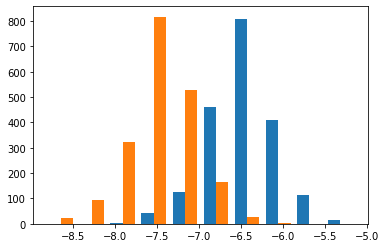

In [45]:
plot.hist([np.log10(M0StarData[MdotIndex]),np.log10(M0StarData_mod[MdotIndex])])

In [46]:
def f_M_of_L (a, b, c, t_ev, L0, L, M0,ifmr_relation = 'Zhao 2012'):
    if np.isscalar(L) == False:
        L0 = L[0]
    solns = (M0**(1+c) - (a*(1+c)*(L**b-L0**b)*t_ev)/b)**(1/(1+c))
    
    if ifmr_relation == 'Kalirai 2008':
        MF = 0.394+(0.109)*M0
    elif ifmr_relation == 'Zhao 2012':
        MF = 0.452+(0.073)*M0
    i = 0
    while solns[i] > MF:
        M = solns[i]
        i +=1
    i += 1
    while i < len(solns):
        solns[i] = MF
        i +=1
    
    return solns

def fdot_M_of_L (a, b, c, L, M):
    mdot = a*(L)**b*(M)**(-c)
    return mdot

def calc_evo_track (A_LM, B_LM, C_LM, t_ev, M0, spec_mode, L0='auto', plot_track = False,skip_period_calculations = False,grid_steps = 10000,ifmr_relation='Zhao 2012' ):
    '''
    Makes a pretty evolutionary track for the power law Mdot = A L^(B*t/t_ev) M^(-c) pretty. Has a closed-form solution.
    '''
    if ifmr_relation == 'Kalirai 2008':
        MF = 0.394+(0.109)*M0
    elif ifmr_relation == 'Zhao 2012':
        MF = 0.452+(0.073)*M0
    #print('Final Mass=',MF)
    if skip_period_calculations == False:
        if spec_mode == 'M0':
            PML = PML_M0
        elif spec_mode == 'M1':
            PML = PML_M1
        elif spec_mode == 'C0':
            PML = PML_C0
        elif spec_mode == 'C0 and C0x':
            PML = PML_C0
        elif spec_mode == 'C1':
            PML = PML_C1
        else:
            print('Error. Invalid spectral class + mode specified.')
        
    if L0 == 'auto':
        Mdot_crit = M0/t_ev
        L0 = (0.01*Mdot_crit*M0**C_LM/A_LM)**(1/B_LM)
        #print('L0:', L0)
    M = M0 # Initial condition
    #print('M_0=',M)
    L = L0 # Initial condition
    #print('L_0=',L)
    if skip_period_calculations == False:
        P = 10**(PML[0] + PML[1]*np.log10(M) + PML[2]*np.log10(L)) # initial condition
        #print('P_0=',P)
    L_list = np.logspace(np.log10(L0),np.log10(L0)+1.5,grid_steps)
    #print('Delta logL=', np.log10(L_list[1]) - np.log10(L_list[0]))
    #print('L_list:', L_list)
    M_list = f_M_of_L (A_LM, B_LM, C_LM, t_ev, L0, L_list, M0,ifmr_relation=ifmr_relation)
    M_list = np.nan_to_num(M_list,nan=MF) # Replace all nAn values with MF
    #print('M_list', M_list)
    # iterate over M_list until we find the first instance of MF
    current_M = M_list[0]
    i = 0
    while current_M != MF:
        current_M = M_list[i]
        i = i + 1
    #i = i + 1 # Step one more time to include that last mass
    L_list = L_list[:i]
    M_list = M_list[:i]
    #print('np.log10(M_list):',np.log10(M_list))
    #print('np.log10(L_list):',np.log10(L_list))
    '''
    def calc_logP_from_logL_logM (logM_data, logL_data, logA_PML, B_PML, C_PML):
        logM_data = np.asarray(logM_data)
        logL_data = np.asarray(logL_data)
        logP = logA_PML + B_PML*logM_data + C_PML*logL_data
        return logP
    '''
    #print('PML',PML)
    P_list = 10**(calc_logP_from_logL_logM (np.log10(M_list), np.log10(L_list), PML[0], PML[1], PML[2]))
    #print('P_list:',P_list)
    Mdot_list = A_LM*L_list**B_LM*M_list**(-C_LM)
    #print('Mdot_list:', Mdot_list)
    return L_list, M_list, P_list, Mdot_list

PLM Relation: logP= -2.709265260359455 + 1.39863 logL+ -1.288977 logM
LM Strip Relation: logMdot=( -35.19153333381802 )+( 8.23563337208871 )logL +( -13.73913258342892 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


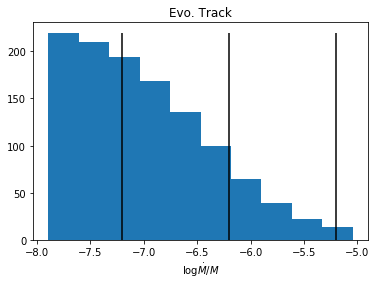

type(n_STD): <class 'float'>
Saved!


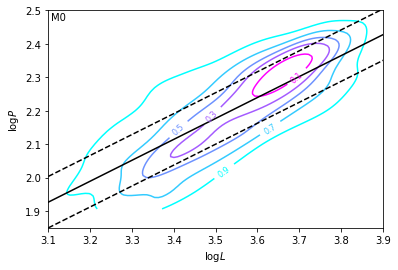

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


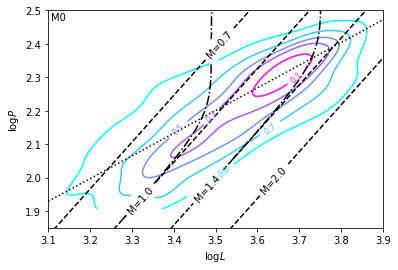

Using C_LM > 0...
dl_coords: [[ 3.1         3.9       ]
 [-0.23482182  0.21218595]]


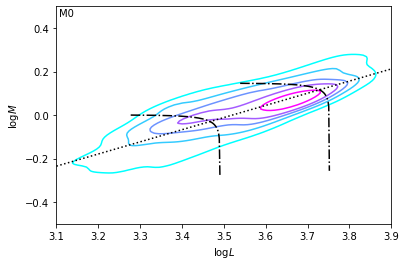

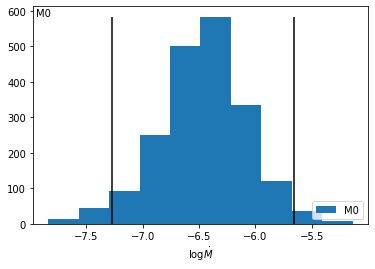

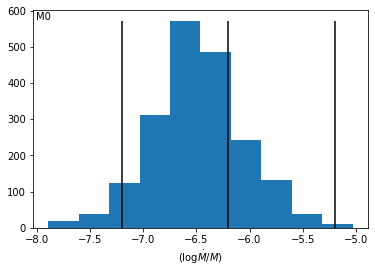

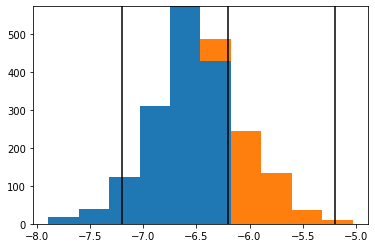

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


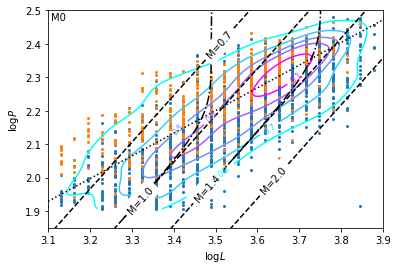

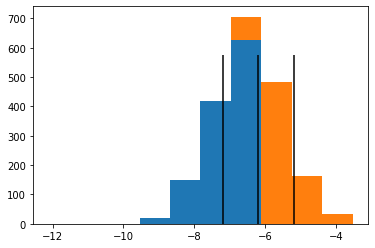

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


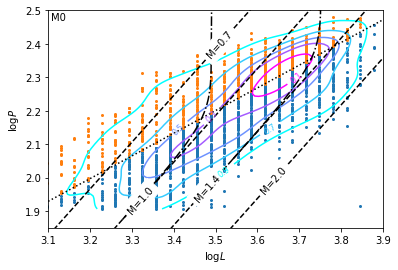

np.shape(stars_outside_dz): (29, 54)
np.shape(star_data): (29, 1979)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


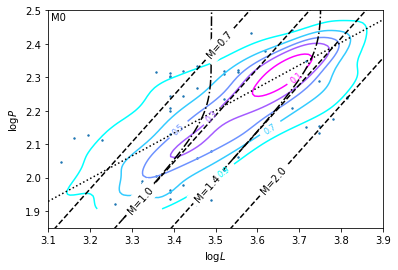

np.shape(stars_outside_dz): (29, 590)
np.shape(star_data): (29, 1979)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


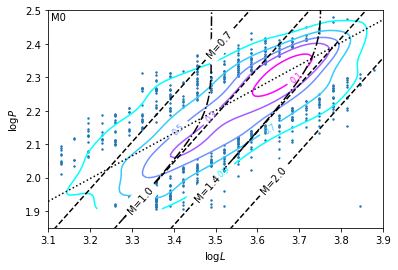

np.shape(stars_outside_dz): (29, 606)
np.shape(star_data): (29, 1979)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 681
Points Below DL (LM): 692
Fraction Above DL (LM): 0.4959941733430444
Fraction Below DL (LM): 0.5040058266569556
Points Above DL (LP): 613
Points Below DL (LP): 837
Fraction Above DL (LP): 0.3097524002021223
Fraction Below DL (LP): 0.4229408792319353


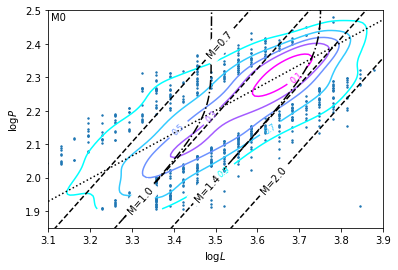

(array([1.92916766, 2.47188893]),
 array([[ 3.1       ,  3.9       ],
        [-0.23482182,  0.21218595]]))

In [47]:
logA_MdotLP_M0 = -6.31362890592161
b_MdotLP_M0 = -6.672284306164037
c_MdotLP_M0 = 10.658943164562999
t_ev_M0 = 10**6.2
plot_known_results_single_data_set_LP (M0StarData, n=1.072899999999937,n_LM=1.0242999999999423, Delta_logMdot=1.618873490337612, 
                                       log_a=logA_MdotLP_M0, b=b_MdotLP_M0, c=c_MdotLP_M0,t_ev = t_ev_M0,
                                       spec_mode_label='M0',evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=True,
                                       manual_contour_bounds=True,contour_plot_bound_logL=[3.1,3.9],contour_plot_bound_logP=[1.85,2.5],
                                       label_contours=True, line_label_shift =  [0.25,-0.1,-0.1,-0.1],contour_levels=[0.9,0.7,0.5,0.3,0.1],
                                       calculated_t_ev=False, calculated_t_ev_method = 'Mdot/M Percentiles')


PLM Relation: logP= -2.709265260359455 + 1.39863 logL+ -1.288977 logM
LM Strip Relation: logMdot=( -34.844437281824185 )+( 8.135775205015511 )logL +( -13.701508306794192 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


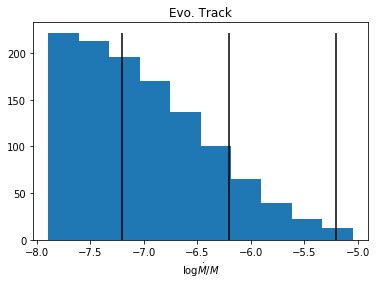

type(n_STD): <class 'float'>


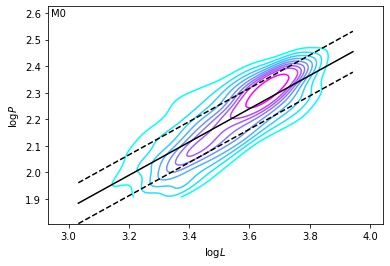

Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


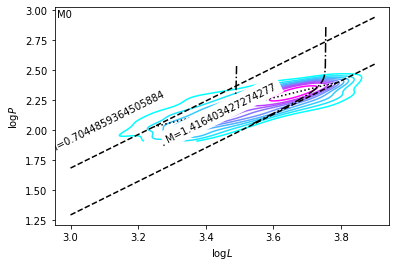

dl_coords: [[ 3.24088906  4.06476721]
 [-0.15490196  0.30103   ]]


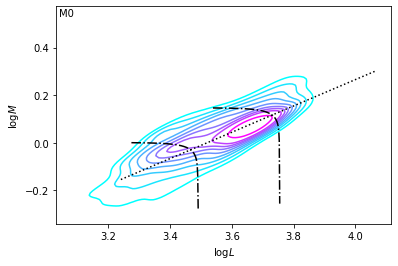

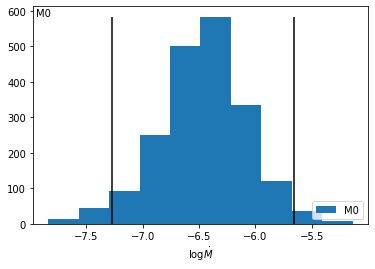

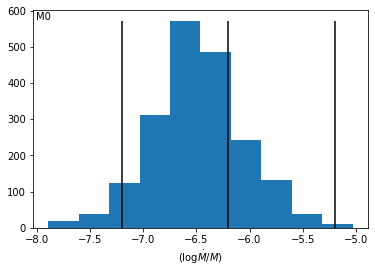

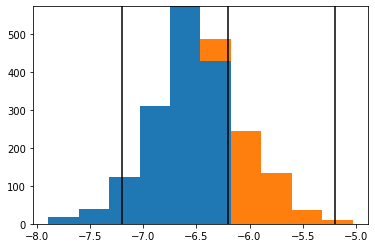

Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


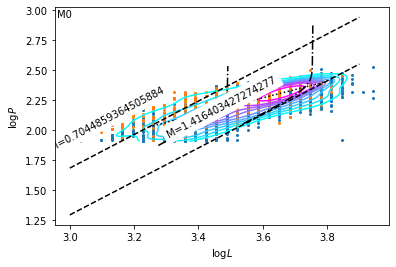

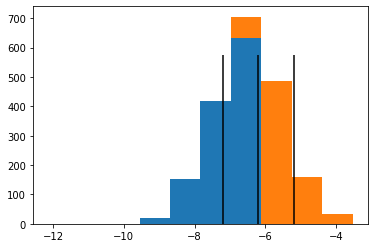

Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


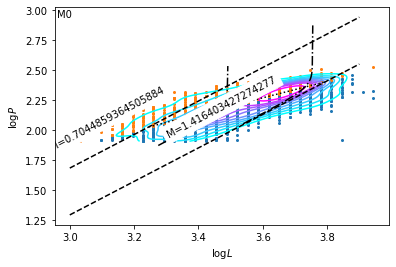

np.shape(stars_outside_dz): (29, 54)
np.shape(star_data): (29, 1979)
Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


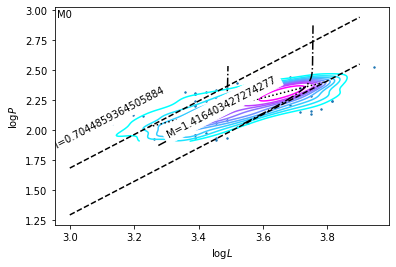

np.shape(stars_outside_dz): (29, 590)
np.shape(star_data): (29, 1979)
Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


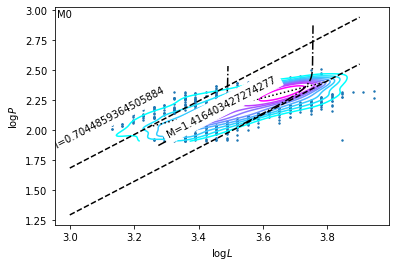

np.shape(stars_outside_dz): (29, 605)
np.shape(star_data): (29, 1979)
Points Above DL (LM): 695
Points Below DL (LM): 679
Fraction Above DL (LM): 0.5058224163027657
Fraction Below DL (LM): 0.49417758369723436
Points Above DL (LP): 609
Points Below DL (LP): 844
Fraction Above DL (LP): 0.3077311773623042
Fraction Below DL (LP): 0.426478019201617


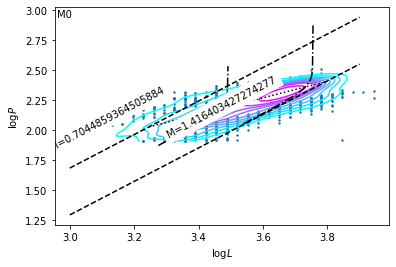

In [48]:
death_line_coords_LP_M0,death_line_coords_LM_M0 = plot_known_results_single_data_set_LP (M0StarData, n=1.072899999999937,n_LM=1.0242999999999423, Delta_logMdot=1.618873490337612, 
                                       log_a=-6.045614284886297, b=-6.731317507369241, c=10.62975391088762,t_ev = t_ev_M0,
                                       spec_mode_label='M0',evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=False,
                                                                mass_list_method = 'percentile',
                                       calculated_t_ev=False)

([array([  0.,   0.,   2.,  88., 342., 651., 742., 259.,  61.,  17.]),
  array([ 36., 195., 481., 821., 486., 110.,  28.,   5.,   0.,   0.])],
 array([-8.96743309, -8.56627737, -8.16512166, -7.76396594, -7.36281022,
        -6.96165451, -6.56049879, -6.15934307, -5.75818735, -5.35703164,
        -4.95587592]),
 <a list of 2 Lists of Patches objects>)

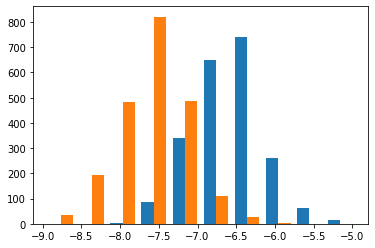

In [49]:
plot.hist([np.log10(M1StarData[MdotIndex]),np.log10(M1StarData_mod[MdotIndex])])

PLM Relation: logP= -1.9323700000000001 + 1.0833 logL+ -0.9230700000000001 logM
LM Strip Relation: logMdot=( -42.83024711565797 )+( 10.150790750584106 )logL +( -20.48418752185978 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


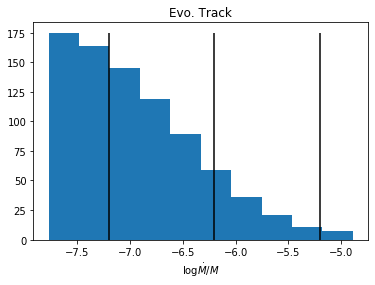

type(n_STD): <class 'float'>
Saved!


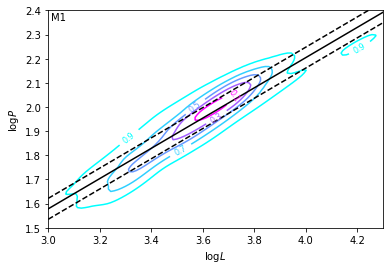

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


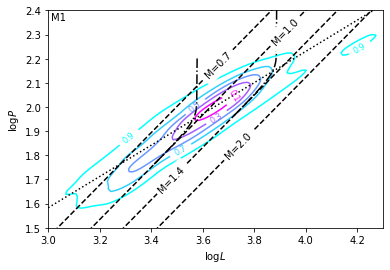

Using C_LM > 0...
dl_coords: [[ 3.          4.3       ]
 [-0.2875545   0.32666598]]


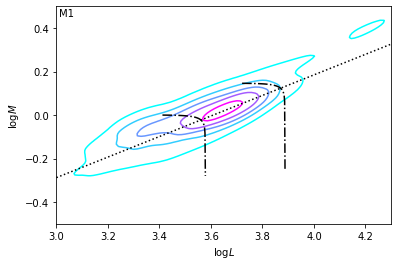

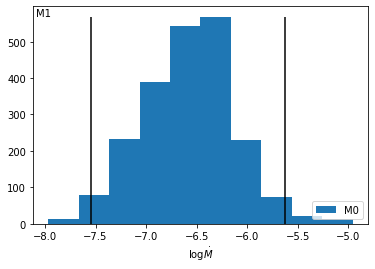

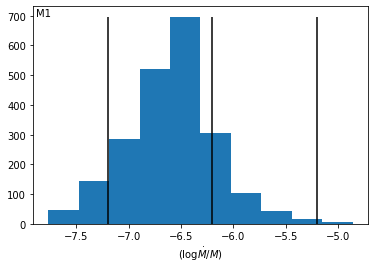

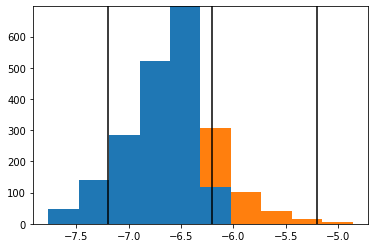

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


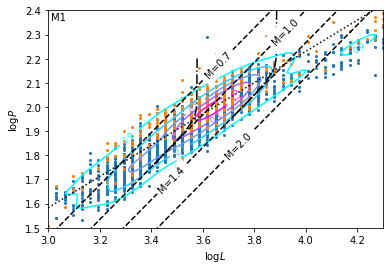

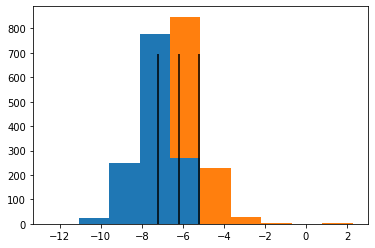

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


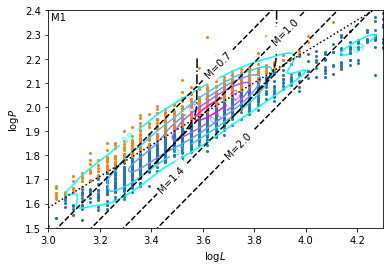

np.shape(stars_outside_dz): (29, 62)
np.shape(star_data): (29, 2162)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


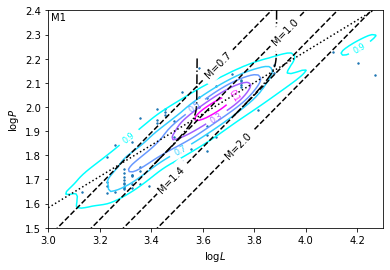

np.shape(stars_outside_dz): (29, 928)
np.shape(star_data): (29, 2162)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


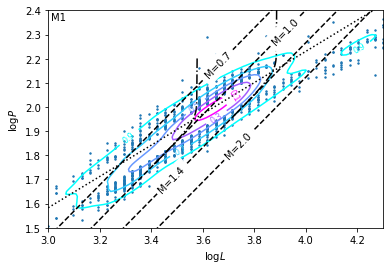

np.shape(stars_outside_dz): (29, 951)
np.shape(star_data): (29, 2162)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


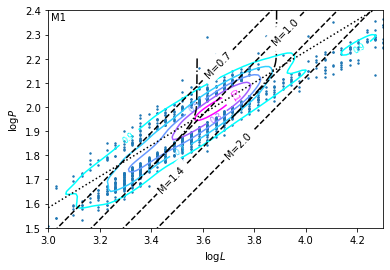

(array([1.58296294, 2.42428444]),
 array([[ 3.        ,  4.3       ],
        [-0.2875545 ,  0.32666598]]))

In [50]:
logA_MdotLP_M1 = 0.05168972728588189
b_MdotLP_M1 = -13.889119919712511
c_MdotLP_M1 = 22.191369583953307
t_ev_M1 = 10**6.2
plot_known_results_single_data_set_LP (M1StarData, n=0.8931999999999567, n_LM=0.845099999999962, Delta_logMdot=1.9199034860015933, 
                                       log_a=logA_MdotLP_M1, b=b_MdotLP_M1, c=c_MdotLP_M1,t_ev = t_ev_M1,
                                       spec_mode_label='M1',evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=True,
                                       manual_contour_bounds=True,contour_plot_bound_logL=[3.0,4.3],contour_plot_bound_logP=[1.5,2.4],
                                       label_contours=True, line_label_shift = [0.4,0.4,-0.3,-0.3],contour_levels=[0.9,0.7,0.5,0.3,0.1],
                                       calculated_t_ev=False, calculated_t_ev_method = 'Mdot/M Percentiles')

PLM Relation: logP= -1.9323700000000001 + 1.0833 logL+ -0.9230700000000001 logM
LM Strip Relation: logMdot=( -42.822131870554244 )+( 10.148517846251726 )logL +( -20.479600825147386 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


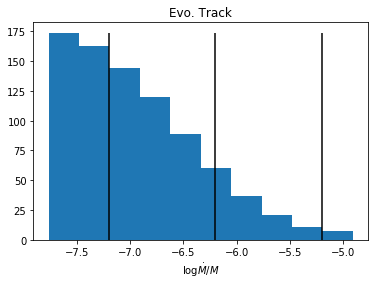

type(n_STD): <class 'float'>


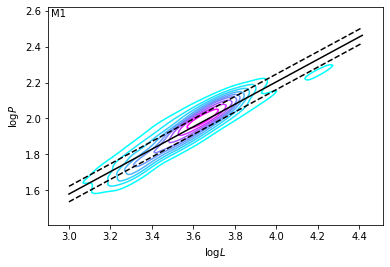

Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


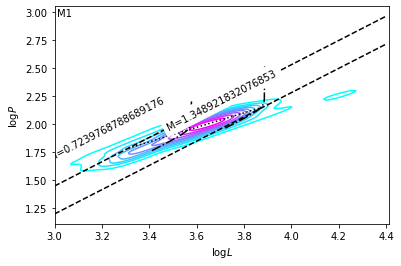

dl_coords: [[ 3.28076475  4.24575654]
 [-0.15490196  0.30103   ]]


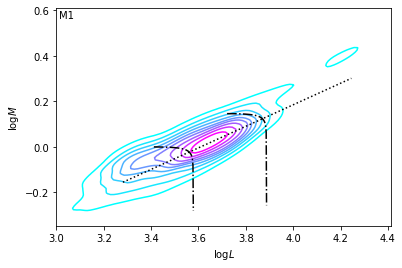

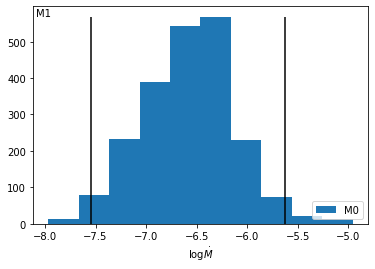

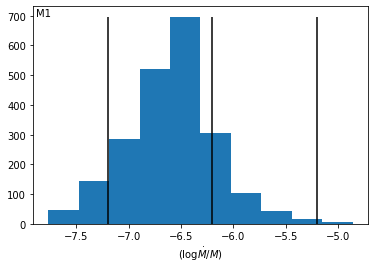

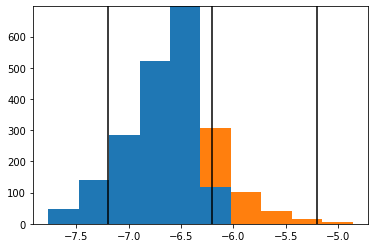

Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


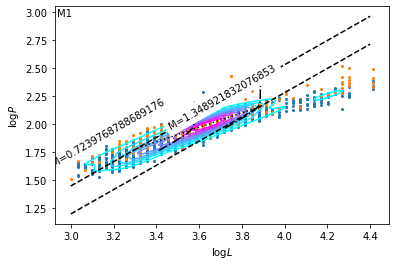

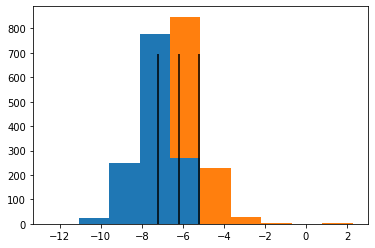

Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


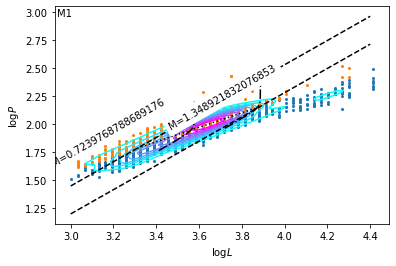

np.shape(stars_outside_dz): (29, 62)
np.shape(star_data): (29, 2162)
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


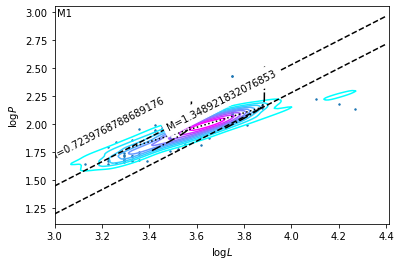

np.shape(stars_outside_dz): (29, 928)
np.shape(star_data): (29, 2162)
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


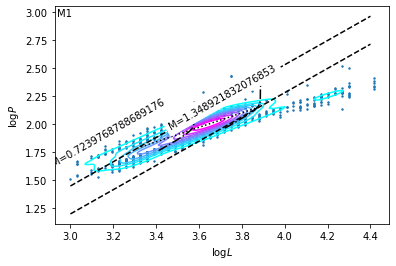

np.shape(stars_outside_dz): (29, 951)
np.shape(star_data): (29, 2162)
Points Above DL (LM): 661
Points Below DL (LM): 550
Fraction Above DL (LM): 0.5458298926507019
Fraction Below DL (LM): 0.4541701073492981
Points Above DL (LP): 799
Points Below DL (LP): 1174
Fraction Above DL (LP): 0.3695652173913043
Fraction Below DL (LP): 0.5430157261794635


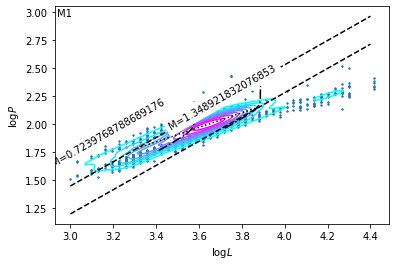

In [51]:
death_line_coords_LP_M1,death_line_coords_LM_M1 = plot_known_results_single_data_set_LP (M1StarData, n=0.8931999999999567, n_LM=0.845099999999962, Delta_logMdot=1.9199034860015933, 
                                       log_a=0.05020310565563323, b=-13.886009951079094, c=22.18640062524769,t_ev = t_ev_M1,
                                       spec_mode_label='M1',evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=False,
                                                                mass_list_method = 'percentile',calculated_t_ev=False)

PLM Relation: logP= -2.9316472603594557 + 1.5056910000000001 logL+ -1.5839530000000002 logM
LM Strip Relation: logMdot=( -40.61562771628344 )+( 9.620248047597151 )logL +( -13.899788094084272 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


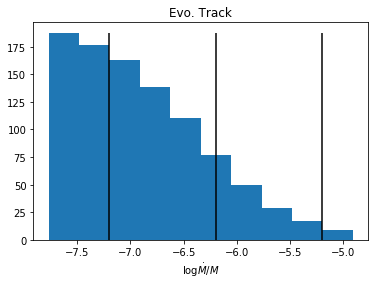

type(n_STD): <class 'float'>
Saved!


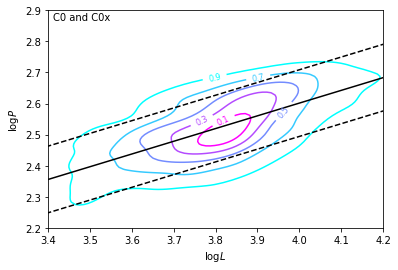

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


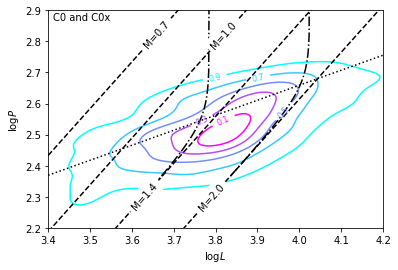

Using C_LM > 0...
dl_coords: [[ 3.4         4.2       ]
 [-0.11455091  0.40197982]]


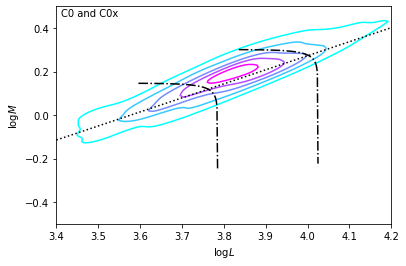

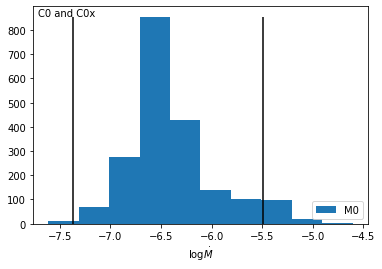

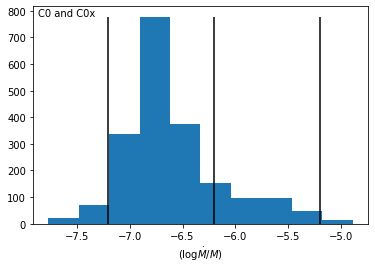

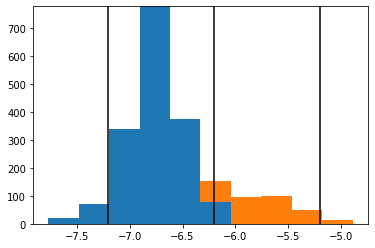

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


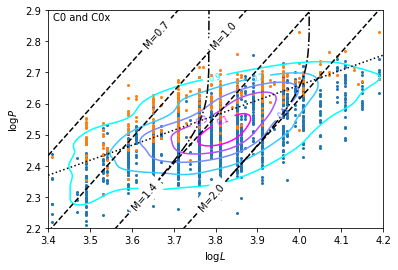

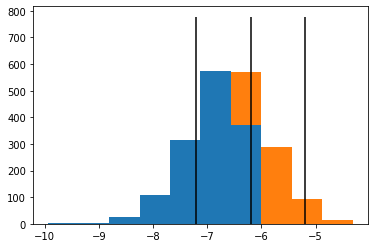

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


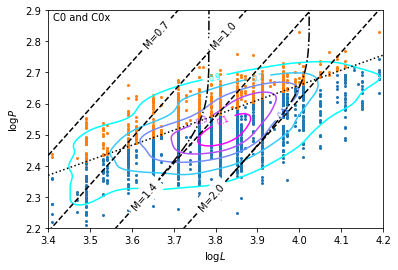

np.shape(stars_outside_dz): (29, 88)
np.shape(star_data): (29, 1994)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


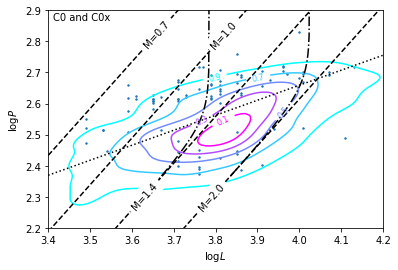

np.shape(stars_outside_dz): (29, 341)
np.shape(star_data): (29, 1994)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


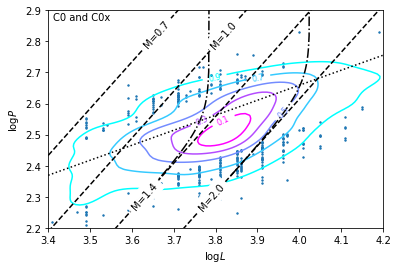

np.shape(stars_outside_dz): (29, 413)
np.shape(star_data): (29, 1994)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 977
Points Below DL (LM): 604
Fraction Above DL (LM): 0.6179633143580012
Fraction Below DL (LM): 0.3820366856419987
Points Above DL (LP): 526
Points Below DL (LP): 959
Fraction Above DL (LP): 0.2637913741223671
Fraction Below DL (LP): 0.4809428284854564


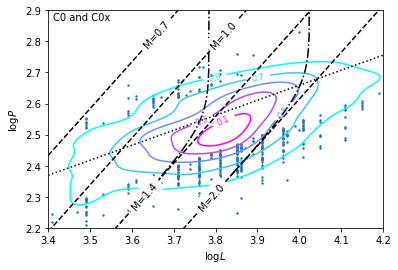

(array([2.3691454, 2.7555378]),
 array([[ 3.4       ,  4.2       ],
        [-0.11455091,  0.40197982]]))

In [52]:
logA_MdotLP_C0 = -14.889311540488364
b_MdotLP_C0 = -3.5927613252629285
c_MdotLP_C0= 8.77537912683285
t_ev_C0 = 10**6.2

plot_known_results_single_data_set_LP (C0StarData, n=1.5136999999998884, n_LM = 1.7039999999998674, Delta_logMdot=1.8834944309285628, 
                                      log_a=logA_MdotLP_C0, b=b_MdotLP_C0, c=c_MdotLP_C0,t_ev = t_ev_C0,
                                       spec_mode_label='C0 and C0x',evo_behavior_m_list=[0.7,1.0,1.4,2.0],text_x=0.10,save_figures=True,
                                       manual_contour_bounds=True,contour_plot_bound_logL=[3.4,4.2],contour_plot_bound_logP=[2.2,2.9],
                                       label_contours=True, line_label_shift = [0.10,0.10,-0.25,-0.25],contour_levels=[0.9,0.7,0.5,0.3,0.1],
                                       calculated_t_ev = False)



PLM Relation: logP= -2.9316472603594557 + 1.5056910000000001 logL+ -1.5839530000000002 logM
LM Strip Relation: logMdot=( -40.95052830518927 )+( 9.622154683267865 )logL +( -13.902542891223035 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


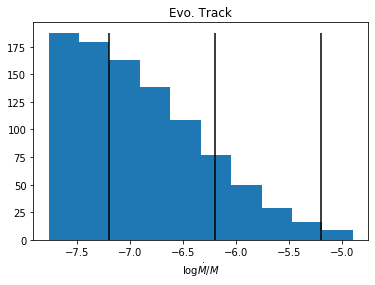

type(n_STD): <class 'float'>


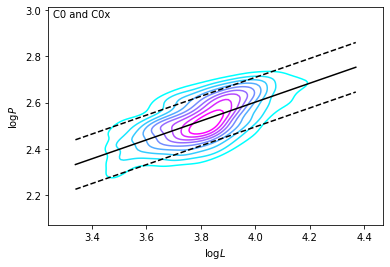

Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


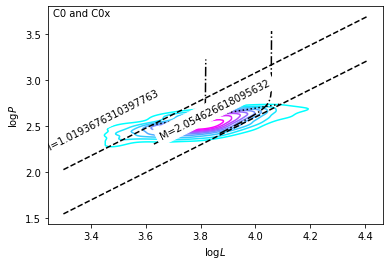

dl_coords: [[ 3.371604    4.07773955]
 [-0.15490196  0.30103   ]]


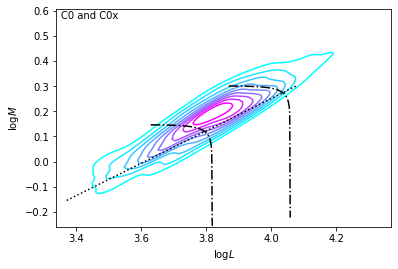

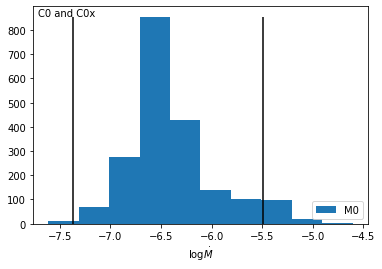

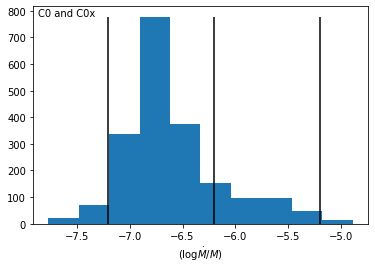

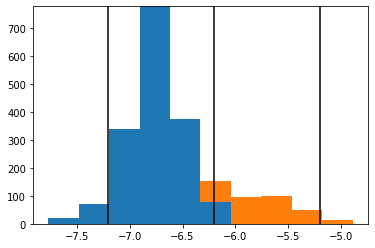

Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


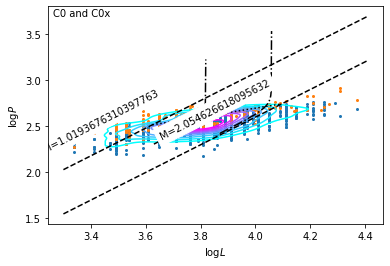

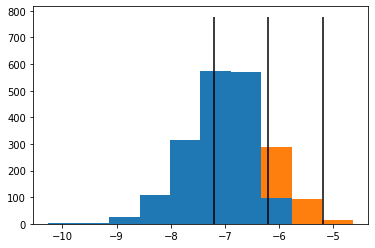

Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


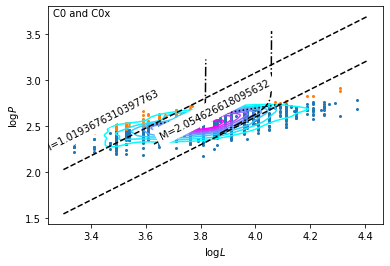

np.shape(stars_outside_dz): (29, 88)
np.shape(star_data): (29, 1994)
Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


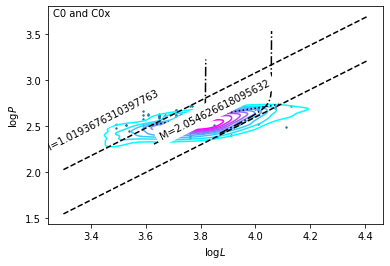

np.shape(stars_outside_dz): (29, 467)
np.shape(star_data): (29, 1994)
Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


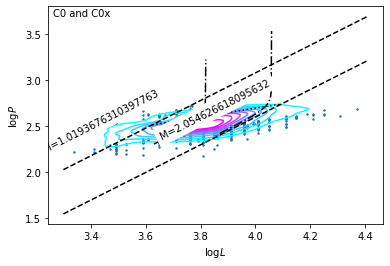

np.shape(stars_outside_dz): (29, 631)
np.shape(star_data): (29, 1994)
Points Above DL (LM): 1026
Points Below DL (LM): 337
Fraction Above DL (LM): 0.7527512839325018
Fraction Below DL (LM): 0.24724871606749815
Points Above DL (LP): 279
Points Below DL (LP): 926
Fraction Above DL (LP): 0.1399197592778335
Fraction Below DL (LP): 0.46439317953861586


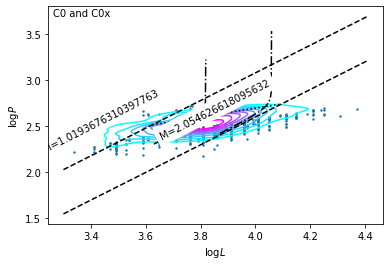

"\nplot_known_results_multi_data_set_LP ([C0StarData_n,C0StarData_x], n=1.5136999999998884, n_LM = 1.7039999999998674, Delta_logMdot=1.8834944309285628, \n                                      log_a=-15.219113434240555, b=-3.5934733741482967, c=8.777118318045444,\n                                      spec_mode_label='C0 and C0x',spec_mode_labels=['C0','C0x'],text_x=0.10,t_ev=2.5*10**6,\n                                      evo_behavior_m_list=[0.7,1.0,1.4,2.0])\n"

In [53]:
death_line_coords_LP_C0, death_line_coords_LM_C0 = plot_known_results_single_data_set_LP (C0StarData, n=1.5136999999998884, n_LM = 1.7039999999998674, Delta_logMdot=1.8834944309285628, 
                                      log_a=-15.219113434240555, b=-3.5934733741482967, c=8.777118318045444,t_ev = t_ev_C0,
                                       spec_mode_label='C0 and C0x',evo_behavior_m_list=[0.7,1.0,1.4,2.0],text_x=0.10,save_figures=False,
                                                                mass_list_method = 'percentile',calculated_t_ev=False)
'''
plot_known_results_multi_data_set_LP ([C0StarData_n,C0StarData_x], n=1.5136999999998884, n_LM = 1.7039999999998674, Delta_logMdot=1.8834944309285628, 
                                      log_a=-15.219113434240555, b=-3.5934733741482967, c=8.777118318045444,
                                      spec_mode_label='C0 and C0x',spec_mode_labels=['C0','C0x'],text_x=0.10,t_ev=2.5*10**6,
                                      evo_behavior_m_list=[0.7,1.0,1.4,2.0])
'''

PLM Relation: logP= -2.06111 + 1.15709 logL+ -1.1114700000000002 logM
LM Strip Relation: logMdot=( -27.823019139470173 )+( 5.888707448080171 )logL +( -9.440804631588628 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


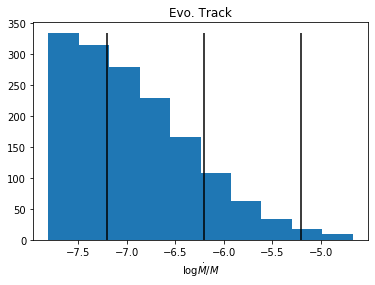

type(n_STD): <class 'float'>
Saved!


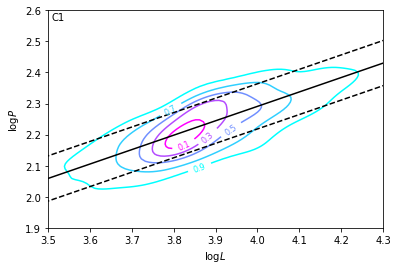

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


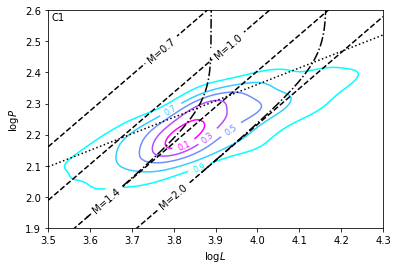

Using C_LM > 0...
dl_coords: [[ 3.5         4.3       ]
 [-0.09697941  0.35422776]]


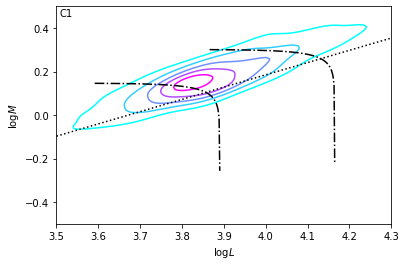

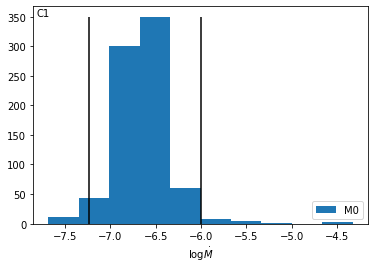

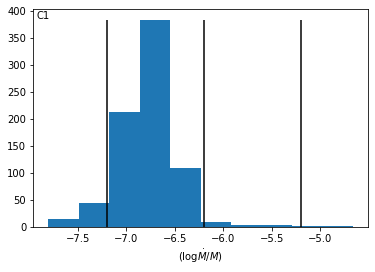

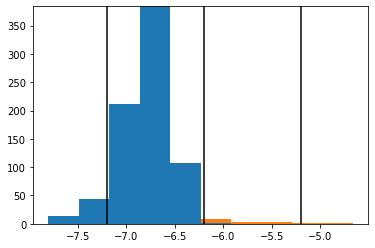

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


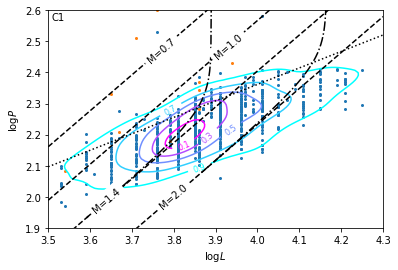

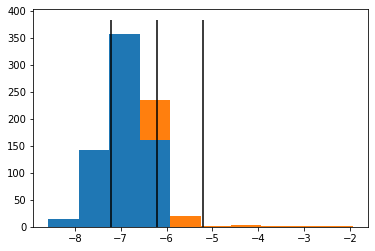

Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


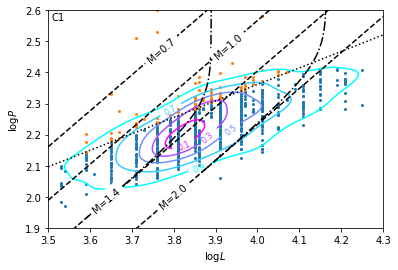

np.shape(stars_outside_dz): (29, 20)
np.shape(star_data): (29, 781)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


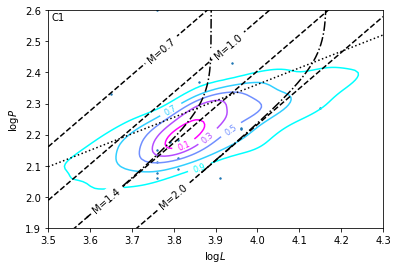

np.shape(stars_outside_dz): (29, 102)
np.shape(star_data): (29, 781)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


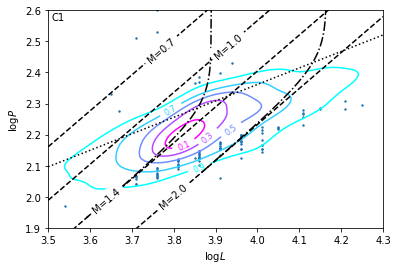

np.shape(stars_outside_dz): (29, 189)
np.shape(star_data): (29, 781)
Check: t_ev= 1584893.1924611141
Using C_LM < 0...
Points Above DL (LM): 497
Points Below DL (LM): 95
Fraction Above DL (LM): 0.839527027027027
Fraction Below DL (LM): 0.16047297297297297
Points Above DL (LP): 94
Points Below DL (LP): 467
Fraction Above DL (LP): 0.1203585147247119
Fraction Below DL (LP): 0.5979513444302177


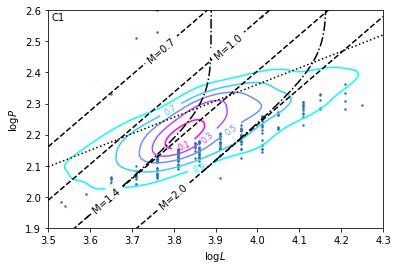

(array([2.0964947 , 2.52066347]),
 array([[ 3.5       ,  4.3       ],
        [-0.09697941,  0.35422776]]))

In [54]:
logA_MdotLP_C1 = -10.31599075884484
b_MdotLP_C1 = -3.93959257905946
c_MdotLP_C1 = 8.493980612691866
t_ev_C1 = 10**6.2


plot_known_results_single_data_set_LP (C1StarData, n=1.1599999999999273,n_LM=1.1503999999999284, Delta_logMdot=1.2355284469075496, 
                                       log_a=logA_MdotLP_C1, b=b_MdotLP_C1, c=c_MdotLP_C1,t_ev = t_ev_C1,
                                       spec_mode_label='C1', evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=True,
                                       manual_contour_bounds=True,contour_plot_bound_logL=[3.5,4.3],contour_plot_bound_logP=[1.9,2.6],
                                       label_contours=True, line_label_shift = [0.11,0.11,-0.34,-0.34],contour_levels=[0.9,0.7,0.5,0.3,0.1],
                                       calculated_t_ev = False)

PLM Relation: logP= -2.06111 + 1.15709 logL+ -1.1114700000000002 logM
LM Strip Relation: logMdot=( -28.151144894935417 )+( 5.888707448080465 )logL +( -9.440804631589089 )logM


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


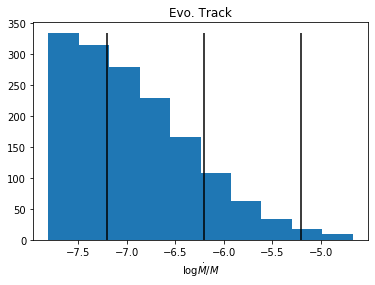

type(n_STD): <class 'float'>


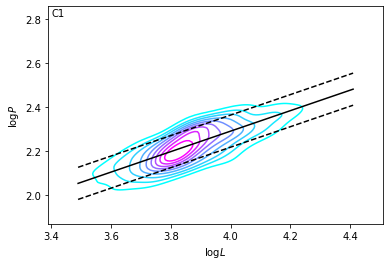

Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


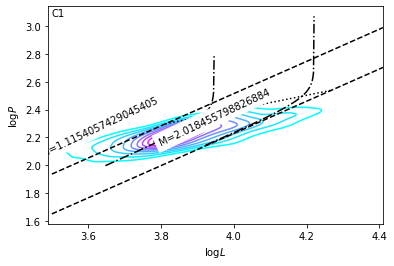

dl_coords: [[ 3.45302326  4.2614004 ]
 [-0.15490196  0.30103   ]]


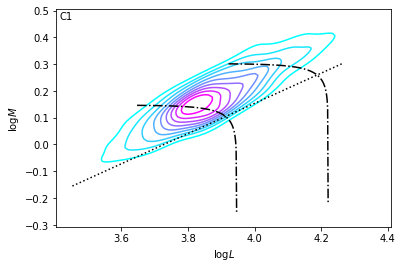

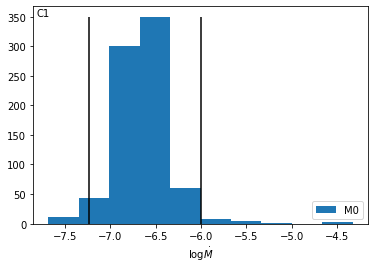

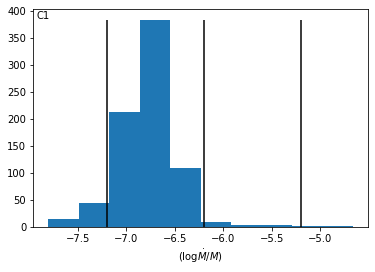

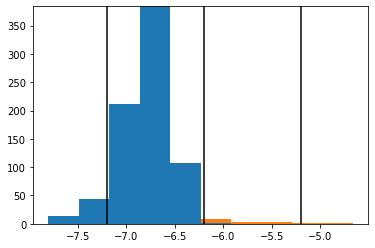

Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


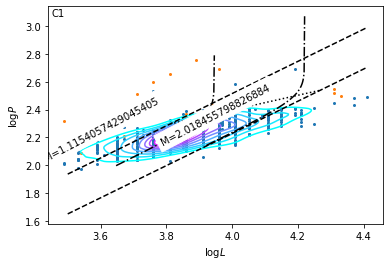

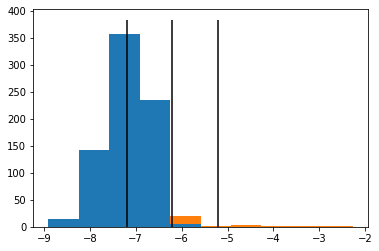

Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


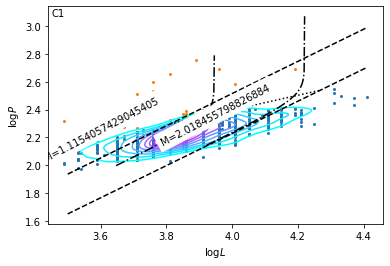

np.shape(stars_outside_dz): (29, 20)
np.shape(star_data): (29, 781)
Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


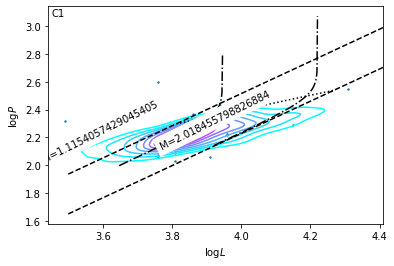

np.shape(stars_outside_dz): (29, 204)
np.shape(star_data): (29, 781)
Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


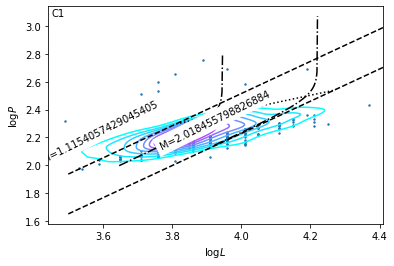

np.shape(stars_outside_dz): (29, 372)
np.shape(star_data): (29, 781)
Points Above DL (LM): 393
Points Below DL (LM): 16
Fraction Above DL (LM): 0.960880195599022
Fraction Below DL (LM): 0.039119804400977995
Points Above DL (LP): 16
Points Below DL (LP): 362
Fraction Above DL (LP): 0.020486555697823303
Fraction Below DL (LP): 0.46350832266325226


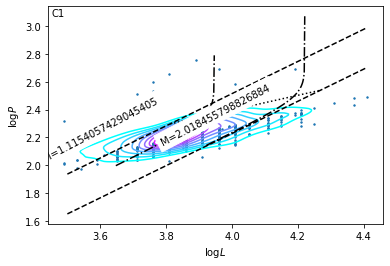

In [55]:

death_line_coords_LP_C1, death_line_coords_LM_C1 = plot_known_results_single_data_set_LP (C1StarData, n=1.1599999999999273,n_LM=1.1503999999999284, Delta_logMdot=1.2355284469075496, 
                                       log_a=-10.64411651430923, b=-3.9395925790596444, c=8.49398061269228,t_ev = t_ev_C1,
                                       spec_mode_label='C1', evo_behavior_m_list=[0.7,1.0,1.4,2.0],save_figures=False,
                                                                mass_list_method='percentile',calculated_t_ev=False)

In [56]:
A_LM_M0, B_LM_M0, C_LM_M0 = 10**(-35.33267628404653), 8.23563337208871, 13.73913258342892
A_LM_M1, B_LM_M1, C_LM_M1 = 10**(-42.83024711565797),10.150790750584106 , 20.48418752185978
A_LM_C0, B_LM_C0, C_LM_C0 = 10**(-40.731829001928034), 9.620248047597151, 13.899788094084272
A_LM_C1, B_LM_C1, C_LM_C1 = 10**(-27.823019139470173), 5.888707448080171, 9.440804631588628

In [57]:
def simulate_evolutionary_track (A, B, C, t_ev, M0, spec_mode, L0='auto', delta_t = 1000,ifmr_relation = 'Zhao 2012',method = 'Runge-Kutta 4',skip_period_calculations = False):
    '''
    Simulates an evolutionary track for the power law Mdot = A L^(B*t/t_ev) M^(-c).
    '''
    if ifmr_relation == 'Kalirai 2008':
        MF = 0.394+(0.109)*M0
    elif ifmr_relation == 'Zhao 2012':
        MF = 0.452+(0.073)*M0
    #print('Final Mass=',MF)
    if skip_period_calculations == False:
        if spec_mode == 'M0':
            PML = PML_M0
        elif spec_mode == 'M1':
            PML = PML_M1
        elif spec_mode == 'C0':
            PML = PML_C0
        elif spec_mode == 'C0 and C0x':
            PML = PML_C0
        elif spec_mode == 'C1':
            PML = PML_C1
        else:
            print('Error. Invalid spectral class + mode specified.')
        
    if L0 == 'auto':
        Mdot_crit = M0/t_ev
        L0 = (0.01*Mdot_crit*M0**C/A)**(1/B)
    M = M0 # Initial condition
    #print('M_0=',M)
    L = L0 # Initial condition
    #print('L_0=',L)
    if skip_period_calculations == False:
        P = 10**(PML[0] + PML[1]*np.log10(M) + PML[2]*np.log10(L)) # initial condition
        #print('P_0=',P)
    t = 0. # Initial condition
    #print('t_0=',t)
    Mdot = -A*L**B*np.exp(B*t/t_ev)*M**(-C) # Initial condition
    #print('Mdot_0=',Mdot)
    M_array = [M]
    L_array = [L]
    if skip_period_calculations == False:
        P_array = [P]
    else: 
        P_array = []
    t_array = [0]
    Mdot_array = [Mdot]
    '''
    Method 1 (Euler Method): Given initial conditions, find an approximate solution at t = t+delta_t. Note, this method works 
    better for smaller delta_t.
    
    Method 2 (Runge-Kutta 4 - RK4): Given initial conditions, find an approximate solution at t = t+delta_t. More robust than 
    the Euler method for slightly more computational cost.
    - Let an IVP be specified as dx/dt = f(t,x); x(t_0) = x_0.
    - Pick step size h
    - Define x_(n+1) = x_n + (1/6)*h*(k_1 + 2 k_2 + 2 k_3 + k_4); t_(n+1) = t_n + h
    - Calculate k_1 = f(t_n,x_n); k_2 = f(t_n+h/2, x_n+h*k1/2); k_3 = f(t_n+h/2, x_n+h*k2/2); k_4 = f(t+h, x+h*k3)
    Repeat method for successive steps until end condition reached.
    '''
    if method == 'Euler':
        while M > MF:
            t = t+delta_t # Increment t by delta_t (yr)
            t_array.append(t) # Save the current time
            L = L0*np.exp(t/t_ev) # Calculate new L (Lsun)
            L_array.append(L) # Save the current L
            M = M + Mdot*delta_t # Calculate new M (Msun)
            M_array.append(M) # Save the current M
            if skip_period_calculations == False:
                P = 10**(PML[0] + PML[1]*np.log10(M) + PML[2]*np.log10(L)) # calculate new P (days)
                P_array.append(P) # Save the current P
            Mdot = -A*L**(B*t/t_ev)*M**(-C) # Calculate new Mdot (Msun/yr)
            Mdot_array.append(Mdot) # Save the current Mdot
            #if M < 0.8*M0:
            #    print('Current Mass=',M, 'at time t=',t)
        results = np.asarray([t_array[:-1], M_array[:-1], L_array[:-1], P_array[:-1], Mdot_array[:-1]])
    elif method == 'Runge-Kutta 4' or method == 'Runge Kutta 4' or method == 'RK4':
        while M > MF:
            # Determine slopes k_n
            k1 = -A*L**B*np.exp(B*t/t_ev)*M**(-C) # f(t,x)
            k2 = -A*L**B*np.exp(B*(t+delta_t/2)/t_ev)*(M+delta_t*k1/2)**(-C) # f(t+h/2, x+h*k1/2); h=step size
            k3 = -A*L**B*np.exp(B*(t+delta_t/2)/t_ev)*(M+delta_t*k2/2)**(-C) # f(t+h/2, x+h*k2/2)
            k4 = -A*L**B*np.exp(B*(t+delta_t)/t_ev)*(M+delta_t*k3)**(-C) # f(t+h, x+h*k3)
            Mdot_array.append(k4) # Save the current Mdot
            # Calculate new values
            M = M + (1/6)*delta_t*(k1 + 2*k2+2*k3+k4)
            M_array.append(M) # Save the current M
            t = t + delta_t
            t_array.append(t) # Save the current time
            L = L0*np.exp(t/t_ev) # Calculate new L (Lsun)
            L_array.append(L) # Save the current L
            if skip_period_calculations == False:
                P = 10**(PML[0] + PML[1]*np.log10(M) + PML[2]*np.log10(L)) # calculate new P (days)
                P_array.append(P) # Save the current P
        results = np.asarray([t_array[:-1], M_array[:-1], L_array[:-1], P_array[:-1], Mdot_array[:-1]])
    
    return results

In [58]:
def generate_deathline_points (dl_coords,logLMin,logLMax,num_steps=1000):
    logL_coords = dl_coords[0]
    logM_coords = dl_coords[1]
    slope = (logM_coords[1]-logM_coords[0])/(logL_coords[1]-logL_coords[0])
    logL = np.arange(logLMin,logLMax,1/num_steps)
    logM = slope*(logL-logL_coords[0]) + logM_coords[0]
    return logL, logM
    

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


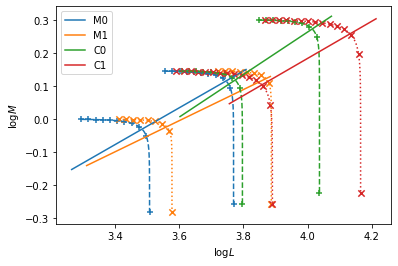

In [59]:
grid_steps = 100000
fundamental_marker = '+'
overtone_marker = 'x'
marker_size = 40
marker_increment = 1500
fundamental_ls = '--'
overtone_ls = ':'
# M0
logM_M0_10_percentile = np.percentile(np.log10(M0StarData[MIndex]),10)
logM_M0_90_percentile = np.percentile(np.log10(M0StarData[MIndex]),90)
M0_10th_to_90th_dl_data = calc_deathline_from_mass (np.log10(A_LM_M0), B_LM_M0, C_LM_M0, t_ev_M0,logM_M0_10_percentile, logM_M0_90_percentile)
M0_10th_to_90th_dl_period = calc_logP_from_logL_logM (M0_10th_to_90th_dl_data[1], M0_10th_to_90th_dl_data[0], 
                                                      PML_M0[0], PML_M0[1], PML_M0[2])
L_10_M0, M_10_M0, P_10_M0, Mdot_10_M0 = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, t_ev_M0,1.0,'M0',grid_steps=grid_steps )
L_14_M0, M_14_M0, P_14_M0, Mdot_14_M0 = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, t_ev_M0,1.4,'M0',grid_steps=grid_steps )
set_color = 'tab:blue'
plot.plot(M0_10th_to_90th_dl_data[0],M0_10th_to_90th_dl_data[1],color=set_color,label='M0')
plot.plot(np.log10(L_10_M0), np.log10(M_10_M0),color=set_color,linestyle=fundamental_ls)
plot.plot(np.log10(L_14_M0), np.log10(M_14_M0),color=set_color,linestyle=fundamental_ls)
plot.scatter(np.log10(L_10_M0)[::marker_increment], np.log10(M_10_M0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_M0)[::marker_increment], np.log10(M_14_M0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_10_M0)[-1], np.log10(M_10_M0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_M0)[-1], np.log10(M_14_M0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)

# M1
logM_M1_10_percentile = np.percentile(np.log10(M1StarData[MIndex]),10)
logM_M1_90_percentile = np.percentile(np.log10(M1StarData[MIndex]),90)
M1_10th_to_90th_dl_data = calc_deathline_from_mass (np.log10(A_LM_M1), B_LM_M1, C_LM_M1, t_ev_M1,logM_M1_10_percentile, logM_M1_90_percentile)
M1_10th_to_90th_dl_period = calc_logP_from_logL_logM (M1_10th_to_90th_dl_data[1], M1_10th_to_90th_dl_data[0], 
                                                      PML_M1[0], PML_M1[1], PML_M1[2])
L_10_M1, M_10_M1, P_10_M1, Mdot_10_M1 = calc_evo_track (A_LM_M1, B_LM_M1, C_LM_M1, t_ev_M1,1.0,'M1',grid_steps=grid_steps  )
L_14_M1, M_14_M1, P_14_M1, Mdot_14_M1 = calc_evo_track (A_LM_M1, B_LM_M1, C_LM_M1, t_ev_M1,1.4,'M1',grid_steps=grid_steps  )
set_color = 'tab:orange'
plot.plot(M1_10th_to_90th_dl_data[0],M1_10th_to_90th_dl_data[1],color=set_color,label='M1')
plot.plot(np.log10(L_10_M1), np.log10(M_10_M1),color=set_color,linestyle=overtone_ls)
plot.plot(np.log10(L_14_M1), np.log10(M_14_M1),color=set_color,linestyle=overtone_ls)
plot.scatter(np.log10(L_10_M1)[::marker_increment], np.log10(M_10_M1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_M1)[::marker_increment], np.log10(M_14_M1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_10_M1)[-1], np.log10(M_10_M1)[-1],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_M1)[-1], np.log10(M_14_M1)[-1],color=set_color,s=marker_size,marker = overtone_marker)

# C0
logM_C0_10_percentile = np.percentile(np.log10(C0StarData[MIndex]),10)
logM_C0_90_percentile = np.percentile(np.log10(C0StarData[MIndex]),90)
C0_10th_to_90th_dl_data = calc_deathline_from_mass (np.log10(A_LM_C0), B_LM_C0, C_LM_C0, t_ev_C0,logM_C0_10_percentile, logM_C0_90_percentile)
C0_10th_to_90th_dl_period = calc_logP_from_logL_logM (C0_10th_to_90th_dl_data[1], C0_10th_to_90th_dl_data[0], 
                                                      PML_C0[0], PML_C0[1], PML_C0[2])
L_14_C0, M_14_C0, P_14_C0, Mdot_14_C0 = calc_evo_track (A_LM_C0, B_LM_C0, C_LM_C0, t_ev_C0,1.4,'C0',grid_steps=grid_steps  )
L_20_C0, M_20_C0, P_20_C0, Mdot_20_C0 = calc_evo_track (A_LM_C0, B_LM_C0, C_LM_C0, t_ev_C0,2.0,'C0',grid_steps=grid_steps  )
set_color = 'tab:green'
plot.plot(C0_10th_to_90th_dl_data[0],C0_10th_to_90th_dl_data[1],color=set_color,label='C0')
plot.plot(np.log10(L_14_C0), np.log10(M_14_C0),color=set_color,linestyle=fundamental_ls)
plot.plot(np.log10(L_20_C0), np.log10(M_20_C0),color=set_color,linestyle=fundamental_ls)
plot.scatter(np.log10(L_14_C0)[::marker_increment], np.log10(M_14_C0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_20_C0)[::marker_increment], np.log10(M_20_C0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_C0)[-1], np.log10(M_14_C0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_20_C0)[-1], np.log10(M_20_C0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)


# C1
logM_C1_10_percentile = np.percentile(np.log10(C1StarData[MIndex]),10)
logM_C1_90_percentile = np.percentile(np.log10(C1StarData[MIndex]),90)
C1_10th_to_90th_dl_data = calc_deathline_from_mass (np.log10(A_LM_C1), B_LM_C1, C_LM_C1, t_ev_C1,logM_C1_10_percentile, logM_C1_90_percentile)
C1_10th_to_90th_dl_period = calc_logP_from_logL_logM (C1_10th_to_90th_dl_data[1], C1_10th_to_90th_dl_data[0], 
                                                      PML_C1[0], PML_C1[1], PML_C1[2])
L_14_C1, M_14_C1, P_14_C1, Mdot_14_C1 = calc_evo_track (A_LM_C1, B_LM_C1, C_LM_C1, t_ev_C1,1.4,'C1',grid_steps=grid_steps  )
L_20_C1, M_20_C1, P_20_C1, Mdot_20_C1 = calc_evo_track (A_LM_C1, B_LM_C1, C_LM_C1, t_ev_C1,2.0,'C1',grid_steps=grid_steps  )
set_color = 'tab:red'
plot.plot(C1_10th_to_90th_dl_data[0],C1_10th_to_90th_dl_data[1],color=set_color,label='C1')
plot.plot(np.log10(L_14_C1), np.log10(M_14_C1),color=set_color,linestyle=overtone_ls)
plot.plot(np.log10(L_20_C1), np.log10(M_20_C1),color=set_color,linestyle=overtone_ls)
plot.scatter(np.log10(L_14_C1)[::marker_increment], np.log10(M_14_C1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_20_C1)[::marker_increment], np.log10(M_20_C1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_C1)[-1], np.log10(M_14_C1)[-1],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_20_C1)[-1], np.log10(M_20_C1)[-1],color=set_color,s=marker_size,marker = overtone_marker)

plot.xlabel(r'$\log L$')
plot.ylabel(r'$\log M$')

plot.legend()
name = "LM_deathline_M0_M1_C0_C1"
plot.savefig(name+'.pdf')
plot.savefig(name+'.png')
plot.show()
plot.close()

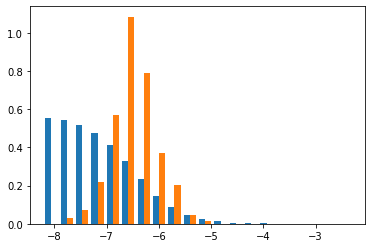

C:\ProgramData\Anaconda3\lib\site-packages\numpy\lib\histograms.py:908: RuntimeWarning: invalid value encountered in true_divide
  return n/db/n.sum(), bin_edges


best_cutoff: -6.720000000000017


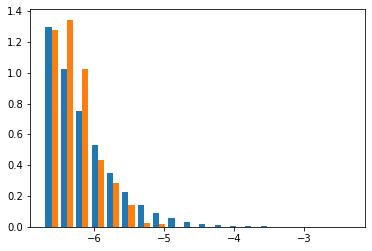

In [60]:
track_log_mdot_per_m = np.log10(Mdot_10_M0/M_10_M0)
data_log_mdot_per_m = np.log10(M0StarData[MdotIndex]/M0StarData[MIndex])
plot.hist([track_log_mdot_per_m,data_log_mdot_per_m],density=True,bins=20)
plot.show()
plot.close()

initial_cutoff = -7.5
cutoff = initial_cutoff
while cutoff < -4:
    track_indices_to_keep = np.where(track_log_mdot_per_m > cutoff)
    data_indices_to_keep = np.where(data_log_mdot_per_m > cutoff)
    hist_properties = plot.hist([track_log_mdot_per_m[track_indices_to_keep],data_log_mdot_per_m[data_indices_to_keep]],density=True,bins=20)
    plot.close()
    #print('hist_properties[0][0]:',hist_properties[0][0])
    track_initial_peak = hist_properties[0][0][0]
    data_initial_peak = hist_properties[0][1][0]
    peak_proximity = np.abs(track_initial_peak-data_initial_peak)
    if cutoff == initial_cutoff:
        best_cutoff = cutoff
        best_peak_proximity = peak_proximity
    elif peak_proximity < best_peak_proximity:
        best_cutoff = cutoff
        best_peak_proximity = peak_proximity
    cutoff = cutoff + 0.01
    #print('Cycle')
    
    
print('best_cutoff:', best_cutoff)
track_indices_to_keep = np.where(track_log_mdot_per_m > best_cutoff)
data_indices_to_keep = np.where(data_log_mdot_per_m > best_cutoff)
test_hist = plot.hist([track_log_mdot_per_m[track_indices_to_keep],data_log_mdot_per_m[data_indices_to_keep]],density=True,bins=20)


In [61]:
def optimize_tev_by_histogram (star_data, A_LM, B_LM, C_LM, test_M0, spec_mode_label,initial_tev, final_tev):
    logMData = np.log10(star_data[MIndex])
    logMdotData = np.log10(star_data[MdotIndex])
    logMdot_per_MData = logMdotData - logMData
    cut_logMdot_per_MData = logMdot_per_MData[np.where(logMdot_per_MData>-7)]
    tev_test = initial_tev
    while tev_test < final_tev:
        L_track, M_track, P_track, Mdot_track = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, tev_test,test_M0,spec_mode_label,grid_steps=10000 )
        logMdot_per_MTrack = np.log10(Mdot_track/M_track)
        hist_properties=plot.hist([logMdot_per_MTrack,cut_logMdot_per_MData],density=True)
        plot.close()
        '''
        print('len(Mdot_track)', len(Mdot_track))
        print('Mdot_crit:', test_M0/t_ev_test)
        track_past_dz_start = np.where(Mdot_track > 0.1*test_M0/t_ev_test)
        print('track_past_dz_start',track_past_dz_start)
        print('Mdot_track[track_past_dz_start]', Mdot_track[track_past_dz_start])
        track_before_dz_end = np.where(Mdot_track < 10*test_M0/t_ev_test)
        print('track_before_dz_end',track_before_dz_end)
        track_dz_only_indices = [i for i in track_past_dz_start if i in track_before_dz_end]
        print('track_dz_only_indices', track_dz_only_indices)
        L_track, M_track, P_track, Mdot_track = L_track[track_dz_only_indices], M_track[track_dz_only_indices], P_track[track_dz_only_indices], Mdot_track[track_dz_only_indices]
        '''
        track_initial_peak = hist_properties[0][0][0]
        data_initial_peak = hist_properties[0][1][0]
        data_second_peak = hist_properties[0][1][1]
        peak_proximity = np.abs(track_initial_peak-data_initial_peak)
        if tev_test == initial_tev:
            best_tev_test = tev_test
            best_peak_proximity = peak_proximity
        elif data_initial_peak > data_second_peak:
            if peak_proximity < best_peak_proximity:
                print('data_initial_peak:', data_initial_peak)
                print('data_second_peak:', data_second_peak)
                print(hist_properties)
                best_tev_test = tev_test
                print('best_tev_test', best_tev_test)
                best_peak_proximity = peak_proximity
        tev_test = tev_test + 1e4
    print('best_tev_test',best_tev_test)
    L_track, M_track, P_track, Mdot_track = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, best_tev_test,test_M0,spec_mode_label,grid_steps=1000 )
    logMdot_per_MTrack = np.log10(Mdot_track/M_track)
    plot.hist([logMdot_per_MTrack,cut_logMdot_per_MData],density=True,bins=20)
    plot.show()
    plot.close()
    return best_tev_test


data_initial_peak: 0.922456365237485
data_second_peak: 0.2657697040618571
([array([0.10678246, 0.52886747, 0.38172628, 0.14377796, 0.02858743,
       0.00420403, 0.00084081, 0.        , 0.        , 0.00084081]), array([0.92245637, 0.2657697 , 0.00740118, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])], array([-6.99849557, -6.1621145 , -5.32573343, -4.48935236, -3.65297129,
       -2.81659022, -1.98020915, -1.14382807, -0.307447  ,  0.52893407,
        1.36531514]), <a list of 2 Lists of Patches objects>)
best_tev_test 21000.0


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


data_initial_peak: 0.922954861105083
data_second_peak: 0.28979683882912577
([array([0.21196589, 0.5148969 , 0.34583908, 0.11928445, 0.02317036,
       0.00343265, 0.00085816, 0.        , 0.        , 0.00085816]), array([0.92295486, 0.28979684, 0.00755395, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])], array([-6.99849557, -6.17902874, -5.35956191, -4.54009508, -3.72062825,
       -2.90116142, -2.08169458, -1.26222775, -0.44276092,  0.37670591,
        1.19617274]), <a list of 2 Lists of Patches objects>)
best_tev_test 31000.0
data_initial_peak: 0.9187128454035176
data_second_peak: 0.3115816706338182
([array([0.28919468, 0.50173534, 0.31968207, 0.10365713, 0.02003457,
       0.0026132 , 0.00087107, 0.        , 0.        , 0.00087107]), array([0.91871285, 0.31158167, 0.00836461, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ])], array([-6.99849557, -6.19117095, -5.38384634, -4.57652173, -3.76919711,


best_tev_test 171000.0


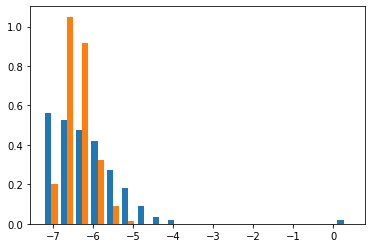

171000.0

In [62]:

optimize_tev_by_histogram (M0StarData, A_LM_M0, B_LM_M0, C_LM_M0, 1.4, 'M0', 1e3, 4e6)

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


(array([594., 488., 253.,  70.,  13.,   2.,   1.,   0.,   0.,   1.]),
 array([-4.        , -3.23124656, -2.46249311, -1.69373967, -0.92498623,
        -0.15623278,  0.61252066,  1.3812741 ,  2.15002755,  2.91878099,
         3.68753443]),
 <a list of 10 Patch objects>)

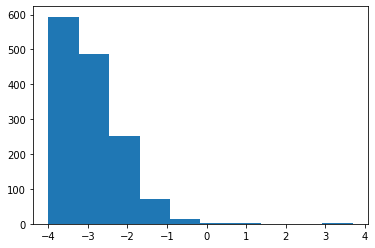

In [63]:
L_track_test, M_track_test, P_track_test, Mdot_track_test = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0,1e2,1.4,'M0',grid_steps=10000 )
mdot_per_m = Mdot_track_test/M_track_test
plot.hist(np.log10(mdot_per_m))

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:4: RuntimeWarning: invalid value encountered in power
  after removing the cwd from sys.path.


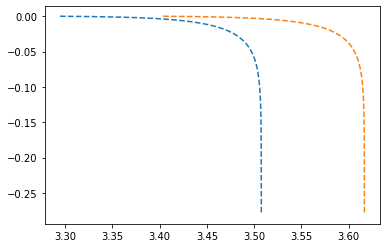

In [64]:
L_10_M0, M_10_M0, P_10_M0, Mdot_10_M0 = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, t_ev_M0,1.0,'M0',grid_steps=grid_steps )
L_10_M0_test, M_10_M0_test, P_10_M0_test, Mdot_10_M0_test = calc_evo_track (A_LM_M0, B_LM_M0, C_LM_M0, 2e5,1.0,'M0',grid_steps=grid_steps )
set_color = 'tab:blue'
plot.plot(np.log10(L_10_M0), np.log10(M_10_M0),color=set_color,linestyle=fundamental_ls)
plot.plot(np.log10(L_10_M0_test), np.log10(M_10_M0_test),color='tab:orange',linestyle=fundamental_ls)

[1.89858617 1.89860735 1.89862852 ... 2.48287819 2.51269048 2.55733144]


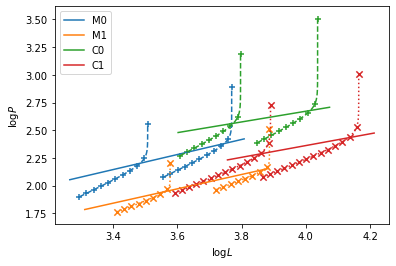

In [65]:
grid_steps = 100000
fundamental_marker = '+'
overtone_marker = 'x'
marker_size = 40
marker_increment = 1500
fundamental_ls = '--'
overtone_ls = ':'
# M0
print(np.log10(P_10_M0))
set_color = 'tab:blue'
plot.plot(M0_10th_to_90th_dl_data[0],M0_10th_to_90th_dl_period,color=set_color,label='M0')
plot.plot(np.log10(L_10_M0), np.log10(P_10_M0),color=set_color,linestyle=fundamental_ls)
plot.plot(np.log10(L_14_M0), np.log10(P_14_M0),color=set_color,linestyle=fundamental_ls)
plot.scatter(np.log10(L_10_M0)[::marker_increment], np.log10(P_10_M0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_M0)[::marker_increment], np.log10(P_14_M0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_10_M0)[-1], np.log10(P_10_M0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_M0)[-1], np.log10(P_14_M0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)

# M1
set_color = 'tab:orange'
plot.plot(M1_10th_to_90th_dl_data[0],M1_10th_to_90th_dl_period,color=set_color,label='M1')
plot.plot(np.log10(L_10_M1), np.log10(P_10_M1),color=set_color,linestyle=overtone_ls)
plot.plot(np.log10(L_14_M1), np.log10(P_14_M1),color=set_color,linestyle=overtone_ls)
plot.scatter(np.log10(L_10_M1)[::marker_increment], np.log10(P_10_M1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_M1)[::marker_increment], np.log10(P_14_M1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_10_M1)[-1], np.log10(P_10_M1)[-1],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_M1)[-1], np.log10(P_14_M1)[-1],color=set_color,s=marker_size,marker = overtone_marker)

# C0
set_color = 'tab:green'
plot.plot(C0_10th_to_90th_dl_data[0],C0_10th_to_90th_dl_period,color=set_color,label='C0')
plot.plot(np.log10(L_14_C0), np.log10(P_14_C0),color=set_color,linestyle=fundamental_ls)
plot.plot(np.log10(L_20_C0), np.log10(P_20_C0),color=set_color,linestyle=fundamental_ls)
plot.scatter(np.log10(L_14_C0)[::marker_increment], np.log10(P_14_C0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_20_C0)[::marker_increment], np.log10(P_20_C0)[::marker_increment],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_14_C0)[-1], np.log10(P_14_C0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)
plot.scatter(np.log10(L_20_C0)[-1], np.log10(P_20_C0)[-1],color=set_color,s=marker_size,marker = fundamental_marker)


# C1
set_color = 'tab:red'
plot.plot(C1_10th_to_90th_dl_data[0],C1_10th_to_90th_dl_period,color=set_color,label='C1')
plot.plot(np.log10(L_14_C1), np.log10(P_14_C1),color=set_color,linestyle=overtone_ls)
plot.plot(np.log10(L_20_C1), np.log10(P_20_C1),color=set_color,linestyle=overtone_ls)
plot.scatter(np.log10(L_14_C1)[::marker_increment], np.log10(P_14_C1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_20_C1)[::marker_increment], np.log10(P_20_C1)[::marker_increment],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_14_C1)[-1], np.log10(P_14_C1)[-1],color=set_color,s=marker_size,marker = overtone_marker)
plot.scatter(np.log10(L_20_C1)[-1], np.log10(P_20_C1)[-1],color=set_color,s=marker_size,marker = overtone_marker)

plot.xlabel(r'$\log L$')
plot.ylabel(r'$\log P$')
plot.legend()
name = "LP_deathline_M0_M1_C0_C1"
plot.savefig(name+'.pdf')
plot.savefig(name+'.png')
plot.show()
plot.close()

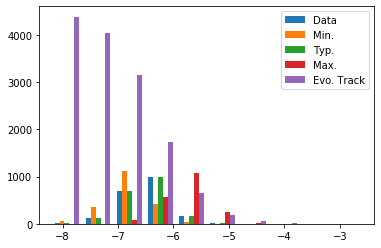

In [66]:
def dust_shift_mdot_histogram (star_data, evo_track_mdot, dtg_ratios = ratios_M):
    min_mdot_from_formula = correct_mdot (star_data, ratios_M[0])[MdotIndex]
    typical_mdot_from_formula = correct_mdot (star_data, ratios_M[1])[MdotIndex]
    max_mdot_from_formula = correct_mdot (star_data, ratios_M[2])[MdotIndex]
    min_logMdot = np.log10(min_mdot_from_formula)
    typ_logMdot = np.log10(typical_mdot_from_formula)
    max_logMdot = np.log10(max_mdot_from_formula)
    logMdotData = np.log10(star_data[MdotIndex])
    plot.hist([logMdotData,min_logMdot,typ_logMdot,max_logMdot, np.log10(evo_track_mdot)],
             label = ['Data','Min.','Typ.','Max.', 'Evo. Track'])
    plot.legend()
    plot.show()
    plot.close()
    
dust_shift_mdot_histogram (M0StarData, Mdot_10_M0)

In [67]:
def find_split_around_tev (M_list, Mdot_list, t_ev):
    # How much of the sample is found above log(Mdot/M) = log(1/tev) and how much is below.
    # By definition, Mdot_crit = M/t_ev, so Mdot_crit/M = 1/t_ev.
    # We should examine the deathzone *only*, so we should only look at the ratio between 0.1 and 10 1/t_ev.
    M_per_Mdot = M_list/Mdot_list
    Mdot_per_M = Mdot_list/M_list
    Mdot_per_M_in_DZ = []
    for i in range(0,len(M_per_Mdot)):
        if Mdot_per_M[i] < 10*1/t_ev:
            if Mdot_per_M[i] > 0.1*1/t_ev:
                Mdot_per_M_in_DZ.append(Mdot_per_M[i])
    Mdot_per_M_in_DZ = np.asarray(Mdot_per_M_in_DZ)
    
    print('#:',len(Mdot_per_M))
    number_gt_1tev = len(np.sort(Mdot_per_M_in_DZ[Mdot_per_M_in_DZ>(1/t_ev)]))
    print('# < 1/t_ev:', number_gt_1tev,'->',number_gt_1tev/len(Mdot_per_M_in_DZ)*100,'%')
    print('# > 1/t_ev:', len(Mdot_per_M_in_DZ) - number_gt_1tev,'->',(len(Mdot_per_M_in_DZ) - number_gt_1tev)/len(Mdot_per_M_in_DZ)*100,'%')

def find_split_around_dl_LM (L_list, M_list, t_ev):
    # How much of the sample is found above log(Mdot/M) = log(1/tev) and how much is below.
    # By definition, Mdot_crit = M/t_ev, so Mdot_crit/M = 1/t_ev.
    # We should examine the deathzone *only*, so we should only look at the ratio between 0.1 and 10 1/t_ev.
    M_per_Mdot = M_list/Mdot_list
    Mdot_per_M = Mdot_list/M_list
    Mdot_per_M_in_DZ = []
    for i in range(0,len(M_per_Mdot)):
        if Mdot_per_M[i] < 10*1/t_ev:
            if Mdot_per_M[i] > 0.1*1/t_ev:
                Mdot_per_M_in_DZ.append(Mdot_per_M[i])
    Mdot_per_M_in_DZ = np.asarray(Mdot_per_M_in_DZ)
    
    print('#:',len(Mdot_per_M))
    number_gt_1tev = len(np.sort(Mdot_per_M_in_DZ[Mdot_per_M_in_DZ>(1/t_ev)]))
    print('# < 1/t_ev:', number_gt_1tev,'->',number_gt_1tev/len(Mdot_per_M_in_DZ)*100,'%')
    print('# > 1/t_ev:', len(Mdot_per_M_in_DZ) - number_gt_1tev,'->',(len(Mdot_per_M_in_DZ) - number_gt_1tev)/len(Mdot_per_M_in_DZ)*100,'%')
    

In [68]:
find_split_around_tev(M_10_M0, Mdot_10_M0, t_ev_M0)
find_split_around_tev(M_14_M0, Mdot_14_M0, t_ev_M0)

#: 14207
# < 1/t_ev: 1369 -> 21.27097576134245 %
# > 1/t_ev: 5067 -> 78.72902423865756 %
#: 14207
# < 1/t_ev: 1369 -> 21.27097576134245 %
# > 1/t_ev: 5067 -> 78.72902423865756 %


In [69]:
find_split_around_tev(M_10_M1, Mdot_10_M1, t_ev_M1)
find_split_around_tev(M_14_M1, Mdot_14_M1, t_ev_M1)

#: 11058
# < 1/t_ev: 972 -> 20.061919504643964 %
# > 1/t_ev: 3873 -> 79.93808049535603 %
#: 11058
# < 1/t_ev: 972 -> 20.061919504643964 %
# > 1/t_ev: 3873 -> 79.93808049535603 %


In [70]:
find_split_around_tev(M_14_C0, Mdot_14_C0, t_ev_C0)
find_split_around_tev(M_20_C0, Mdot_20_C0, t_ev_C0)

#: 12591
# < 1/t_ev: 1311 -> 22.379651758279277 %
# > 1/t_ev: 4547 -> 77.62034824172073 %
#: 12591
# < 1/t_ev: 1311 -> 22.379651758279277 %
# > 1/t_ev: 4547 -> 77.62034824172073 %


In [71]:
find_split_around_tev(M_14_C1, Mdot_14_C1, t_ev_C1)
find_split_around_tev(M_20_C1, Mdot_20_C1, t_ev_C1)

#: 19914
# < 1/t_ev: 1929 -> 21.34321752600133 %
# > 1/t_ev: 7109 -> 78.65678247399867 %
#: 19914
# < 1/t_ev: 1929 -> 21.34321752600133 %
# > 1/t_ev: 7109 -> 78.65678247399867 %


In [72]:
def point_nearest_line (line_coords_L, line_coords_M, L_points, M_points):
    #print('line_coords',line_coords)
    x1, x2 = np.asarray(line_coords_L)
    y1, y2 = np.asarray(line_coords_M)
    dx = x2-x1
    dy = y2-y1
    dists = []
    for i in range(0, len(L_points)):
        x3 = L_points[i]
        y3 = M_points[i]
        a = (dy*y3 - dy*y1 + dx*x3 - dx*x1)/(dy**2 + dx**2)
        b = (dy*x3 - dy*x1 - dx*y3 + dx*y1)/(dy**2 + dx**2)
        dist = np.sqrt((x1+a*dx)**2+(y1+a*dy)**2)
        dists.append(dist)
    return np.nanmin(dists), np.argmin(dists)

def evaluate_tev_from_track (A, B, C, M0, spec_mode, t_ev0 = 1e4, delta_tev = 10000, L0='auto', delta_t = 1000,ifmr_relation = 'Zhao 2012',method = 'Runge-Kutta 4'):
    t_ev = t_ev0
    distances = []
    argdistances = []
    slopes = []
    t_evs = []
    while t_ev < 6e6: # Stop checking if we get a value this high. We know that is far too large.
        if spec_mode == 'M0':
            deathline_coords_LM = calc_deathline(np.log10(A_LM_M0), B_LM_M0, C_LM_M0, t_ev, 3.0, 4.0,plot_dl=False)
        elif spec_mode == 'M1':
            deathline_coords_LM = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, t_ev, 3.0, 4.0,plot_dl=False)
        elif spec_mode == 'C0':
            deathline_coords_LM = calc_deathline(np.log10(A_LM_C0), B_LM_C0, C_LM_C0, t_ev, 3.0, 4.0,plot_dl=False)
        elif spec_mode == 'C1':
            deathline_coords_LM = calc_deathline(np.log10(A_LM_C1), B_LM_C1, C_LM_C1, t_ev, 3.0, 4.0,plot_dl=False)
        t_evs.append(t_ev)
        t_array, M_array, L_array, P_array, Mdot_array = simulate_evolutionary_track(A, B, C, t_ev, M0, spec_mode, L0=L0, delta_t = delta_t,ifmr_relation = ifmr_relation,method = method,skip_period_calculations=True)
        distance, argdistance = point_nearest_line(deathline_coords_LM[0],deathline_coords_LM[1], L_array, M_array)
        distances.append(distance)
        argdistances.append(argdistance)
        mean_Delta_logL = ((np.log10(L_array[argdistance]) - np.log10(L_array[argdistance+1]))+(np.log10(L_array[argdistance-1]) - np.log10(L_array[argdistance])))/2
        mean_Delta_logM = ((np.log10(M_array[argdistance]) - np.log10(M_array[argdistance+1]))+(np.log10(M_array[argdistance-1]) - np.log10(M_array[argdistance])))/2
        slope = mean_Delta_logM/mean_Delta_logL
        slopes.append(slope)
        t_ev = t_ev + delta_tev
    # Now, we need to see which slope in slopes is closest to -1
    slopes = np.asarray(slopes)
    where_desired_slope = np.argmin(np.abs(slopes+1))
    found_tev = t_evs[where_desired_slope]
    found_slope = slopes[where_desired_slope]
    print('Slope closet to -1 found with t_ev=',found_tev,' for M0=',M0, '. Slope =',found_slope,'.')
    t_array, M_array, L_array, P_array, Mdot_array = simulate_evolutionary_track(A, B, C, t_ev, M0, spec_mode, L0=L0, delta_t = delta_t,ifmr_relation = ifmr_relation,method = method,skip_period_calculations=True)
    plot.plot(np.log10(L_array),np.log10(M_array))
    if spec_mode == 'M0':
        deathline_coords_LM = calc_deathline(np.log10(A_LM_M0), B_LM_M0, C_LM_M0, found_tev, 3.0, 4.0,plot_dl=False)
    elif spec_mode == 'M1':
        deathline_coords_LM = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, found_tev, 3.0, 4.0,plot_dl=False)
    elif spec_mode == 'C0':
        deathline_coords_LM = calc_deathline(np.log10(A_LM_C0), B_LM_C0, C_LM_C0, found_tev, 3.0, 4.0,plot_dl=False)
    elif spec_mode == 'C1':
        deathline_coords_LM = calc_deathline(np.log10(A_LM_C1), B_LM_C1, C_LM_C1, found_tev, 3.0, 4.0,plot_dl=False)
    test_dist, test_argdist = point_nearest_line(deathline_coords_LM[0],deathline_coords_LM[1], L_array,M_array)
    test_mean_Delta_logL = ((np.log10(L_array[argdistance]) - np.log10(L_array[argdistance+1]))+(np.log10(L_array[argdistance-1]) - np.log10(L_array[argdistance])))/2
    test_mean_Delta_logM = ((np.log10(M_array[argdistance]) - np.log10(M_array[argdistance+1]))+(np.log10(M_array[argdistance-1]) - np.log10(M_array[argdistance])))/2
    test_slope = mean_Delta_logM/mean_Delta_logL
    print('Test Slope =',test_slope,'.')
    if spec_mode == 'M0':
        dl_coords = calc_deathline(np.log10(A_LM_M0), B_LM_M0, C_LM_M0, found_tev, 3.0, 4.0)
        print(dl_coords)
    elif spec_mode == 'M1':
        dl_coords = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, found_tev, 3.0, 4.0)
        print(dl_coords)
    elif spec_mode == 'C0':
        dl_coords = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, found_tev, 3.0, 4.0)
        print(dl_coords)
    elif spec_mode == 'C1':
        dl_coords = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, found_tev, 3.0, 4.0)
        print(dl_coords)
    plot.xlim(3,4)
    plot.ylim(-0.5,0.5)
    
    
    return t_evs[where_desired_slope]

##### M0: logMdot = -34.98519371555522 + 8.135775205015511 logL + -13.701508306794192 logM, t_ev= 6271909.740059034
##### M1: logMdot = -42.822131870554244 + 10.148517846251726 logL + -20.479600825147386 logM, t_ev= 7415419.428848038
##### C0:  logMdot = -41.06675262075109 + 9.622154683267865 logL + -13.902542891223035 logM, t_ev= 6068913.789945056
##### C1:  logMdot= -28.151144894935417 + 5.888707448080465 logL + -9.440804631589089 logM, t_ev= 6924894.140476785

In [73]:
dl_coords_test = calc_deathline(np.log10(A_LM_M1), B_LM_M1, C_LM_M1, t_ev_M0, 3.0, 4.0)
print (dl_coords_test)

Using C_LM > 0...
[[ 3.          4.        ]
 [-0.2875545   0.18492279]]


Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:79: RuntimeWarning: invalid value encountered in double_scalars
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:78: RuntimeWarning: invalid value encountered in double_scalars
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: RuntimeWarning: invalid value encountered in double_scalars



Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_L

Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:79: RuntimeWarning: invalid value encountered in double_scalars
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:78: RuntimeWarning: invalid value encountered in double_scalars
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: RuntimeWarning: invalid value encountered in double_scalars



Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_L

Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM > 0...
Using C_LM

730000.0

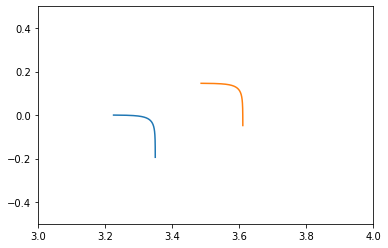

In [74]:

evaluate_tev_from_track (A_LM_M0, B_LM_M0, C_LM_M0, 1.0,  'M0', delta_t = 1000, delta_tev= 1e4)
evaluate_tev_from_track (A_LM_M0, B_LM_M0, C_LM_M0, 1.4,  'M0', delta_t = 1000, delta_tev= 1e4)

In [75]:
def mdot_minus_mdot_crit_histogram (track_array, m0, tev):
    m_array = track_array[1]
    #print(m_array)
    mdot_array = track_array[4]
    mdot_crit = m0/tev
    print('Mdot_crit',mdot_crit)
    mdot_minus_mdot_crit = np.abs(mdot_array) - mdot_crit
    plot.hist(mdot_minus_mdot_crit)
    plot.title(r'$M_0=$'+str(m0))
    plot.xlabel(r'$\dot{M} - \dot{M}_{\mathrm{crit.}}$')
    plot.show()
    plot.close()
    plot.hist(np.log10(np.abs(mdot_minus_mdot_crit)))
    plot.title(r'$M_0=$'+str(m0))
    plot.xlabel(r'$\log (\dot{M} - \dot{M}_{\mathrm{crit.}})$')
    plot.show()
    plot.close()
    plot.hist(np.log10(np.abs(mdot_array))-np.log10(mdot_crit))
    plot.title(r'$M_0=$'+str(m0))
    plot.xlabel(r'$\log (\dot{M}) - \log (\dot{M}_{\mathrm{crit.}})$')
    plot.show()
    plot.close()
    mdot_per_m_array = np.abs(mdot_array)/m_array
    #print(mdot_per_m_array)
    plot.hist(np.log10(mdot_per_m_array))
    plot.title(r'$M_0=$'+str(m0))
    plot.xlabel(r'$\log (\dot{M}/M)$')
    plot.show()
    plot.close()

In [76]:
def fraction_around_dz (track_array,m0,tev):
    mdot_array = track_array[4]
    mdot_crit = m0/tev
    mdot_minus_mdot_crit = np.abs(mdot_array) - mdot_crit
    logMdot_minus_logMdot_crit = np.log10(np.abs(mdot_array))-np.log10(mdot_crit)
    print(np.nanmin(logMdot_minus_logMdot_crit),np.nanmax(logMdot_minus_logMdot_crit))
    N_neg1_to_0 = 0
    N_0 = 0
    N_0_to_1 = 0
    N_neg1_to_1 = 0
    for i in range(0, len(mdot_minus_mdot_crit)):
        if logMdot_minus_logMdot_crit[i] > -1:
            if logMdot_minus_logMdot_crit[i] < 1:
                if logMdot_minus_logMdot_crit[i] < 0:
                    if logMdot_minus_logMdot_crit[i] > -1:
                        N_neg1_to_0 = N_neg1_to_0 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                elif logMdot_minus_logMdot_crit[i] > 0:
                    if logMdot_minus_logMdot_crit[i] < 1:
                        N_0_to_1 = N_0_to_1 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                else:
                    N_0 = N_0+1
                    N_neg1_to_1 = N_neg1_to_1 + 1
    print('N(-1, 0)/N(-1,1)=',N_neg1_to_0/N_neg1_to_1)
    print('N(0, 1)/N(-1,1)=',N_0_to_1/N_neg1_to_1)
    
def fraction_around_dz_LM (track_array,m0,tev):
    L_array = track_array[0]
    M_array = track_array[1]
    P_array = track_array[2]
    mdot_array = track_array[3]
    mdot_crit = m0/tev
    mdot_minus_mdot_crit = np.abs(mdot_array) - mdot_crit
    logMdot_minus_logMdot_crit = np.log10(np.abs(mdot_array))-np.log10(mdot_crit)
    print(np.nanmin(logMdot_minus_logMdot_crit),np.nanmax(logMdot_minus_logMdot_crit))
    N_neg1_to_0 = 0
    N_0 = 0
    N_0_to_1 = 0
    N_neg1_to_1 = 0
    for i in range(0, len(mdot_minus_mdot_crit)):
        if logMdot_minus_logMdot_crit[i] > -1:
            if logMdot_minus_logMdot_crit[i] < 1:
                if logMdot_minus_logMdot_crit[i] < 0:
                    if logMdot_minus_logMdot_crit[i] > -1:
                        N_neg1_to_0 = N_neg1_to_0 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                elif logMdot_minus_logMdot_crit[i] > 0:
                    if logMdot_minus_logMdot_crit[i] < 1:
                        N_0_to_1 = N_0_to_1 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                else:
                    N_0 = N_0+1
                    N_neg1_to_1 = N_neg1_to_1 + 1
    print('N(-1, 0)/N(-1,1)=',N_neg1_to_0/N_neg1_to_1)
    print('N(0, 1)/N(-1,1)=',N_0_to_1/N_neg1_to_1)
    
def fraction_around_dz_LP (track_array,m0,tev):
    mdot_array = track_array[4]
    mdot_crit = m0/tev
    mdot_minus_mdot_crit = np.abs(mdot_array) - mdot_crit
    logMdot_minus_logMdot_crit = np.log10(np.abs(mdot_array))-np.log10(mdot_crit)
    print(np.nanmin(logMdot_minus_logMdot_crit),np.nanmax(logMdot_minus_logMdot_crit))
    N_neg1_to_0 = 0
    N_0 = 0
    N_0_to_1 = 0
    N_neg1_to_1 = 0
    for i in range(0, len(mdot_minus_mdot_crit)):
        if logMdot_minus_logMdot_crit[i] > -1:
            if logMdot_minus_logMdot_crit[i] < 1:
                if logMdot_minus_logMdot_crit[i] < 0:
                    if logMdot_minus_logMdot_crit[i] > -1:
                        N_neg1_to_0 = N_neg1_to_0 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                elif logMdot_minus_logMdot_crit[i] > 0:
                    if logMdot_minus_logMdot_crit[i] < 1:
                        N_0_to_1 = N_0_to_1 + 1
                        N_neg1_to_1 = N_neg1_to_1 + 1
                else:
                    N_0 = N_0+1
                    N_neg1_to_1 = N_neg1_to_1 + 1
    print('N(-1, 0)/N(-1,1)=',N_neg1_to_0/N_neg1_to_1)
    print('N(0, 1)/N(-1,1)=',N_0_to_1/N_neg1_to_1)

In [77]:
# From analysis further above
#M0_tev = 3344167.9924525623
#M1_tev = 4808404.499604767
#C0_tev = 3028485.4789293325
#C1_tev = 5037864.157358862
M0_tev = t_ev_M0
M1_tev = t_ev_M1
C0_tev = t_ev_C0
C1_tev = t_ev_C1

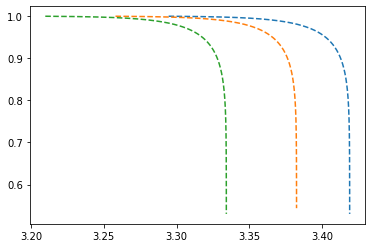

In [78]:
M0_1Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 1, 'M0', delta_t = 10)
plot.plot(np.log10(M0_1Msun_evo_track[2]),M0_1Msun_evo_track[1],color='tab:blue',linestyle='--')
M0_1Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 2*M0_tev, 1, 'M0', delta_t = 10)
plot.plot(np.log10(M0_1Msun_evo_track[2]),M0_1Msun_evo_track[1],color='tab:orange',linestyle='--')
M0_1Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 5*M0_tev, 1, 'M0', delta_t = 10)
plot.plot(np.log10(M0_1Msun_evo_track[2]),M0_1Msun_evo_track[1],color='tab:green',linestyle='--')

In [79]:
delta_logL = 0.015
delta_t_value = t_ev_M0*delta_logL/2.3
M0_0_7Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 0.7, 'M0', delta_t = delta_t_value)
M0_1Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 1, 'M0', delta_t = delta_t_value)


M0_1_2Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 1.2, 'M0', delta_t = delta_t_value)
M0_1_4Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 1.4, 'M0', delta_t = delta_t_value)
M0_1_7Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 1.7, 'M0', delta_t = delta_t_value)
M0_2Msun_evo_track = simulate_evolutionary_track(A_LM_M0, B_LM_M0, C_LM_M0, 
                                                 M0_tev, 2, 'M0', delta_t = delta_t_value)


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:79: RuntimeWarning: invalid value encountered in double_scalars


Mdot_crit 4.416701411361351e-07


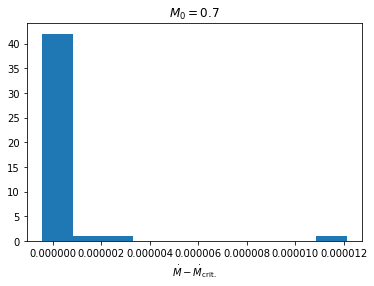

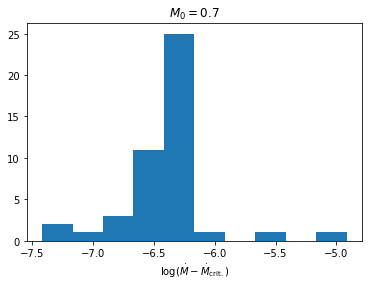

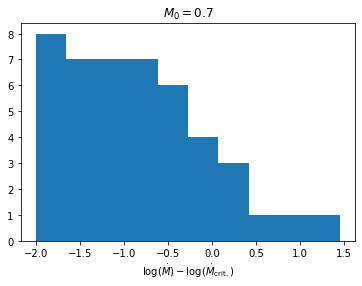

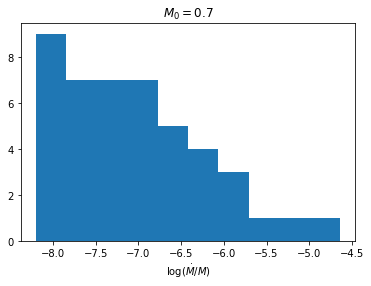

Mdot_crit 6.30957344480193e-07


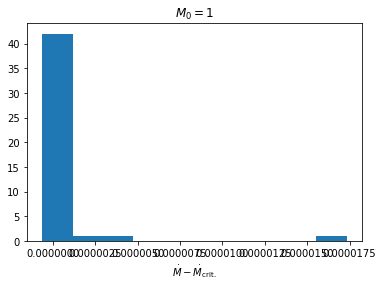

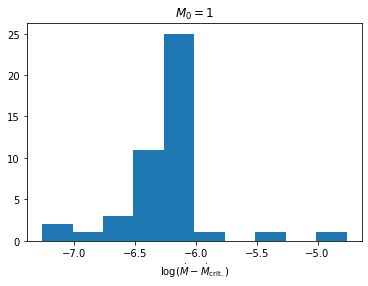

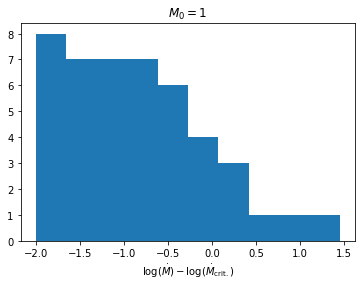

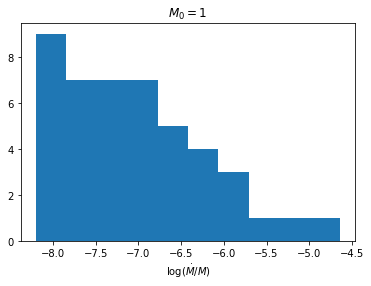

Mdot_crit 7.571488133762316e-07


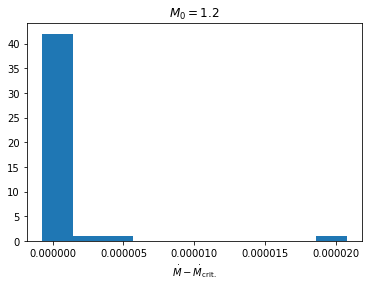

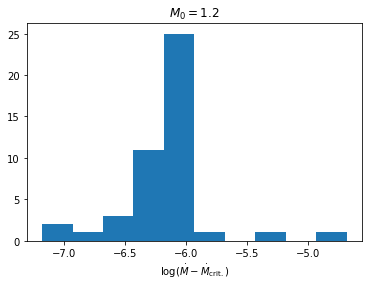

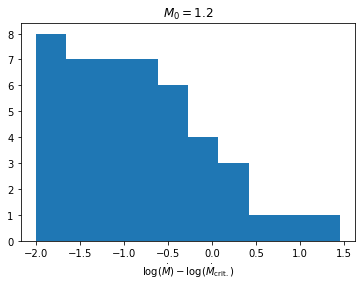

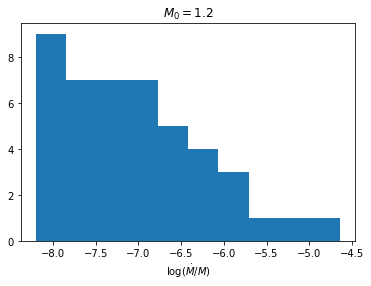

Mdot_crit 8.833402822722701e-07


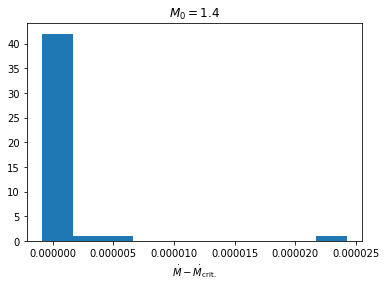

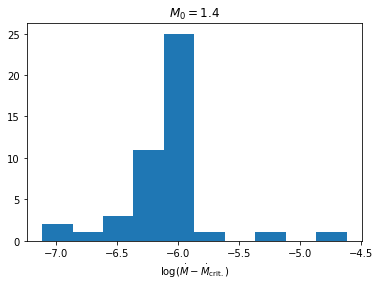

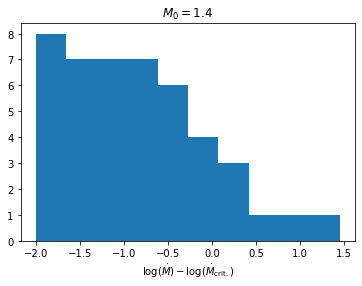

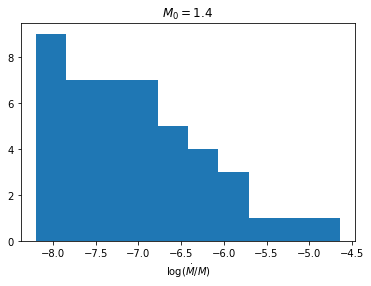

Mdot_crit 1.072627485616328e-06


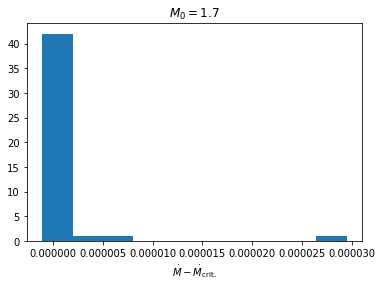

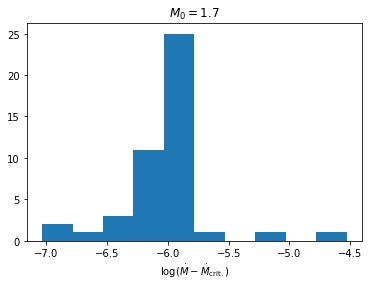

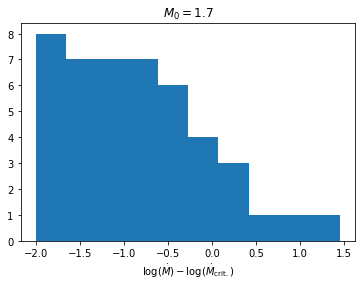

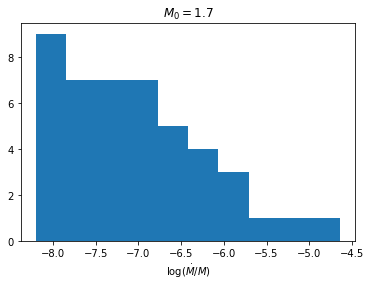

Mdot_crit 1.261914688960386e-06


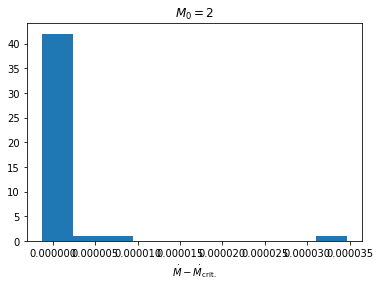

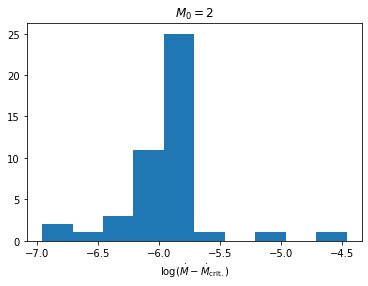

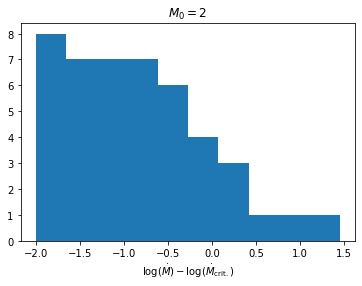

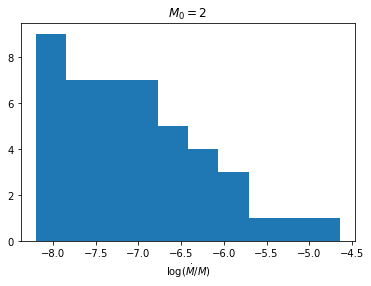

In [80]:
mdot_minus_mdot_crit_histogram ( M0_0_7Msun_evo_track, 0.7, M0_tev)
mdot_minus_mdot_crit_histogram ( M0_1Msun_evo_track, 1, M0_tev)
mdot_minus_mdot_crit_histogram ( M0_1_2Msun_evo_track, 1.2, M0_tev)
mdot_minus_mdot_crit_histogram ( M0_1_4Msun_evo_track, 1.4, M0_tev)
mdot_minus_mdot_crit_histogram ( M0_1_7Msun_evo_track, 1.7, M0_tev)
mdot_minus_mdot_crit_histogram ( M0_2Msun_evo_track, 2, M0_tev)

In [81]:
fraction_around_dz ( M0_0_7Msun_evo_track, 0.7, M0_tev)
fraction_around_dz ( M0_1Msun_evo_track, 1, M0_tev)
fraction_around_dz ( M0_1_2Msun_evo_track, 1.2, M0_tev)
fraction_around_dz ( M0_1_4Msun_evo_track, 1.4, M0_tev)
fraction_around_dz ( M0_1_7Msun_evo_track, 1.7, M0_tev)
fraction_around_dz ( M0_2Msun_evo_track, 2, M0_tev)

-2.000000000000001 1.4540075610930483
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727
-2.000000000000001 1.4540075610931131
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727
-2.000000000000001 1.4540075610930714
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727
-2.000000000000001 1.4540075610930803
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727
-2.000000000000001 1.4540075610930518
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727
-2.0 1.4540075610931131
N(-1, 0)/N(-1,1)= 0.7272727272727273
N(0, 1)/N(-1,1)= 0.2727272727272727


In [82]:
delta_logL = 0.015
delta_t_value = t_ev_M1*delta_logL/2.3

M1_0_7Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 0.7, 'M1', delta_t = delta_t_value)
M1_1Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 1, 'M1', delta_t = delta_t_value)
M1_1_2Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 1.2, 'M1', delta_t = delta_t_value)
M1_1_4Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 1.4, 'M1', delta_t = delta_t_value)
M1_1_7Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 1.7, 'M1', delta_t = delta_t_value)
M1_2Msun_evo_track = simulate_evolutionary_track(A_LM_M1, B_LM_M1, C_LM_M1, 
                                                 M1_tev, 2, 'M1', delta_t = delta_t_value)


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:90: RuntimeWarning: invalid value encountered in log10


In [83]:
fraction_around_dz ( M1_0_7Msun_evo_track, 0.7, M1_tev)
fraction_around_dz ( M1_1Msun_evo_track, 1, M1_tev)
fraction_around_dz ( M1_1_2Msun_evo_track, 1.2,M1_tev)
fraction_around_dz ( M1_1_4Msun_evo_track, 1.4, M1_tev)
fraction_around_dz ( M1_1_7Msun_evo_track, 1.7, M1_tev)
fraction_around_dz ( M1_2Msun_evo_track, 2, M1_tev)

-2.000000000000001 0.9290903344438988
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354
-2.000000000000001 0.9290903344439077
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354
-2.0000000000000027 0.929090334443857
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354
-2.000000000000001 0.9290903344438988
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354
-2.0000000000000018 0.9290903344439245
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354
-2.0000000000000018 0.9290903344439077
N(-1, 0)/N(-1,1)= 0.7058823529411765
N(0, 1)/N(-1,1)= 0.29411764705882354


In [84]:
delta_logL = 0.015
delta_t_value = t_ev_C0*delta_logL/2.3

C0_0_7Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 0.7, 'C0', delta_t = delta_t_value)
C0_1Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 1, 'C0', delta_t = delta_t_value)
C0_1_2Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 1.2, 'C0', delta_t = delta_t_value)
C0_1_4Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 1.4, 'C0', delta_t = delta_t_value)
C0_1_7Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 1.7, 'C0', delta_t = delta_t_value)
C0_2Msun_evo_track = simulate_evolutionary_track(A_LM_C0, B_LM_C0, C_LM_C0, 
                                                 C0_tev, 2, 'C0', delta_t = delta_t_value)

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:79: RuntimeWarning: invalid value encountered in double_scalars


In [85]:
fraction_around_dz ( C0_0_7Msun_evo_track, 0.7, C0_tev)
fraction_around_dz ( C0_1Msun_evo_track, 1, C0_tev)
fraction_around_dz ( C0_1_2Msun_evo_track, 1.2, C0_tev)
fraction_around_dz ( C0_1_4Msun_evo_track, 1.4, C0_tev)
fraction_around_dz ( C0_1_7Msun_evo_track, 1.7, C0_tev)
fraction_around_dz ( C0_2Msun_evo_track, 2, C0_tev)

-2.000000000000001 1.7712992703714203
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3
-2.000000000000001 1.7712992703712764
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3
-2.000000000000001 1.7712992703712134
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3
-2.000000000000001 1.7712992703714106
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3
-2.0 1.771299270371375
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3
-2.000000000000001 1.7712992703712445
N(-1, 0)/N(-1,1)= 0.7
N(0, 1)/N(-1,1)= 0.3


In [86]:
delta_logL = 0.015
delta_t_value = t_ev_C1*delta_logL/2.3

C1_0_7Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 0.7, 'C1', delta_t = delta_t_value)
C1_1Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 1, 'C1', delta_t = delta_t_value)
C1_1_2Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 1.2, 'C1', delta_t = delta_t_value)
C1_1_4Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 1.4, 'C1', delta_t = delta_t_value)
C1_1_7Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 1.7, 'C1', delta_t = delta_t_value)
C1_2Msun_evo_track = simulate_evolutionary_track(A_LM_C1, B_LM_C1, C_LM_C1, 
                                                 C1_tev, 2, 'C1', delta_t = delta_t_value)

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:78: RuntimeWarning: invalid value encountered in double_scalars


In [87]:
fraction_around_dz ( C1_0_7Msun_evo_track, 0.7, C1_tev)
fraction_around_dz ( C1_1Msun_evo_track, 1, C1_tev)
fraction_around_dz ( C1_1_2Msun_evo_track, 1.2, C1_tev)
fraction_around_dz ( C1_1_4Msun_evo_track, 1.4, C1_tev)
fraction_around_dz ( C1_1_7Msun_evo_track, 1.7, C1_tev)
fraction_around_dz ( C1_2Msun_evo_track, 2, C1_tev)

-2.000000000000001 1.0798497282415802
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225
-2.000000000000001 1.0798497282415465
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225
-2.000000000000001 1.0798497282415873
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225
-2.000000000000001 1.0798497282415784
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225
-2.000000000000001 2.3767445298178487
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225
-2.000000000000001 2.3767445298177714
N(-1, 0)/N(-1,1)= 0.7419354838709677
N(0, 1)/N(-1,1)= 0.25806451612903225


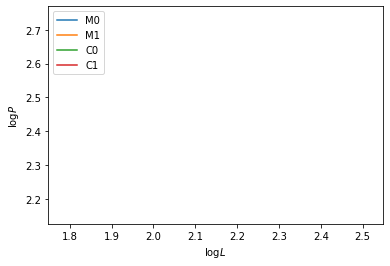

In [88]:
plot.plot(death_line_coords_LP_M0[0],death_line_coords_LP_M0[1],label='M0')
plot.plot(death_line_coords_LP_M1[0],death_line_coords_LP_M1[1],label='M1')
plot.plot(death_line_coords_LP_C0[0],death_line_coords_LP_C0[1],label='C0')
plot.plot(death_line_coords_LP_C1[0],death_line_coords_LP_C1[1],label='C1')
plot.legend()
plot.xlabel(r'$\log L$')
plot.ylabel(r'$\log P$')
name = 'percentile_death_lines_LP'
plot.savefig(name+'.pdf')
plot.savefig(name+'.png')
plot.show()
plot.close()

In [89]:
death_line_coords_LM_M0_log_lin = [death_line_coords_LM_M0[0],10**(death_line_coords_LM_M0[1])]
death_line_coords_LM_M1_log_lin = [death_line_coords_LM_M1[0],10**(death_line_coords_LM_M1[1])]
death_line_coords_LM_C0_log_lin = [death_line_coords_LM_C0[0],10**(death_line_coords_LM_C0[1])]
death_line_coords_LM_C1_log_lin = [death_line_coords_LM_C1[0],10**(death_line_coords_LM_C1[1])]

In [90]:
print(death_line_coords_LM_M0) 
print(death_line_coords_LM_M1) 
print(death_line_coords_LM_C0) 
print(death_line_coords_LM_C1)

[[ 3.24590225  3.79399787]
 [-0.15212767  0.15118697]]
[[ 3.31172245  3.88373915]
 [-0.1402753   0.12998678]]
[[3.62441471 4.09586472]
 [0.00833084 0.31273291]]
[[3.81176727 4.26847342]
 [0.04743288 0.30501924]]


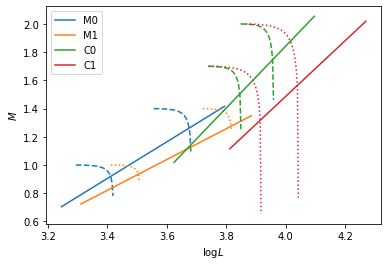

In [91]:
plot.plot(death_line_coords_LM_M0_log_lin[0],death_line_coords_LM_M0_log_lin[1],label='M0')
#plot.plot(np.log10(M0_0_7Msun_evo_track[2]),M0_0_7Msun_evo_track[1],color='tab:blue',linestyle='--')
plot.plot(np.log10(M0_1Msun_evo_track[2]),M0_1Msun_evo_track[1],color='tab:blue',linestyle='--')
#plot.plot(np.log10(M0_1_2Msun_evo_track[2]),M0_1_2Msun_evo_track[1],color='tab:blue',linestyle='--')
plot.plot(np.log10(M0_1_4Msun_evo_track[2]),M0_1_4Msun_evo_track[1],color='tab:blue',linestyle='--')
#plot.plot(np.log10(M0_1_7Msun_evo_track[2]),M0_1_7Msun_evo_track[1],color='tab:blue',linestyle='--')
#plot.plot(np.log10(M0_2Msun_evo_track[2]),M0_2Msun_evo_track[1],color='tab:blue',linestyle='--')
plot.plot(death_line_coords_LM_M1_log_lin[0],death_line_coords_LM_M1_log_lin[1],label='M1')
#plot.plot(np.log10(M1_0_7Msun_evo_track[2]),M1_0_7Msun_evo_track[1],color='tab:orange',linestyle=':')
plot.plot(np.log10(M1_1Msun_evo_track[2]),M1_1Msun_evo_track[1],color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_1_2Msun_evo_track[2]),M1_1_2Msun_evo_track[1],color='tab:orange',linestyle=':')
plot.plot(np.log10(M1_1_4Msun_evo_track[2]),M1_1_4Msun_evo_track[1],color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_1_7Msun_evo_track[2]),M1_1_7Msun_evo_track[1],color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_2Msun_evo_track[2]),M1_2Msun_evo_track[1],color='tab:orange',linestyle=':')
plot.plot(death_line_coords_LM_C0_log_lin[0],death_line_coords_LM_C0_log_lin[1],label='C0')
#plot.plot(np.log10(C0_0_7Msun_evo_track[2]),C0_0_7Msun_evo_track[1],color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1Msun_evo_track[2]),C0_1Msun_evo_track[1],color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1_2Msun_evo_track[2]),C0_1_2Msun_evo_track[1],color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1_4Msun_evo_track[2]),C0_1_4Msun_evo_track[1],color='tab:green',linestyle='--')
plot.plot(np.log10(C0_1_7Msun_evo_track[2]),C0_1_7Msun_evo_track[1],color='tab:green',linestyle='--')
plot.plot(np.log10(C0_2Msun_evo_track[2]),C0_2Msun_evo_track[1],color='tab:green',linestyle='--')
plot.plot(death_line_coords_LM_C1_log_lin[0],death_line_coords_LM_C1_log_lin[1],label='C1')
#plot.plot(np.log10(C1_0_7Msun_evo_track[2]),C1_0_7Msun_evo_track[1],color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1Msun_evo_track[2]),C1_1Msun_evo_track[1],color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1_2Msun_evo_track[2]),C1_1_2Msun_evo_track[1],color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1_4Msun_evo_track[2]),C1_1_4Msun_evo_track[1],color='tab:red',linestyle=':')
plot.plot(np.log10(C1_1_7Msun_evo_track[2]),C1_1_7Msun_evo_track[1],color='tab:red',linestyle=':')
plot.plot(np.log10(C1_2Msun_evo_track[2]),C1_2Msun_evo_track[1],color='tab:red',linestyle=':')
plot.legend()
plot.xlabel(r'$\log L$')
plot.ylabel(r'$M$')
name = 'percentile_death_lines_LM_log_lin'
plot.savefig(name+'.pdf')
plot.savefig(name+'.png')
plot.show()
plot.close()

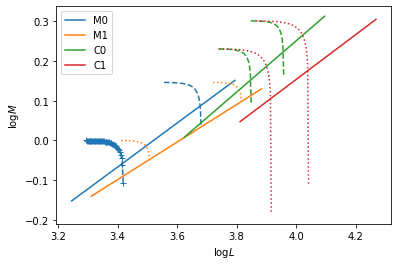

In [92]:
plot.plot(death_line_coords_LM_M0[0],death_line_coords_LM_M0[1],label='M0')
#plot.plot(np.log10(M0_0_7Msun_evo_track[2]),np.log10(M0_0_7Msun_evo_track[1]),color='tab:blue',linestyle='--')
plot.plot(np.log10(M0_1Msun_evo_track[2]),np.log10(M0_1Msun_evo_track[1]),color='tab:blue',linestyle='--',marker='+')
#plot.plot(np.log10(M0_1_2Msun_evo_track[2]),np.log10(M0_1_2Msun_evo_track[1]),color='tab:blue',linestyle='--')
plot.plot(np.log10(M0_1_4Msun_evo_track[2]),np.log10(M0_1_4Msun_evo_track[1]),color='tab:blue',linestyle='--')
#plot.plot(np.log10(M0_1_7Msun_evo_track[2]),np.log10(M0_1_7Msun_evo_track[1]),color='tab:blue',linestyle='--')
#plot.plot(np.log10(M0_2Msun_evo_track[2]),np.log10(M0_2Msun_evo_track[1]),color='tab:blue',linestyle='--')

plot.plot(death_line_coords_LM_M1[0],death_line_coords_LM_M1[1],label='M1')
#plot.plot(np.log10(M1_0_7Msun_evo_track[2]),np.log10(M1_0_7Msun_evo_track[1]),color='tab:orange',linestyle=':')
plot.plot(np.log10(M1_1Msun_evo_track[2]),np.log10(M1_1Msun_evo_track[1]),color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_1_2Msun_evo_track[2]),np.log10(M1_1_2Msun_evo_track[1]),color='tab:orange',linestyle=':')
plot.plot(np.log10(M1_1_4Msun_evo_track[2]),np.log10(M1_1_4Msun_evo_track[1]),color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_1_7Msun_evo_track[2]),np.log10(M1_1_7Msun_evo_track[1]),color='tab:orange',linestyle=':')
#plot.plot(np.log10(M1_2Msun_evo_track[2]),np.log10(M1_2Msun_evo_track[1]),color='tab:orange',linestyle=':')

plot.plot(death_line_coords_LM_C0[0],death_line_coords_LM_C0[1],label='C0')
#plot.plot(np.log10(C0_0_7Msun_evo_track[2]),np.log10(C0_0_7Msun_evo_track[1]),color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1Msun_evo_track[2]),np.log10(C0_1Msun_evo_track[1]),color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1_2Msun_evo_track[2]),np.log10(C0_1_2Msun_evo_track[1]),color='tab:green',linestyle='--')
#plot.plot(np.log10(C0_1_4Msun_evo_track[2]),np.log10(C0_1_4Msun_evo_track[1]),color='tab:green',linestyle='--')
plot.plot(np.log10(C0_1_7Msun_evo_track[2]),np.log10(C0_1_7Msun_evo_track[1]),color='tab:green',linestyle='--')
plot.plot(np.log10(C0_2Msun_evo_track[2]),np.log10(C0_2Msun_evo_track[1]),color='tab:green',linestyle='--')

plot.plot(death_line_coords_LM_C1[0],death_line_coords_LM_C1[1],label='C1')
#plot.plot(np.log10(C1_0_7Msun_evo_track[2]),np.log10(C1_0_7Msun_evo_track[1]),color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1Msun_evo_track[2]),np.log10(C1_1Msun_evo_track[1]),color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1_2Msun_evo_track[2]),np.log10(C1_1_2Msun_evo_track[1]),color='tab:red',linestyle=':')
#plot.plot(np.log10(C1_1_4Msun_evo_track[2]),np.log10(C1_1_4Msun_evo_track[1]),color='tab:red',linestyle=':')
plot.plot(np.log10(C1_1_7Msun_evo_track[2]),np.log10(C1_1_7Msun_evo_track[1]),color='tab:red',linestyle=':')
plot.plot(np.log10(C1_2Msun_evo_track[2]),np.log10(C1_2Msun_evo_track[1]),color='tab:red',linestyle=':')
plot.legend()
plot.xlabel(r'$\log L$')
plot.ylabel(r'$\log M$')
name = 'percentile_death_lines_LM_log_log'
plot.savefig(name+'.pdf')
plot.savefig(name+'.png')
plot.show()
plot.close()

In [93]:
    n = 1000
    level_strs = []
    for level in range(0,len(contour_levels)):
        level_strs.append(str(contour_levels[level]))
        
    contour_L_LP, contour_P_LP = np.mgrid[logL_min:logL_max:100j, logP_min:logP_max:100j]
    positions_LP = np.vstack([contour_L_LP.ravel(), contour_P_LP.ravel()])
    values_LP = np.vstack([logLData, logPData])
    kernel_LP = sp.stats.gaussian_kde(values_LP)
    Z_LP = np.reshape(kernel_LP(positions_LP).T, contour_L_LP.shape)
    Z_LP = Z_LP/Z_LP.sum()
    t_LP = np.linspace(0, Z_LP.max(), n)
    integral_LP = ((Z_LP >= t_LP[:, None, None]) * Z_LP).sum(axis=(1,2))
    f_LP = interpolate.interp1d(integral_LP, t_LP, fill_value=0.0)
    t_contours_LP = f_LP(np.array(contour_levels))
    plot.contour(Z_LP.T, t_contours_LP,
                      extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],
                      cmap=plt.cm.cool)
    
    positions_LM = np.vstack([contour_L_LM.ravel(), contour_M_LM.ravel()])
    contour_L_LM, contour_M_LM = np.mgrid[logL_min:logL_max:100j, logM_min:logM_max:100j]
    values_LM = np.vstack([logLData, logMData])
    kernel_LM = sp.stats.gaussian_kde(values_LM)
    Z_LM = np.reshape(kernel_LM(positions_LM).T, contour_L_LM.shape)
    Z_LM = Z_LM/Z_LM.sum()
    t_LM = np.linspace(0, Z_LM.max(), n)
    integral_LM = ((Z_LM >= t_LM[:, None, None]) * Z_LM).sum(axis=(1,2))
    f_LM = interpolate.interp1d(integral_LM, t_LM, fill_value=0.0)
    t_contours_LM = f_LM(np.array(contour_levels))

NameError: name 'contour_levels' is not defined

In [ ]:
def multi_contour_plot (star_data_list,plot_type='LP',label_list = [],
                        cmap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens, plt.cm.Reds],
                        color_list = ['tab:blue','tab:orange','tab:green','tab:red'],
                        save_figs = False, include_evo_tracks = False):
    
    fig, ax = plt.subplots()
    handles, labels  = plt.gca().get_legend_handles_labels()
    contour_levels=[0.9,0.7,0.5,0.3,0.1]
    for i in range(0, len(star_data_list)):
        star_data = star_data_list[i]
        logLData = np.log10(star_data[LIndex])
        logL_min = np.nanmin(logLData)
        logL_max = np.nanmax(logLData)
        logPData = np.log10(star_data[PIndex])
        logP_min = np.nanmin(logPData)
        logP_max = np.nanmax(logPData)
        logMData = np.log10(star_data[MIndex])
        logM_min = np.nanmin(logMData)
        logM_max = np.nanmax(logMData)
        n=1000
        if plot_type == 'LP':
            contour_L_LP, contour_P_LP = np.mgrid[logL_min:logL_max:100j, logP_min:logP_max:100j]
            positions_LP = np.vstack([contour_L_LP.ravel(), contour_P_LP.ravel()])
            values_LP = np.vstack([logLData, logPData])
            kernel_LP = sp.stats.gaussian_kde(values_LP)
            Z_LP = np.reshape(kernel_LP(positions_LP).T, contour_L_LP.shape)
            Z_LP = Z_LP/Z_LP.sum()
            t_LP = np.linspace(0, Z_LP.max(), n)
            integral_LP = ((Z_LP >= t_LP[:, None, None]) * Z_LP).sum(axis=(1,2))
            f_LP = interpolate.interp1d(integral_LP, t_LP, fill_value=0.0)
            t_contours_LP = f_LP(np.array(contour_levels))
            plot.contour(Z_LP.T, t_contours_LP,
                      extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logPData),np.nanmax(logPData)],
                      cmap=cmap_list[i])
            #plot.scatter(logLData,logPData,s=2, label=label_list[i],alpha=0.1,color=color_list[i])
            #plot.xlabel('log L')
            #plot.ylabel('log P')
            if include_evo_tracks == True:
                for k in range(0, len(label_list)):
                    if label_list[k] == 'M0':
                        plot.plot(np.log10(L_10_M0), np.log10(P_10_M0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_14_M0), np.log10(P_14_M0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'M1':
                        plot.plot(np.log10(L_10_M1), np.log10(P_10_M1),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_14_M1), np.log10(P_14_M1),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C0':
                        plot.plot(np.log10(L_14_C0), np.log10(P_14_C0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C0), np.log10(P_20_C0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C0 and C0x':
                        plot.plot(np.log10(L_14_C0), np.log10(P_14_C0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C0), np.log10(P_20_C0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C1':
                        plot.plot(np.log10(L_14_C1), np.log10(P_14_C1),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C1), np.log10(P_20_C1),color=color_list[k],linestyle='--')
        
        if plot_type == 'LM':
            contour_L_LM, contour_M_LM = np.mgrid[logL_min:logL_max:100j, logM_min:logM_max:100j]
            positions_LM = np.vstack([contour_L_LM.ravel(), contour_M_LM.ravel()])
            values_LM = np.vstack([logLData, logMData])
            kernel_LM = sp.stats.gaussian_kde(values_LM)
            Z_LM = np.reshape(kernel_LM(positions_LM).T, contour_L_LM.shape)
            Z_LM = Z_LM/Z_LM.sum()
            t_LM = np.linspace(0, Z_LM.max(), n)
            integral_LM = ((Z_LM >= t_LM[:, None, None]) * Z_LM).sum(axis=(1,2))
            f_LM = interpolate.interp1d(integral_LM, t_LM, fill_value=0.0)
            t_contours_LM = f_LM(np.array(contour_levels))
            plot.contour(Z_LM.T, t_contours_LM,
                      extent=[np.nanmin(logLData),np.nanmax(logLData),np.nanmin(logMData),np.nanmax(logMData)],
                      cmap=cmap_list[i])
            #plot.scatter(logLData,logMData,s=2, label=label_list[i],alpha=0.1,color=color_list[i])
            if include_evo_tracks == True:
                for k in range(0, len(label_list)):
                    if label_list[k] == 'M0':
                        plot.plot(np.log10(L_10_M0), np.log10(M_10_M0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_14_M0), np.log10(M_14_M0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'M1':
                        plot.plot(np.log10(L_10_M1), np.log10(M_10_M1),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_14_M1), np.log10(M_14_M1),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C0':
                        plot.plot(np.log10(L_14_C0), np.log10(M_14_C0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C0), np.log10(M_20_C0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C0 and C0x':
                        plot.plot(np.log10(L_14_C0), np.log10(M_14_C0),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C0), np.log10(M_20_C0),color=color_list[k],linestyle='--')
                    elif label_list[k] == 'C1':
                        plot.plot(np.log10(L_14_C1), np.log10(M_14_C1),color=color_list[k],linestyle='--')
                        plot.plot(np.log10(L_20_C1), np.log10(M_20_C1),color=color_list[k],linestyle='--')
    lines = [plt.Line2D([0],[0],color = c, linewidth = 2, linestyle='-') for c in color_list]
    plot.legend(lines, label_list)
    
    if plot_type == 'LP':
        plot.xlabel(r'$\log L$')
        plot.ylabel(r'$\log P$')
    if plot_type == 'LM':
        plot.xlabel(r'$\log L$')
        plot.ylabel(r'$\log M$')
        
    if save_figs == True:
        name = plot_type+'_'+'contour'+'_'
        for i in range(0, len(label_list)):
            name = name + '_'+label_list[i]
        plot.savefig(name+'.pdf')
        plot.savefig(name+'.png')
    plot.show()
    plot.close()

In [ ]:
multi_contour_plot([M0StarData, M1StarData, C0StarData, C1StarData],plot_type='LM',label_list = ['M0', 'M1', 'C0', 'C1'],save_figs=True,include_evo_tracks=True)
multi_contour_plot([M0StarData, M1StarData],plot_type='LM',label_list = ['M0', 'M1'], cmap_list = [plt.cm.Blues, plt.cm.Reds],color_list = ['tab:blue','tab:red'],save_figs=True,include_evo_tracks=True)
multi_contour_plot([C0StarData, C1StarData],plot_type='LM',label_list = ['C0', 'C1'], cmap_list = [plt.cm.Greens, plt.cm.Purples],color_list = ['tab:green','tab:purple'],save_figs=True,include_evo_tracks=True)
multi_contour_plot([M0StarData, C0StarData],plot_type='LM',label_list = ['M0', 'C0'], cmap_list = [plt.cm.Blues, plt.cm.Greens],color_list = ['tab:blue','tab:green'],save_figs=True,include_evo_tracks=True)
multi_contour_plot([M1StarData, C1StarData],plot_type='LM',label_list = ['M1', 'C1'], cmap_list = [plt.cm.Reds, plt.cm.Purples],color_list = ['tab:red','tab:purple'],save_figs=True,include_evo_tracks=True)


In [ ]:
multi_contour_plot([M0StarData, M1StarData, C0StarData, C1StarData],plot_type='LP',label_list = ['M0', 'M1', 'C0', 'C1'],include_evo_tracks=True)
multi_contour_plot([M0StarData, M1StarData],plot_type='LP',label_list = ['M0', 'M1'], cmap_list = [plt.cm.Blues, plt.cm.Reds],color_list = ['tab:blue','tab:red'], include_evo_tracks=True)
multi_contour_plot([C0StarData, C1StarData],plot_type='LP',label_list = ['C0', 'C1'], cmap_list = [plt.cm.Greens, plt.cm.Purples],color_list = ['tab:green','tab:purple'],include_evo_tracks=True)
multi_contour_plot([M0StarData, C0StarData],plot_type='LP',label_list = ['M0', 'C0'], cmap_list = [plt.cm.Blues, plt.cm.Greens],color_list = ['tab:blue','tab:green'],include_evo_tracks=True)
multi_contour_plot([M1StarData, C1StarData],plot_type='LP',label_list = ['M1', 'C1'], cmap_list = [plt.cm.Reds, plt.cm.Purples],color_list = ['tab:red','tab:purple'],include_evo_tracks=True)

In [ ]:
log10MStarMass = np.hstack([np.log10(M0StarData[MIndex]),np.log10(M1StarData[MIndex])])
log10CStarMass = np.hstack([np.log10(C0StarData[MIndex]),np.log10(C1StarData[MIndex])])
log10MStarLum = np.hstack([np.log10(M0StarData[LIndex]),np.log10(M1StarData[LIndex])])
log10CStarLum = np.hstack([np.log10(C0StarData[LIndex]),np.log10(C1StarData[LIndex])])

In [ ]:
plot.hist([np.log10(M0StarData[MIndex]),np.log10(M1StarData[MIndex]),np.log10(C0StarData[MIndex]),np.log10(C1StarData[MIndex])],
          histtype='bar')

In [ ]:
histogram_out = plot.hist([np.log10(M0StarData[MIndex]),np.log10(M1StarData[MIndex]),np.log10(C0StarData[MIndex]),np.log10(C1StarData[MIndex])],
          histtype='bar',label=['M0','M1', 'C0', 'C1'])
plot.xlabel(r'$\log M$')
plot.legend()
plot.show()
plot.close()
print(histogram_out)

In [ ]:
histogram_out = plot.hist([log10MStarMass,log10CStarMass],
          histtype='bar',label=['M','C'])
plot.xlabel(r'$\log M$')
plot.legend()
plot.savefig('mass_histogram.pdf')
plot.savefig('mass_histogram.png')
plot.show()
plot.close()
print(histogram_out)

In [ ]:
histogram_out[1]

In [ ]:
plot.scatter(np.log10(M0StarData[LIndex]),np.log10(M0StarData[MIndex]),s=5,marker='.')
plot.scatter(np.log10(M1StarData[LIndex]),np.log10(M1StarData[MIndex]),s=5,marker='.')
plot.scatter(np.log10(C0StarData[LIndex]),np.log10(C0StarData[MIndex]),s=5,marker='.')
plot.scatter(np.log10(C1StarData[LIndex]),np.log10(C1StarData[MIndex]),s=5,marker='.')
plot.plot([3.0,4.4],np.log10([1.3,1.3]),color='k',linestyle='--')
plot.plot([3.0,4.4],[0.3,0.3],color='k',linestyle='-')

In [ ]:
bin_ids_M = np.digitize(log10MStarMass,histogram_out[1])
bin_ids_C = np.digitize(log10CStarMass,histogram_out[1])

In [ ]:
def bin_sort (digitized_data):
    indices_by_bin = [] # List of lists of indices, ordered by bin #
    num_bins = np.nanmax(digitized_data) # The number of bins
    for i in range(1, num_bins+1): # Loop over each bin index
        index_by_bin = []
        for k in range(0, len(digitized_data)): # Loop over each element in digitized data
            if digitized_data[k] == i:
                index_by_bin.append(k)
        indices_by_bin.append(index_by_bin)
    return indices_by_bin
bin_sorted_M_indices = bin_sort(bin_ids_M)
bin_sorted_C_indices = bin_sort(bin_ids_C)

In [ ]:
for i in range(0, len(bin_sorted_M_indices)):
    plot.scatter(log10MStarLum[bin_sorted_M_indices[i]],log10MStarMass[bin_sorted_M_indices[i]],s=5,marker='d')


In [ ]:
for i in range(0, len(bin_sorted_C_indices)):
    plot.scatter(log10CStarLum[bin_sorted_C_indices[i]],log10CStarMass[bin_sorted_C_indices[i]],s=5,marker='s')

In [ ]:
for i in range(0, len(bin_sorted_M_indices)):
    plot.scatter(log10MStarLum[bin_sorted_M_indices[i]],log10MStarMass[bin_sorted_M_indices[i]],s=7,marker='s')
for i in range(0, len(bin_sorted_C_indices)):
    plot.scatter(log10CStarLum[bin_sorted_C_indices[i]],log10CStarMass[bin_sorted_C_indices[i]],s=7,marker='o')

In [ ]:
logLData = np.log10(M0StarData[LIndex])
logL_min = np.nanmin(logLData)
logL_max = np.nanmax(logLData)
logPData = np.log10(M0StarData[PIndex])
logP_min = np.nanmin(logPData)
logP_max = np.nanmax(logPData)
logMData = np.log10(M0StarData[MIndex])
logM_min = np.nanmin(logMData)
logM_max = np.nanmax(logMData)


contour_L_LP, contour_P_LP = np.mgrid[logL_min:logL_max:100j, logP_min:logP_max:100j]
contour_L_LM, contour_M_LM = np.mgrid[logL_min:logL_max:100j, logM_min:logM_max:100j]
positions_LP = np.vstack([contour_L_LP.ravel(), contour_P_LP.ravel()])
positions_LM = np.vstack([contour_L_LM.ravel(), contour_M_LM.ravel()])
values_LP = np.vstack([logLData, logPData])
values_LM = np.vstack([logLData, logMData])
kernel_LP = sp.stats.gaussian_kde(values_LP)
kernel_LM = sp.stats.gaussian_kde(values_LM)
Z_LP = np.reshape(kernel_LP(positions_LP).T, contour_L_LP.shape)
Z_LM = np.reshape(kernel_LM(positions_LM).T, contour_L_LP.shape)


fig, ax = plt.subplots()
ax.imshow(np.rot90(Z_LP), cmap=plt.cm.Blues,
          extent=[logL_min, logL_max, logP_min, logP_max])
plt.xlabel('Test Label')
plt.show()
plt.close()

In [ ]:
def measure(n):
    "Measurement model, return two coupled measurements."
    m1 = np.random.normal(size=n)
    m2 = np.random.normal(scale=0.5, size=n)
    return m1+m2, m1-m2

m1, m2 = [logLData, logPData]
xmin = m1.min()
xmax = m1.max()
ymin = m2.min()
ymax = m2.max()

X, Y = np.mgrid[xmin:xmax:100j, ymin:ymax:100j]
positions = np.vstack([X.ravel(), Y.ravel()])
print(np.shape(positions))
values = np.vstack([m1, m2])
kernel = sp.stats.gaussian_kde(values)
Z = np.reshape(kernel(positions).T, X.shape)

fig, ax = plt.subplots()
ax.imshow(np.rot90(Z), cmap=plt.cm.gist_earth_r,
          extent=[xmin, xmax, ymin, ymax])
plt.scatter(m1, m2,s=10)
ax.plot(m1, m2, 'k.', markersize=2)
#ax.set_xlim([xmin, xmax])
#ax.set_ylim([ymin, ymax])
plt.show()

In [ ]:
def equations(p):
    x, y = p
    return (x+y**2-4, math.exp(x) + x*y - 3)

x, y =  fsolve(equations, (1, 1))

print (equations((x, y)))

In [ ]:
def check_for_0 (list_o_things):
    for i in range(0, len(list_o_things)):
        if list_o_things[i] ==0:
            print('0 encountered at index ', i)

In [ ]:
def eq_lt_break_M(p, logL_var, logP_var):
    logR, M, logL, logP = p
    RLM = RLM_M # RLM_M = [-0.241, 0.690, -0.251]; logR = A + BlogL + ClogM
    # slope_alpha = np.log(49.7)-0.279*np.log(star_mass/2.6)
    return (logR-RLM[0]-RLM[1]*logL-RLM[2]*np.log10(M), logR - (1/np.log(49.7)-0.279*np.log10(M/2.6))*(logP - np.log10(440)+0.976*np.log10(M/2.6))+np.log10(421)+0.952*np.log10(M/2.6), logL - logL_var, logP - logP_var )

def eq_lt_break_C(p, logL_var, logP_var):
    logR, M, logL, logP= p
    RLM = RLM_C # RLM_C = [-0.323, 0.737, -0.371]; logR = A + BlogL + ClogM
    # slope_alpha = np.log(49.7)-0.279*np.log(star_mass/2.6)
    return (logR-RLM[0]-RLM[1]*logL-RLM[2]*np.log10(M), logR - (1/(np.log(49.7)-0.279*np.log10(M/2.6)))*(logP - np.log10(440)+0.976*np.log10(M/2.6))+np.log10(421)+0.952*np.log10(M/2.6), logL - logL_var, logP - logP_var )

In [ ]:
def eq_lt_break_M(variable_vector):
    logR, M, logL, logP = variable_vector
    RLM = RLM_M # RLM_M = [-0.241, 0.690, -0.251]; logR = A + BlogL + ClogM
    # slope_alpha = np.log(49.7)-0.279*np.log(star_mass/2.6)
    function_array = np.empty((2))
    function_array[0] = logR-RLM[0]-RLM[1]*logL-RLM[2]*np.log10(M)
    function_array[1] = logR - (1/(np.log(49.7)-0.279*np.log10(M/2.6)))*(logP - np.log10(440)+0.976*np.log10(M/2.6))+np.log10(421)+0.952*np.log10(M/2.6)
    function_array[2] = logL - logL_var
    function_array[3] = logP - logP_var
    
    return function_array

def eq_lt_break_C(variable_vector):
    logR, M, logL, logP= variable_vector
    RLM = RLM_C # RLM_C = [-0.323, 0.737, -0.371]; logR = A + BlogL + ClogM
    # slope_alpha = np.log(49.7)-0.279*np.log(star_mass/2.6)
    function_array = np.empty((2))
    function_array[0] = logR-RLM[0]-RLM[1]*logL-RLM[2]*np.log10(M)
    function_array[1] = logR - (1/(np.log(49.7)-0.279*np.log10(M/2.6)))*(logP - np.log10(440)+0.976*np.log10(M/2.6))+np.log10(421)+0.952*np.log10(M/2.6)
    
    return function_array

In [ ]:
# Implementation of non-linear PMR relation found in Trabucchi et al. 2021

def calc_log_P_break (star_mass):
    if star_mass < 2.6:
        logP_break = np.log10(440)+0.976*np.log10(star_mass/2.6)
    elif star_mass >= 2.6:
        logP_break = np.log10(440)-0.264*np.log10(star_mass/2.6)
    return logP_break

def calc_log_R_break (star_mass):
    if star_mass < 2.6:
        logR_break = np.log10(421)+0.952*np.log10(star_mass/2.6)
    elif star_mass >= 2.6:
        logR_break = np.log10(421)+0.114*np.log10(star_mass/2.6)
    return logR_break

def calc_log_P_sat (star_mass):
    if star_mass < 1.0:
        logP_sat = np.log10(388)+1.808*np.log10(star_mass/1.0)
    elif star_mass >= 1.0:
        logP_sat = np.log10(388)+0.502*np.log10(star_mass/1.0)
    return logP_sat

def calc_log_R_sat (star_mass):
    if star_mass < 1.0:
        logR_sat = np.log10(311)+1.590*np.log10(star_mass/1.0)
    elif star_mass >= 1.0:
        logR_sat = np.log10(311)+0.654*np.log10(star_mass/1.0)
    return logR_sat

def calc_slope_alpha (star_mass):
    if star_mass < 2.6:
        slope_alpha = np.log10(49.7)-0.279*np.log10(star_mass/2.6)
    elif star_mass >= 2.6:
        slope_alpha = np.log10(49.7)+0.544*np.log10(star_mass/2.6)
    return slope_alpha

def calc_slope_beta (star_mass):
    logP_break = calc_log_P_break(star_mass)
    logP_sat = calc_log_P_sat(star_mass)
    logR_break = calc_log_R_break(star_mass)
    logR_sat = calc_log_R_sat(star_mass)
    slope_beta = (logP_break-logP_sat)/(logR_break-logR_sat)
    return slope_beta
def calc_mass_from_nonlinear (star_data, spec_mode = 'None', method_option = 'None', GT_option = 'None'):
    LData = star_data[LIndex]
    logLData = np.log10(LData)
    PData = star_data[PIndex]
    logPData = np.log10(PData)
    if spec_mode == 'M0':
        RLM = RLM_M # RLM_M = [-0.241, 0.690, -0.251]; logR = A + BlogL + ClogM
    elif spec_mode == 'C0':
        RLM = RLM_C # RLM_C = [-0.323, 0.737, -0.371]; logR = A + BlogL + ClogM
    else:
        print('Error. No spectal class+pulsation mode identifier specified.')
    
    if method_option == 'All LT Break':
        # Easiest calculation. Approximation tells us that almsot all stars in sample should be less than 2.6 solar masses.
        # This choice leaves us with no remaining degeneracy.
        logRData = []
        MData = []
        for i in range(0,len(logLData)):
            logP_var = logPData[i]
            logL_var = logLData[i]
            if spec_mode == 'M0':
                logR_sol, M_sol, logL, logP =  fsolve(eq_lt_break_M, (100, 1, logL_var, logP_var))
                solution = eq_lt_break_M((logR, M, logL, logP))
            elif spec_mode == 'C0':
                logR, M, logL_dum, logP_dum =  fsolve(eq_lt_break_C, (100, 1, logL_var, logP_var))
                solution = eq_lt_break_C((logR, M, logL, logP))
            print(solution)
            logRData.append(solution[0])
            MData.append(solution[1])
        logRData = np.asarray(logRData)
        MData = np.asarray(MData)
        print('Checking MData for zeroes...')
        check_for_0(MData)
        logMData = np.log10(MData)
    elif method_option == 'All GT Break':
        # Harder calculation. Many stars fall around 1 solar mass. We must choose how to assign those.
        # Idea: Assign degenerate option somehow (assume all LT 1, assume all GT 1, randomly). Then, check the output mass.
        # If the output mass does not match the assumption, recalculate the mass with the other choice.
        if GT_option == 'Assume LT 1':
            print('Placeholder')
        elif GT_option == 'Assume GT 1':
            print('Placeholder')
        elif GT_option == 'Random Assignment':
            print('Placeholder')
    elif method_option == 'Random Assignment':
        # About the same as the above option. Bit of extra bells and whistles needed to assign options randomly, but
        # in principle no new calculations.
            print('Placeholder')
    else:
        print ('Error. No Method Selected.')
        
    return logRData, logMData

In [ ]:
calc_mass_from_nonlinear (M0StarData, spec_mode = 'M0', method_option='All LT Break')

In [ ]:
def sample_check (star_data, Index_to_check, bound):
    data = star_data[Index_to_check]
    test_list = []
    for i in range(0, len(data)):
        if data[i] > bound:
            test_list.append(i)
    print('N above bound:', len(test_list))
    print('Percent above bound:', len(test_list)/len(data)*100,'%')
    
sample_check(C1StarData, PIndex, 250)
sample_check(C0StarData, MIndex, 1)
sample_check(M0StarData, MIndex, 2.6)
print('\n')
sample_check(C0StarData, MIndex, 1)

In [ ]:
N = 0
for i in range(0, len(M0StarData[MIndex])):
    M = M0StarData[MIndex][i]
    P_sat = 10**calc_log_P_sat(M)
    if P_sat < M0StarData[PIndex][i]:
        print('Flag at index ',i,' in M0StarData for saturation period; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(M0StarData[MIndex])*100,'% of total\n -----\n')


N = 0
for i in range(0, len(C0StarData[MIndex])):
    M = C0StarData[MIndex][i]
    P_sat = 10**calc_log_P_sat(M)
    if P_sat < C0StarData[PIndex][i]:
        print('Flag at index ',i,' in C0StarData for saturation period; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(C0StarData[MIndex])*100,'% of total\n -----\n')
     
N=0
for i in range(0, len(M0StarData[MIndex])):
    M = M0StarData[MIndex][i]
    R_sat = 10**calc_log_R_sat(M)
    if R_sat < M0StarData[RIndex][i]:
        print('Flag at index ',i,' in M0StarData for saturation radius; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(M0StarData[MIndex])*100,'% of total\n -----\n')
       
N=0 
for i in range(0, len(C0StarData[MIndex])):
    M = C0StarData[MIndex][i]
    R_sat = 10**calc_log_R_sat(M)
    if R_sat < C0StarData[RIndex][i]:
        print('Flag at index ',i,' in C0StarData for saturation radius; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(C0StarData[MIndex])*100,'% of total\n -----\n')
        
N=0
for i in range(0, len(M0StarData[MIndex])):
    M = M0StarData[MIndex][i]
    P_break = 10**calc_log_P_break(M)
    if P_break < M0StarData[PIndex][i]:
        print('Flag at index ',i,' in M0StarData for breaking period; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(M0StarData[MIndex])*100,'% of total\n -----\n')
       
N=0 
for i in range(0, len(C0StarData[MIndex])):
    M = C0StarData[MIndex][i]
    P_break = 10**calc_log_P_break(M)
    if P_break < C0StarData[PIndex][i]:
        print('Flag at index ',i,' in C0StarData for breaking period; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(C0StarData[MIndex])*100,'% of total\n -----\n')
        
         
N=0       
for i in range(0, len(M0StarData[MIndex])):
    M = M0StarData[MIndex][i]
    R_break = 10**calc_log_R_break(M)
    if R_break < M0StarData[RIndex][i]:
        print('Flag at index ',i,' in M0StarData for breaking radius; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(M0StarData[MIndex])*100,'% of total\n -----\n')
        
N=0
for i in range(0, len(C0StarData[MIndex])):
    M = C0StarData[MIndex][i]
    R_break = 10**calc_log_R_break(M)
    if P_break < C0StarData[RIndex][i]:
        print('Flag at index ',i,' in C0StarData for breaking radius; star mass poorly determined.')
        N = N + 1
print(N,' flagged ->',N/len(C0StarData[MIndex])*100,'% of total\n -----\n')